# 第二週｜輸出、輸入、運算式與選擇敘述

**Google Colab 教學閱讀・實作・習題詳解**  
來源：王頌文《第二週講義PPTX.pptx》，共 **117 頁**。本檔依原投影片順序收錄每頁圖片與文字；可執行程式與解題說明為依講義整理、改寫與補充，並非聲稱原講義已附解答。

## 使用方式

1. 在 Google Colab 選「檔案 → 上傳筆記本」，上傳本 `.ipynb`。選一般 Python CPU 執行階段即可，不需要 GPU、API 金鑰或安裝額外套件。
2. 先執行下方「執行模式」儲存格，再依序按 Shift+Enter。預設 `INTERACTIVE=False`，可直接「執行階段 → 全部執行」。
3. 每個單元先看**圖片**與**講義文字**，再看**教學補充**並執行程式。習題先在練習格作答，再閱讀下方解答。
4. 要自己輸入資料，將 `INTERACTIVE=True` 後重跑設定格，再單獨執行題目；全部執行會逐題等待輸入。列舉式輸入題須依提示輸入 `-1` 或 `0,0` 結束。
5. 圖片已直接嵌入此檔，不需上傳 PPTX、不需 Google Drive 掛載或外部圖片網址。可用 Colab 左側目錄跳到單元或習題。

### 如何閱讀原稿與補充

- 每頁的「講義文字」保留原投影片可抽取的文字，包括原有用語；圖片中的程式、表格及流程圖可對照閱讀。
- **勘誤與補充**在程式前明確說明，學習時以補充後的可執行版本為準。投影片轉圖可能與 PowerPoint 字型或公式呈現略有差異；重要公式及題意已以文字重述。
- 錯誤示範使用捕捉例外或有限次數觀察，不會讓預設「全部執行」中斷；預設資料皆為教材示例。
- 程式已在本地 Python 3.12 的乾淨 Jupyter 核心驗證；未聲稱已登入 Google Colab 網站代為執行。

## 單元目錄

- [P001｜導讀](#section-1)
- [P002｜輸出與輸入](#section-2)
- [P013｜格式化輸出](#section-13)
- [P028｜鍵盤輸入與資料轉換](#section-28)
- [P039｜運算式與優先順序](#section-39)
- [P048｜算術運算](#section-48)
- [P054｜複合指定](#section-54)
- [P058｜比較運算](#section-58)
- [P062｜邏輯運算](#section-62)
- [P068｜位元運算](#section-68)
- [P074｜流程控制與單向條件](#section-74)
- [P095｜雙向條件與三元運算](#section-95)
- [P103｜多向條件](#section-103)
- [P108｜巢狀條件](#section-108)
- [P112｜結構模式比對](#section-112)

## 習題解答索引

- [P027｜三種格式化](#answer-27)
- [P038｜BMI](#answer-38)
- [P057｜多項式的數值導數](#answer-57)
- [P067｜XOR](#answer-67)
- [P101｜英制與公制互換](#answer-101)
- [P102｜有定義域限制的數值導數](#answer-102)
- [P111｜巢狀成績評等](#answer-111)

## 執行模式

此格是教學用輸入輔助工具。尚未學到函式時，先執行即可；第三週學到函式後，可回頭閱讀其實作。

In [1]:
# 示範模式：全部執行時自動使用每題的預設資料。
# 要自己輸入：改成 True，重跑本格，再執行想練習的題目。
INTERACTIVE = True
import sys
import math
assert sys.version_info >= (3, 10), '請使用 Python 3.10 以上的 Colab 執行階段'

def make_input(samples, interactive=None):
    """每題獨立的輸入來源；不覆寫 Python 的 input。"""
    use_keyboard = INTERACTIVE if interactive is None else interactive
    values = iter(samples)
    def ask(prompt=''):
        if use_keyboard:
            return input(prompt)
        try:
            value = str(next(values))
        except StopIteration:
            raise RuntimeError('示範資料不足：請補上結束標記，或開啟互動模式') from None
        print(prompt + value)
        return value
    return ask
print('Python', sys.version.split()[0], '｜互動輸入：', INTERACTIVE)


Python 3.13.16 ｜互動輸入： True


<a id="section-1"></a>

## P001 起｜導讀

### P001｜Py_Week2輸出與輸入運算式選擇敘述

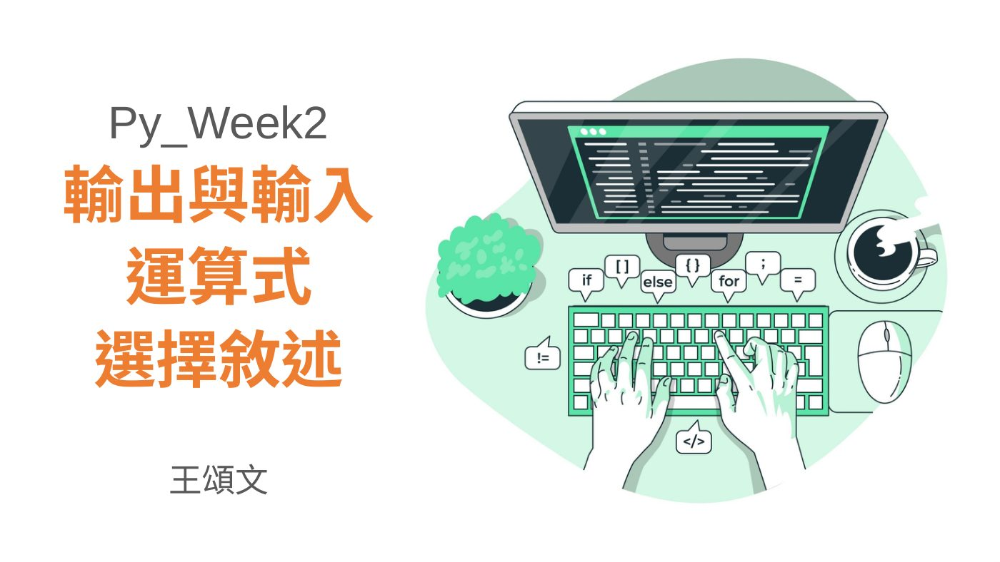

**講義文字（原稿轉錄）**

> Py_Week2輸出與輸入運算式選擇敘述

> 王頌文

<a id="section-2"></a>

## P002 起｜輸出與輸入

### P002｜主題

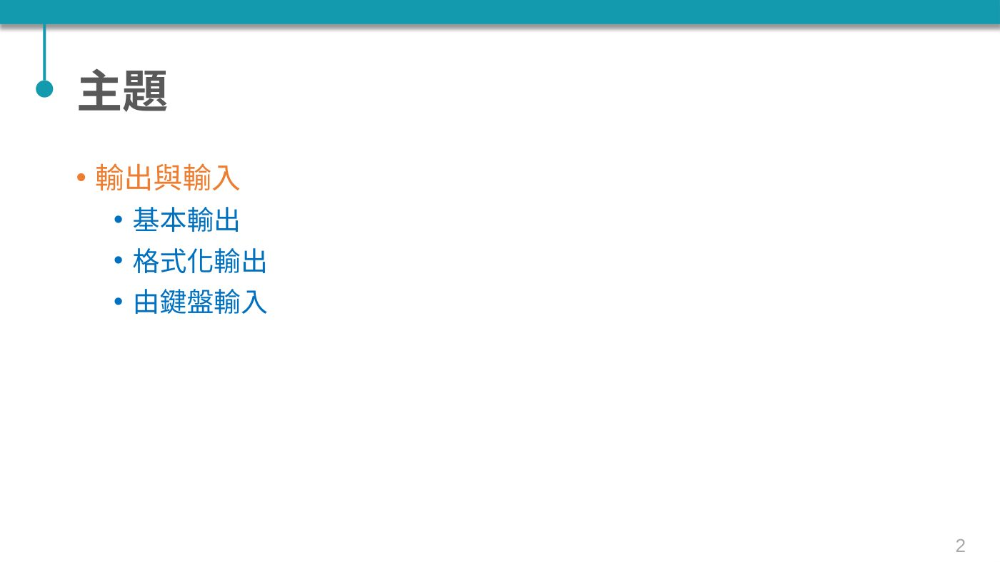

**講義文字（原稿轉錄）**

> 主題

> 輸出與輸入

> 基本輸出

> 格式化輸出

> 由鍵盤輸入

### P003｜數值

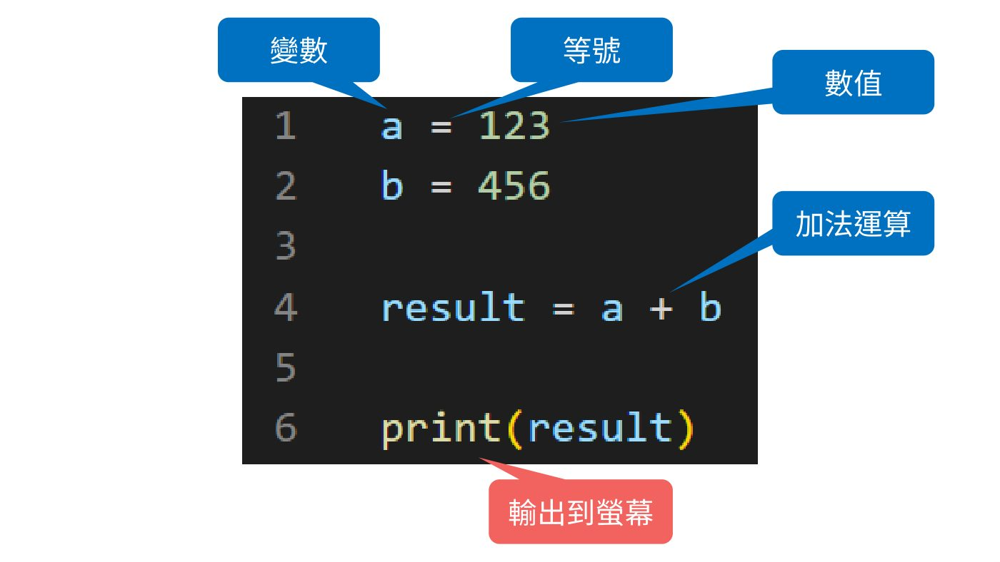

**講義文字（原稿轉錄）**

> 數值

> 等號

> 變數

> 加法運算

> 輸出到螢幕

#### 變數、數值與運算

先計算右側，再將結果指派到左側變數。改變數值後重新執行，觀察輸出。

In [2]:
a = 3
b = 2
result = a + b
print(result)
assert result == 5

5


### P004｜主題

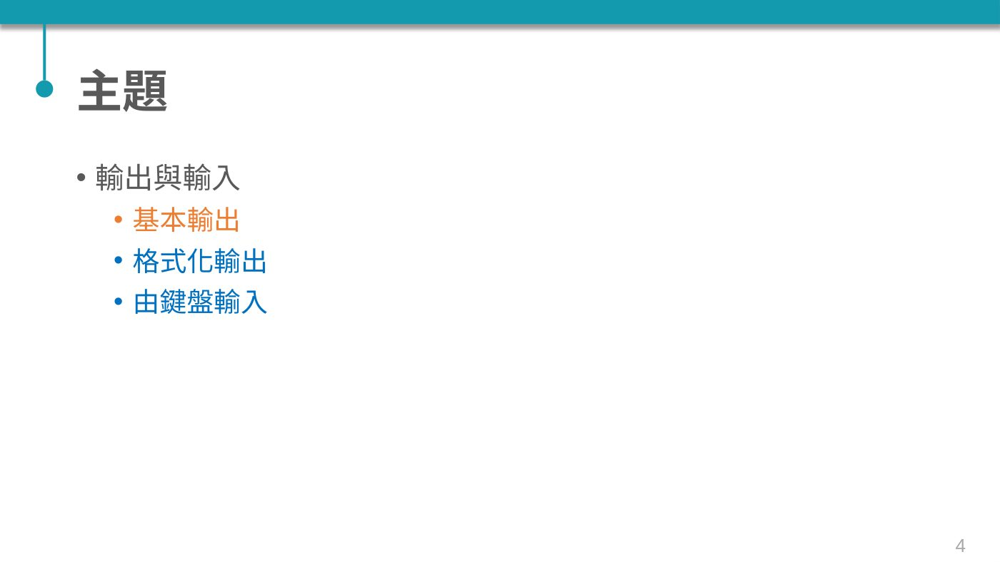

**講義文字（原稿轉錄）**

> 主題

> 輸出與輸入

> 基本輸出

> 格式化輸出

> 由鍵盤輸入

### P005｜print() 的語法

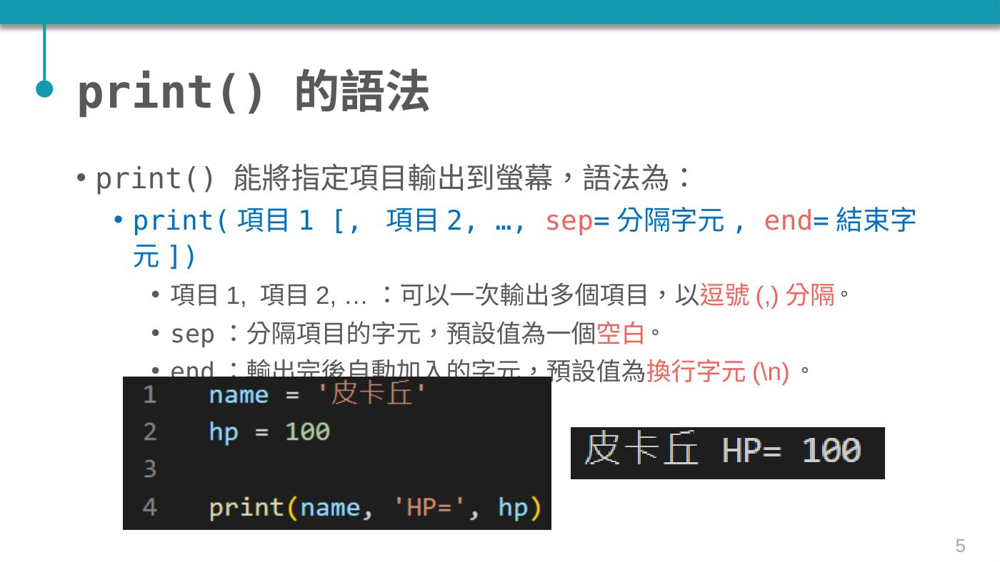

**講義文字（原稿轉錄）**

> print() 的語法

> print() 能將指定項目輸出到螢幕，語法為：

> print(項目1 [, 項目2, …, sep=分隔字元, end=結束字元])

> 項目1, 項目2, …：可以一次輸出多個項目，以逗號(,)分隔。

> sep：分隔項目的字元，預設值為一個空白。

> end：輸出完後自動加入的字元，預設值為換行字元(\n)。

### P006｜更多範例(1/3)

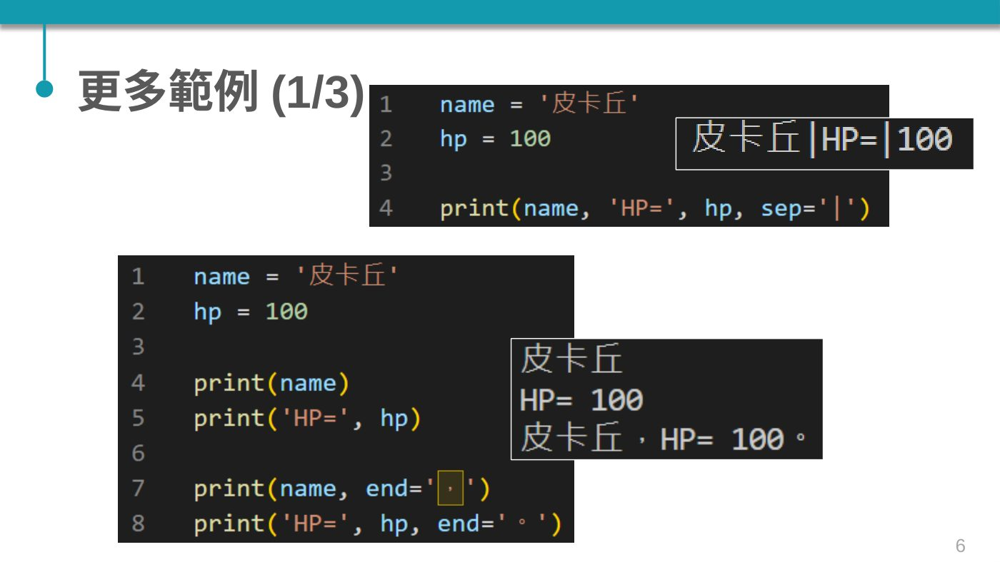

**講義文字（原稿轉錄）**

> 更多範例(1/3)

### P007｜更多範例(2/3)

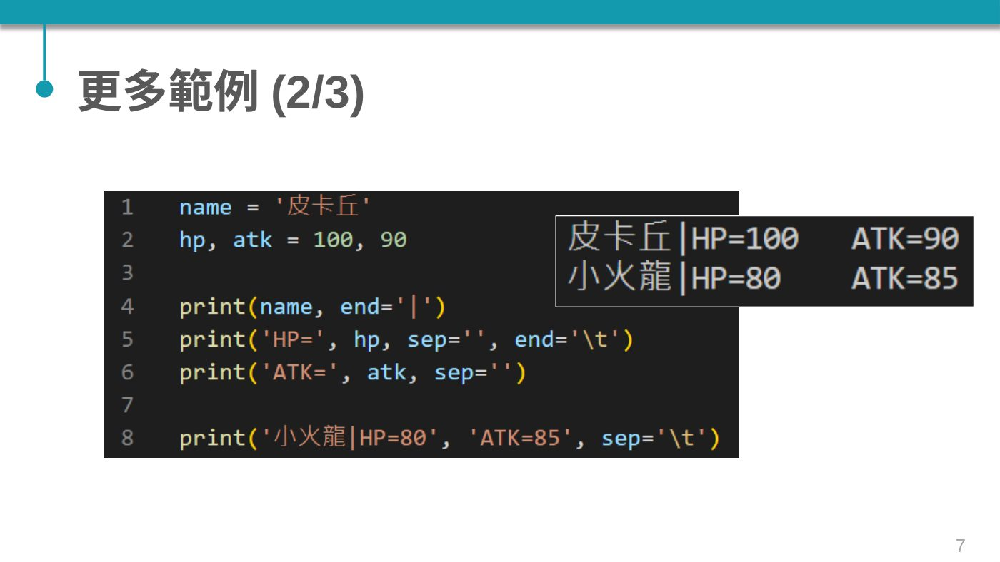

**講義文字（原稿轉錄）**

> 更多範例(2/3)

#### print、sep 與 end

sep 控制多個輸出項目之間的分隔；end 控制本次輸出的結尾。\t 是定位字元，實際對齊效果會受字型影響。

In [3]:
name, hp, atk = '皮卡丘', 100, 90
print(name)
print('HP=', hp)
print(name, 'HP=', hp, sep='|')
print(name, end='|')
print('HP=', hp, sep='', end='\t')
print('ATK=', atk, sep='')
print('小火龍|HP=80', 'ATK=85', sep='\t')

皮卡丘
HP= 100
皮卡丘|HP=|100
皮卡丘|HP=100	ATK=90
小火龍|HP=80	ATK=85


### P008｜更多範例(3/3)

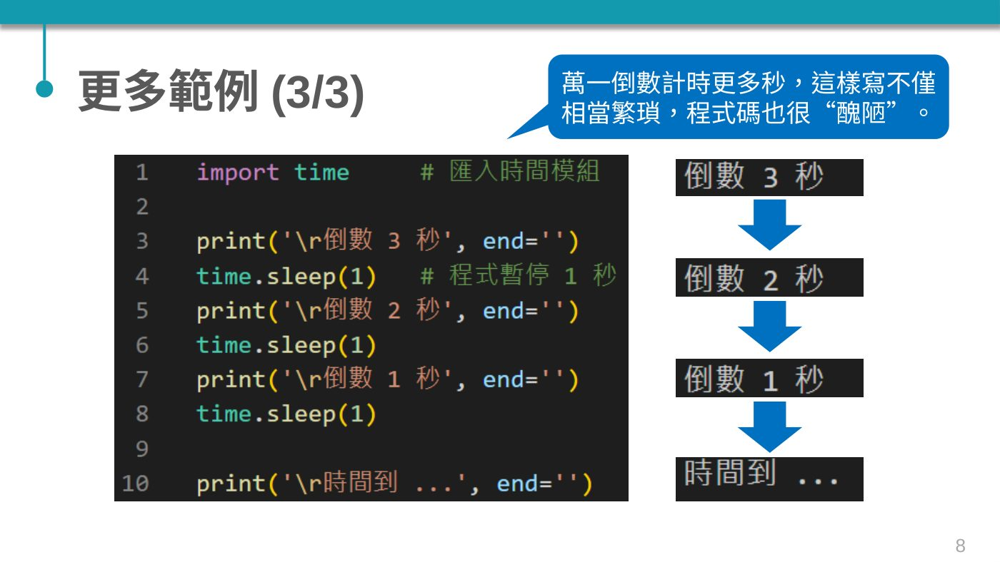

**講義文字（原稿轉錄）**

> 更多範例(3/3)

> 萬一倒數計時更多秒，這樣寫不僅相當繁瑣，程式碼也很“醜陋”。

#### 倒數計時

原講義使用三段重複程式。以下保留此寫法；第三週可用迴圈改寫。縮短等待時間方便全部執行。Colab 對 \r 的呈現可能與終端機不同。

In [11]:
import time
print('\r倒數 3 秒', end=''); time.sleep(1)
print('\r倒數 2 秒', end=''); time.sleep(1)
print('\r倒數 1 秒', end=''); time.sleep(1)
print('\r時間到 …')

時間到 …


### P009｜輸出彩色字體(1/2)

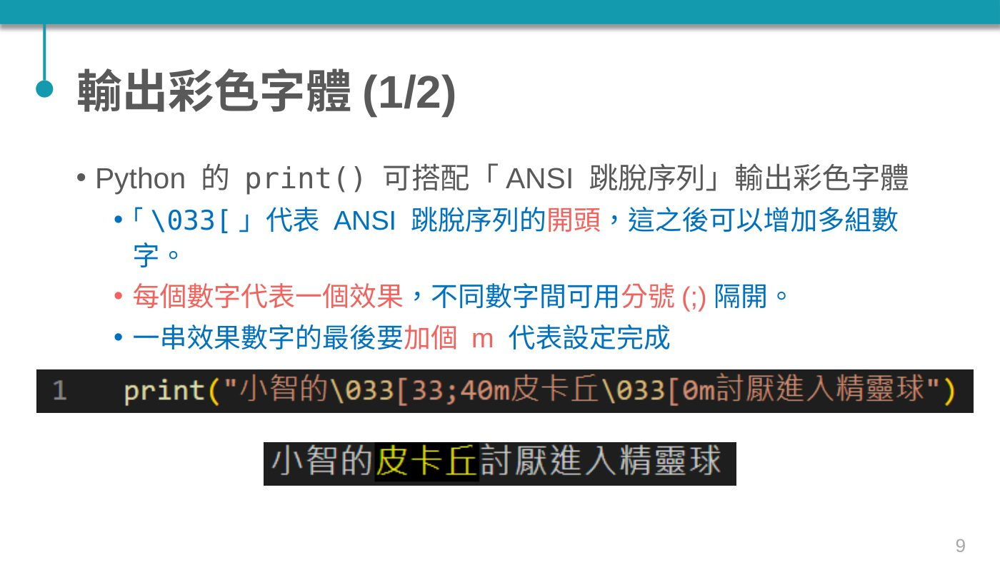

**講義文字（原稿轉錄）**

> 輸出彩色字體(1/2)

> Python 的 print() 可搭配「ANSI 跳脫序列」輸出彩色字體

> 「\033[」代表 ANSI 跳脫序列的開頭，這之後可以增加多組數字。

> 每個數字代表一個效果，不同數字間可用分號(;)隔開。

> 一串效果數字的最後要加個 m 代表設定完成

### P010｜輸出彩色字體(2/2)

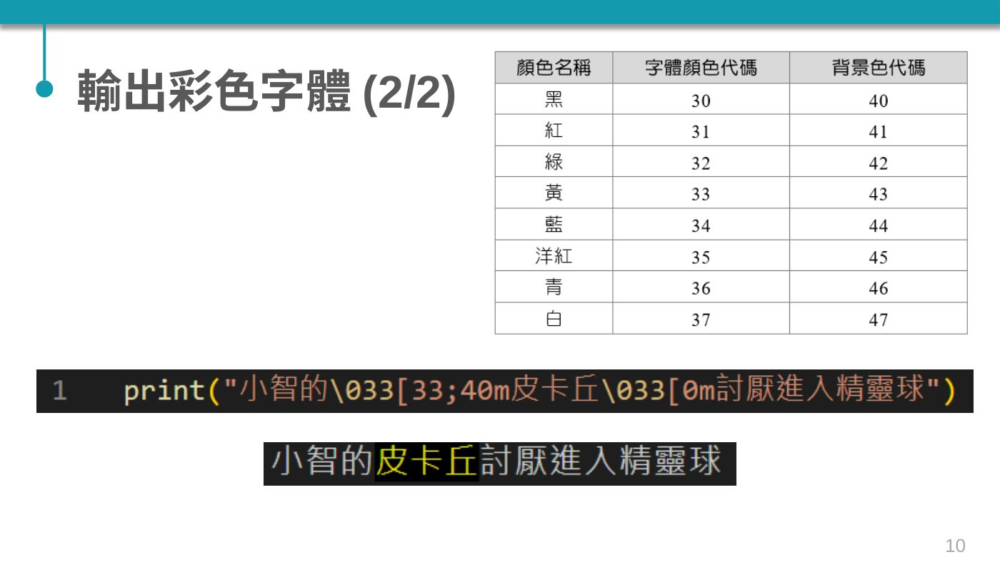

**講義文字（原稿轉錄）**

> 輸出彩色字體(2/2)

### P011｜設定字體效果

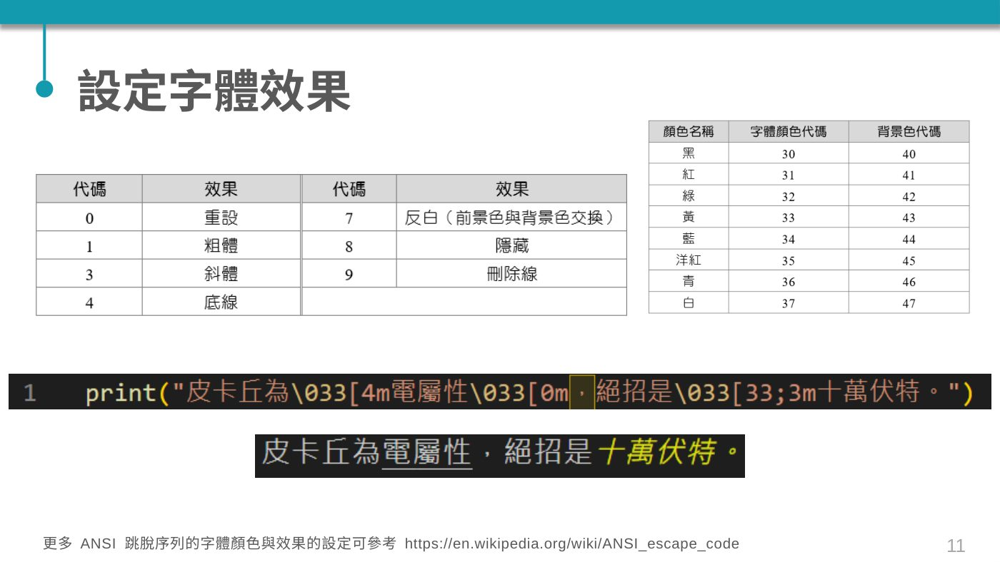

**講義文字（原稿轉錄）**

> 設定字體效果

> 更多 ANSI 跳脫序列的字體顏色與效果的設定可參考 https://en.wikipedia.org/wiki/ANSI_escape_code

#### ANSI 彩色輸出

效果結束後使用 0m 重設。瀏覽器可能不支援所有終端機效果；這不代表程式錯誤。

In [12]:
print('小智的\033[33;40m皮卡丘\033[0m討厭進入精靈球')
print('皮卡丘為\033[4m電屬性\033[0m，絕招是\033[33;3m十萬伏特\033[0m。')

小智的皮卡丘討厭進入精靈球
皮卡丘為電屬性，絕招是十萬伏特。


### P012｜主題

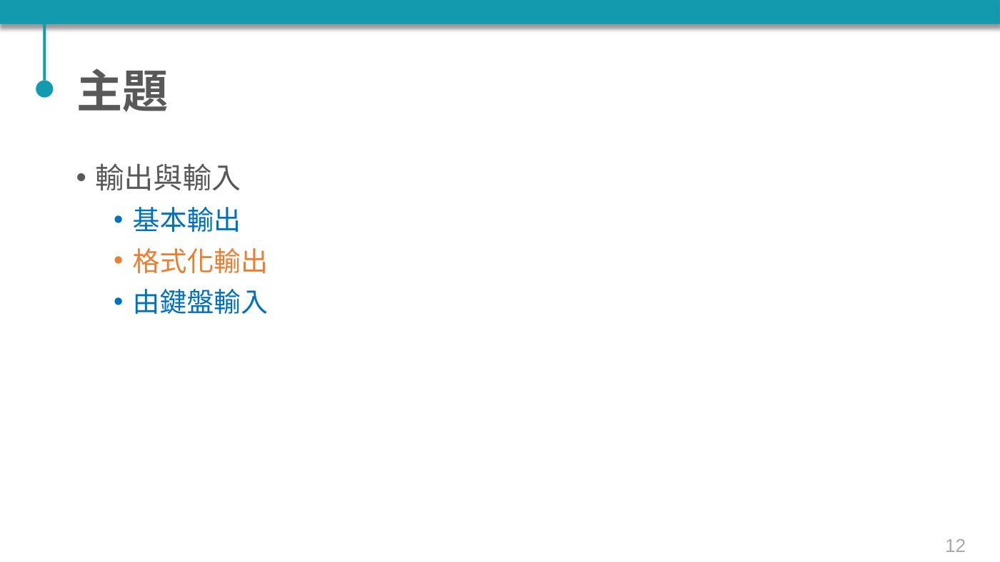

**講義文字（原稿轉錄）**

> 主題

> 輸出與輸入

> 基本輸出

> 格式化輸出

> 由鍵盤輸入

<a id="section-13"></a>

## P013 起｜格式化輸出

### P013｜格式化輸出

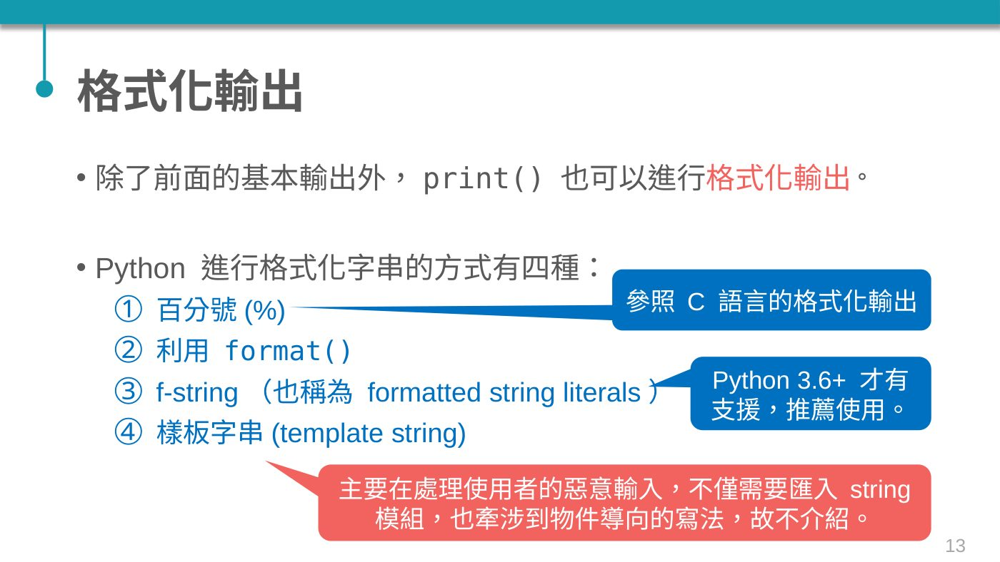

**講義文字（原稿轉錄）**

> 格式化輸出

> 除了前面的基本輸出外，print() 也可以進行格式化輸出。

> Python 進行格式化字串的方式有四種：

> 百分號(%)

> 利用 format()

> f-string（也稱為 formatted string literals）

> 樣板字串(template string)

> 參照 C 語言的格式化輸出

> Python 3.6+ 才有支援，推薦使用。

> 主要在處理使用者的惡意輸入，不僅需要匯入 string 模組，也牽涉到物件導向的寫法，故不介紹。

### P014｜百分號(1/4)

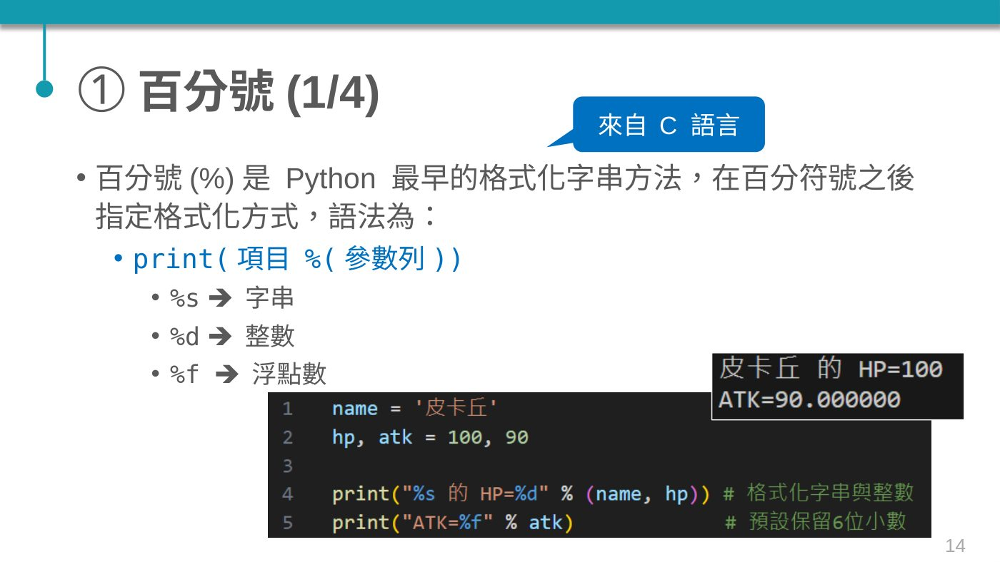

**講義文字（原稿轉錄）**

> 百分號(1/4)

> 百分號(%)是 Python 最早的格式化字串方法，在百分符號之後指定格式化方式，語法為：

> print(項目 %(參數列))

> %s  字串

> %d  整數

> %f   浮點數

> 來自 C 語言

In [13]:
name = '皮卡丘'
hp, atk = 100, 90

print("%s 的 HP=%d" % (name, hp))
print("ATK=%f" % atk)

皮卡丘 的 HP=100
ATK=90.000000


### P015｜百分號(2/4)

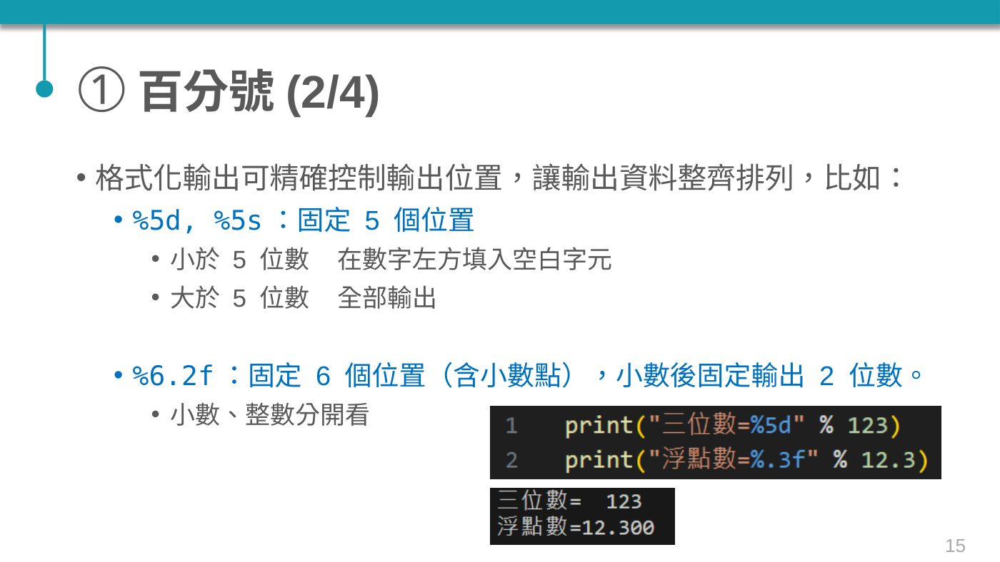

**講義文字（原稿轉錄）**

> 百分號(2/4)

> 格式化輸出可精確控制輸出位置，讓輸出資料整齊排列，比如：

> %5d, %5s：固定 5 個位置

> 小於 5 位數  在數字左方填入空白字元

> 大於 5 位數  全部輸出

> %6.2f：固定 6 個位置（含小數點），小數後固定輸出 2 位數。

> 小數、整數分開看

In [14]:
print("三位數=%5d" % 123)
print("浮點數=%.3f" % 12.3)

三位數=  123
浮點數=12.300


### P016｜百分號(3/4)

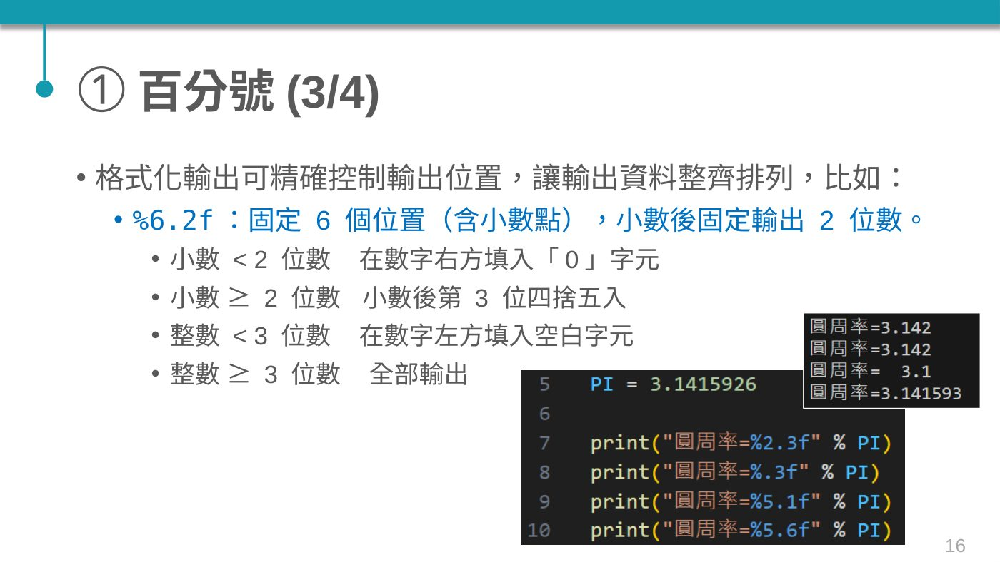

**講義文字（原稿轉錄）**

> 百分號(3/4)

> 格式化輸出可精確控制輸出位置，讓輸出資料整齊排列，比如：

> %6.2f：固定 6 個位置（含小數點），小數後固定輸出 2 位數。

> 小數 &lt; 2 位數  在數字右方填入「0」字元

> 小數 ≥ 2 位數 小數後第 3 位四捨五入

> 整數 &lt; 3 位數  在數字左方填入空白字元

> 整數 ≥ 3 位數  全部輸出

In [15]:
PI = 3.1415926

print("圓周率=%2.3f" % PI)
print("圓周率=%.3f" % PI)
print("圓周率=%5.1f" % PI)
print("圓周率=%5.6f" % PI)

圓周率=3.142
圓周率=3.142
圓周率=  3.1
圓周率=3.141593


#### 百分號格式化

寬度是「最少」位置，不會截斷過長數字；精度 .2 表示小數點後兩位。中文字的顯示寬度不一定等於一個英文字元。

In [16]:
print('%s，攻擊力=%d，萌度=%.2f。' % ('喬巴', 80, 95.5678))
print('|%5d|%5d|' % (12, 123456))
print('|%6.2f|%6.2f|' % (3.1, 1234.567))

喬巴，攻擊力=80，萌度=95.57。
|   12|123456|
|  3.10|1234.57|


### P017｜浮點數精確度問題

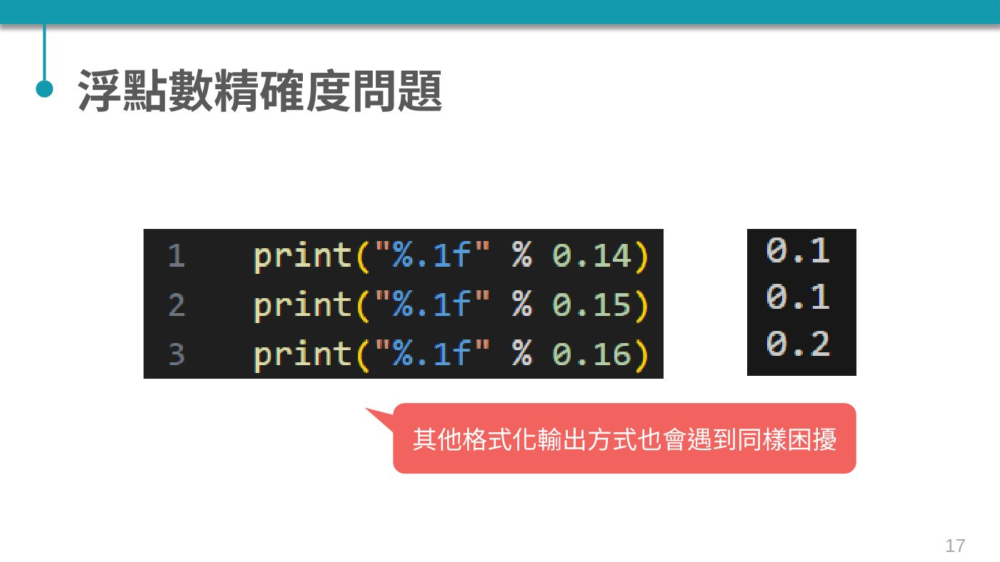

**講義文字（原稿轉錄）**

> 浮點數精確度問題

> 其他格式化輸出方式也會遇到同樣困擾

#### 浮點數與捨入

補充：二進位浮點數不一定精確表示十進位小數；Python 的 round 在正好一半時採最接近的偶數。需要十進位四捨五入規則時可用 Decimal。

這是一個非常經典且重要的問題！

之所以 "%.1f" % 0.15 輸出的結果是 0.1 而不是 0.2，主要原因在於**「二進位浮點數的精確度限制」**：

無法精確表示十進位小數： 我們在程式中寫的 0.15，在電腦底層以二進位（IEEE 754 雙精度浮點數）儲存時，無法被完美精確地表示。實際上，0.15 在電腦內部真正儲存的數值大約是： 0.149999999999999994448884876874... 這個值其實比 0.15 還要小一點點。

四捨五入的判斷： 當您使用 '%.1f' % 0.15 進行格式化時，Python 會根據它在底層實際儲存的值來做四捨五入。因為底層儲存的數值（約 0.14999...）小於 0.15（未達半數），所以在取小數點後一位時，它自然就被捨去，變成了 0.1。

💡 如何驗證與解決？
您可以利用 decimal 套件中的 Decimal 來觀察它真正的樣子，或者使用 Decimal 來進行精確的十進位四捨五入（如您講義中 w2-0034 儲存格所示）：

查看真實儲存值：

```
from decimal
import Decimal
print(Decimal(0.15))
# 輸出：0.1499999999999999944488848768742172978818416595458984375
```

正確進行十進位四捨五入： 如果需要精確的十進位四捨五入，必須將數字以字串形式傳給 Decimal，這樣才能避免浮點數轉換時的精確度失真：
```
from decimal import Decimal, ROUND_HALF_UP
# 使用字串 '0.15' 來建立 Decimal 物件
res = Decimal('0.15').quantize(Decimal('0.1'), rounding=ROUND_HALF_UP)
print(res) # 輸出：0.2
```


In [17]:
from decimal import Decimal, ROUND_HALF_UP
print('%.1f' % 0.14, '%.1f' % 0.15, '%.1f' % 0.16)
print(round(2.5), round(3.5))
print(Decimal('0.15').quantize(Decimal('0.1'), rounding=ROUND_HALF_UP))

0.1 0.1 0.2
2 4
0.2


### P018｜百分號(4/4)

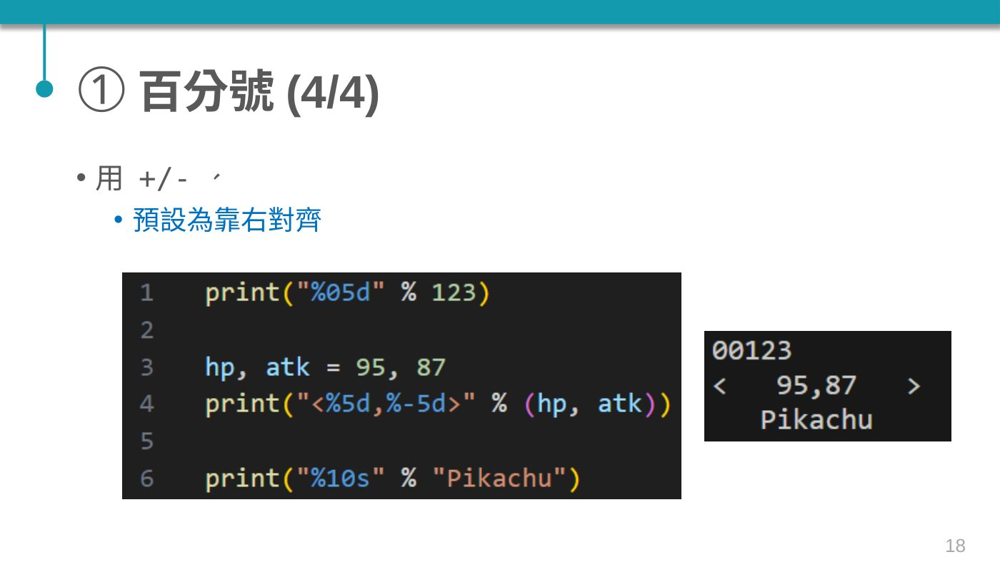

**講義文字（原稿轉錄）**

> 百分號(4/4)

> 用 +/- 控制靠左、右對齊

> 預設為靠右對齊

#### 靠左與正負號

勘誤：% 的負號表示靠左；加號表示強制顯示正負號，並不是「靠右」設定。未指定負號時預設靠右。

In [19]:
print('|%5d|%-5d|%+5d|' % (12, 12, 12))
assert '%+d' % 12 == '+12'

|   12|12   |  +12|


### P019｜format() (1/2)

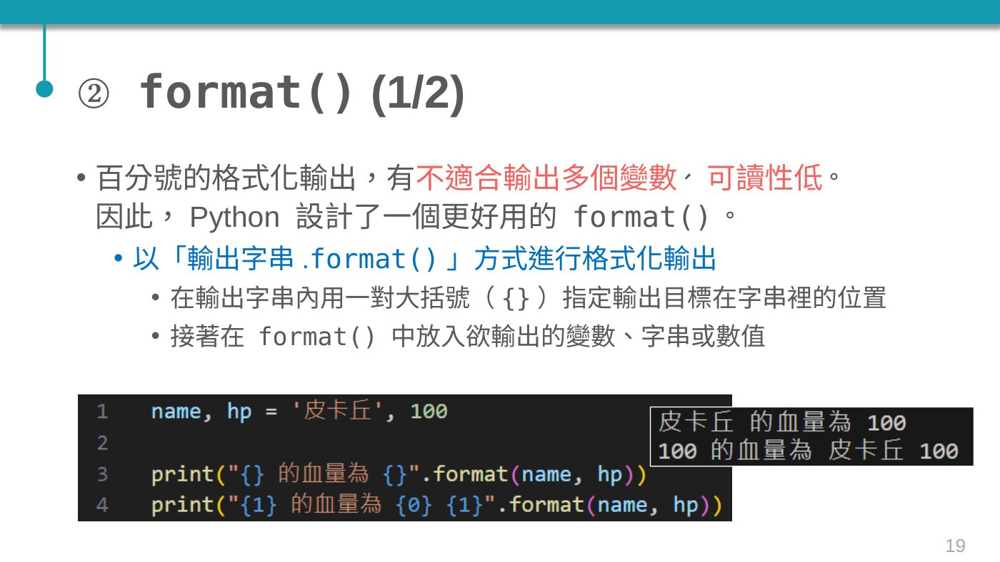

**講義文字（原稿轉錄）**

> format() (1/2)

> 百分號的格式化輸出，有不適合輸出多個變數、可讀性低等缺點。因此，Python 設計了一個更好用的 format()。

> 以「輸出字串.format()」方式進行格式化輸出

> 在輸出字串內用一對大括號（{}）指定輸出目標在字串裡的位置

> 接著在 format() 中放入欲輸出的變數、字串或數值

In [25]:
name, hp = '皮卡丘', 100

print("{} 的血量為{}".format(name, hp))
print("{1} 的血量為{0}{1}".format(name, hp))

皮卡丘 的血量為100
100 的血量為皮卡丘100


### P020｜format() (2/2)

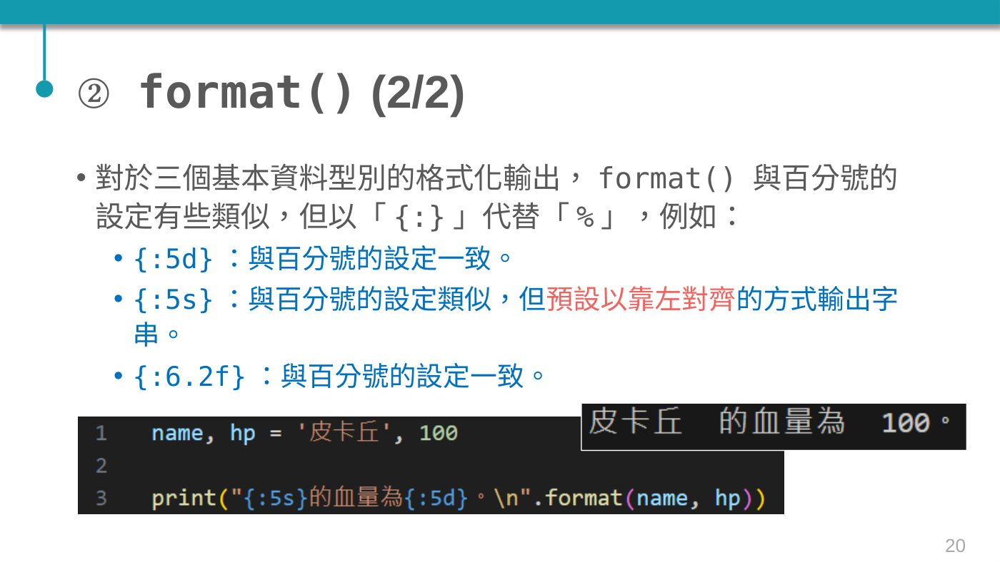

**講義文字（原稿轉錄）**

> format() (2/2)

> 對於三個基本資料型別的格式化輸出，format() 與百分號的設定有些類似，但以「{:}」代替「%」，例如：

> {:5d}：與百分號的設定一致。

> {:5s}：與百分號的設定類似，但預設以靠左對齊的方式輸出字串。

> {:6.2f}：與百分號的設定一致。

In [23]:
name, hp = '皮卡丘', 100

print("{:5s} 的血量為{:5d}。\n".format(name, hp))

皮卡丘   的血量為  100。



### P021｜format() 範例(1/3)

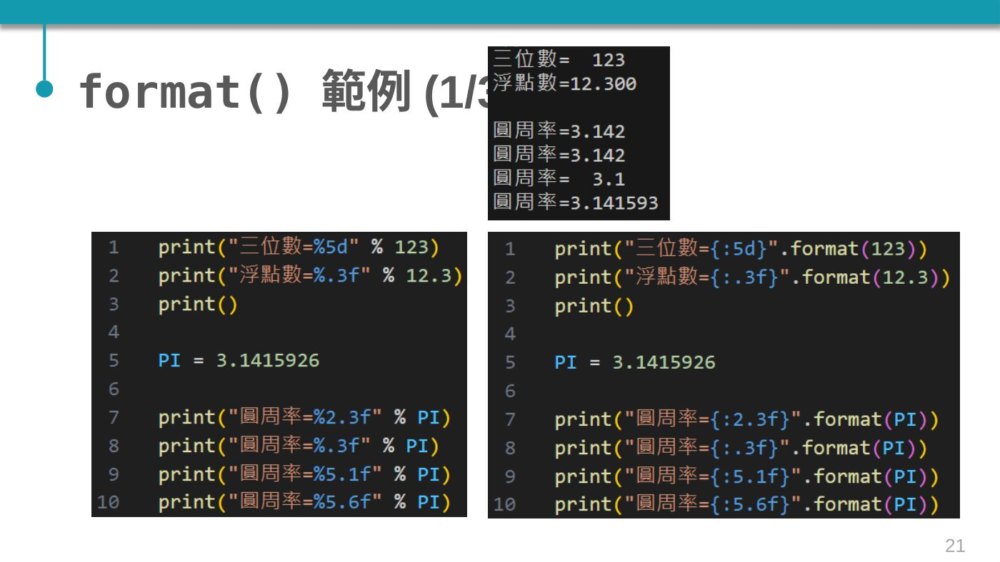

**講義文字（原稿轉錄）**

> format() 範例(1/3)

### P022｜format() 範例(2/3)

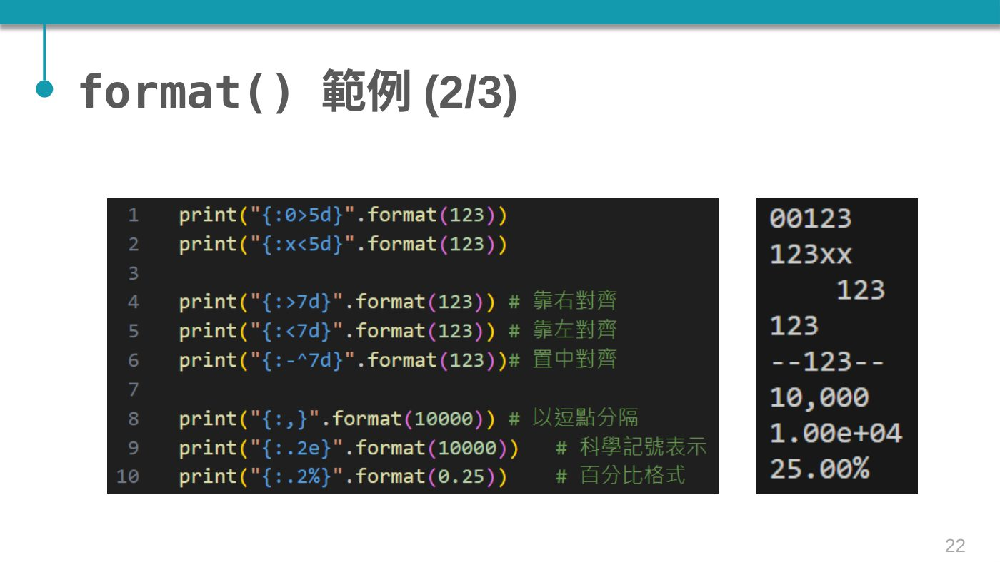

**講義文字（原稿轉錄）**

> format() 範例(2/3)

### P023｜format() 範例(3/3)

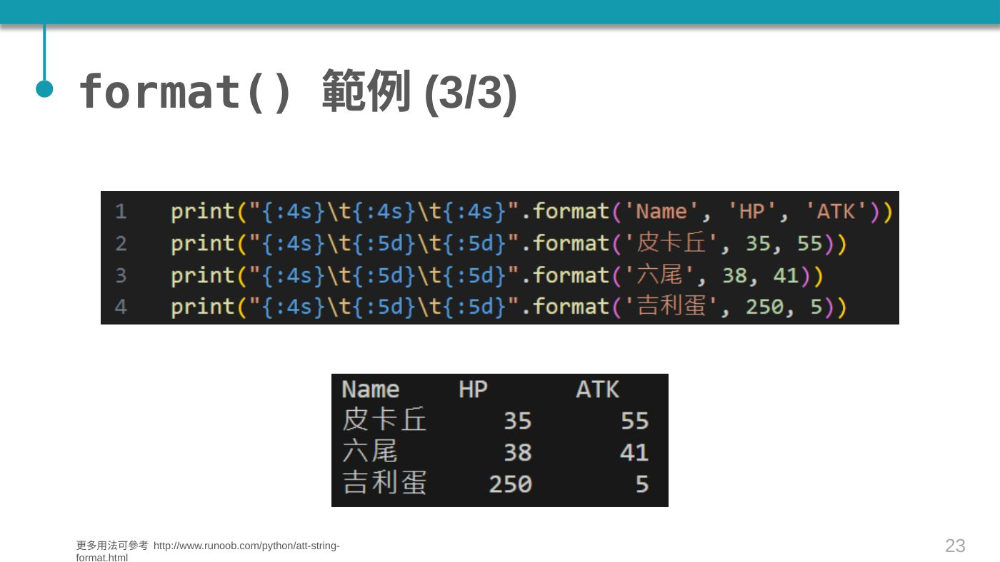

**講義文字（原稿轉錄）**

> format() 範例(3/3)

> 更多用法可參考 http://www.runoob.com/python/att-string-format.html

#### format 完整範例

依序觀察位置參數、寬度、精度、補字元、對齊、千分位、科學記號與百分比。

In [26]:
PI = 3.1415926
print('三位數={:5d}，浮點數={:.3f}'.format(123, 12.3))
print('{:2.3f} {:3f} {:5.1f} {:5.6f}'.format(PI, PI, PI, PI))
print('{:0>5d} {:x<5d} {:>7d} {:<7d} {:-^7d}'.format(123,123,123,123,123))
print('{:,} {:.2e} {:.2%}'.format(10000,10000,0.25))
print('{1}，{0}'.format('你好','Python'))
print('{:4s}\t{:4s}\t{:4s}'.format('Name','HP','ATK'))
print('{:4s}\t{:5d}\t{:5d}'.format('皮卡丘',35,55))
print('{:4s}\t{:5d}\t{:5d}'.format('六尾',38,41))
print('{:4s}\t{:5d}\t{:5d}'.format('吉利蛋',250,5))

三位數=  123，浮點數=12.300
3.142 3.141593   3.1 3.141593
00123 123xx     123 123     --123--
10,000 1.00e+04 25.00%
Python，你好
Name	HP  	ATK 
皮卡丘 	   35	   55
六尾  	   38	   41
吉利蛋 	  250	    5


### P024｜f-string (1/2)

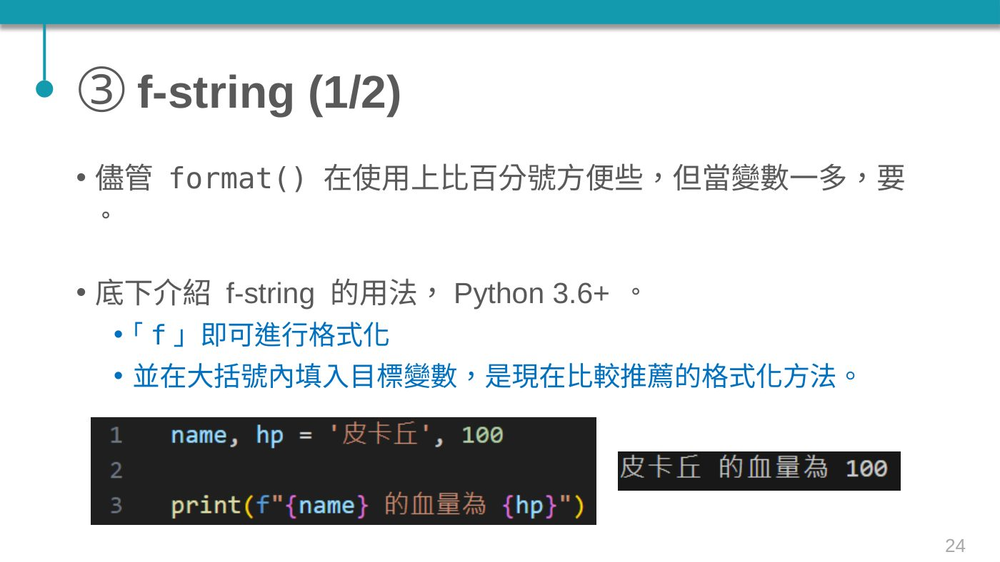

**講義文字（原稿轉錄）**

> f-string (1/2)

> 儘管 format() 在使用上比百分號方便些，但當變數一多，要撰寫的程式碼仍然相當冗長。

> 底下介紹 f-string 的用法，Python 3.6+ 才有支援。

> 在輸出字串前加上「f」即可進行格式化

> 並在大括號內填入目標變數，是現在比較推薦的格式化方法。

### P025｜f-string (2/2)

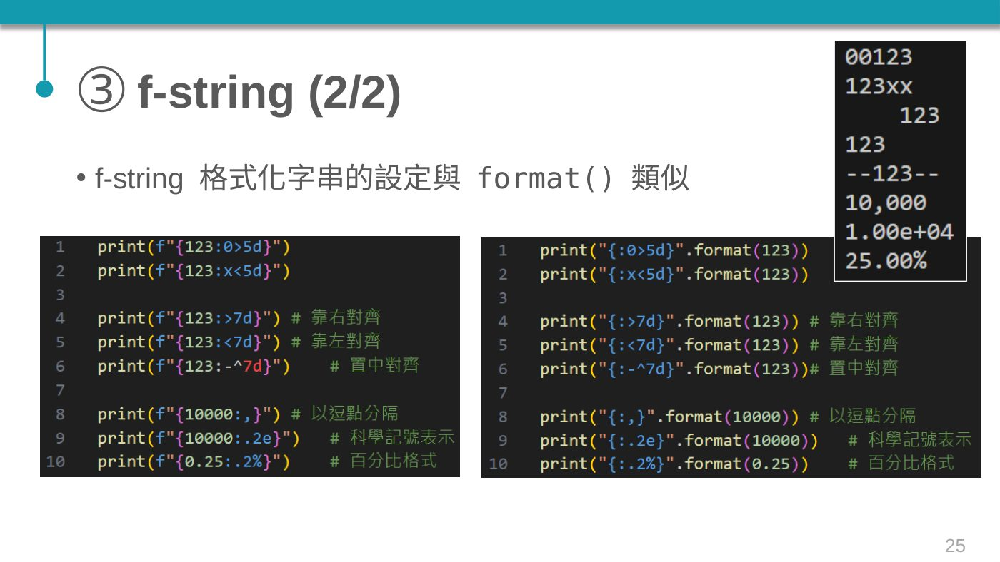

**講義文字（原稿轉錄）**

> f-string (2/2)

> f-string 格式化字串的設定與 format() 類似

### P026｜f-string 範例

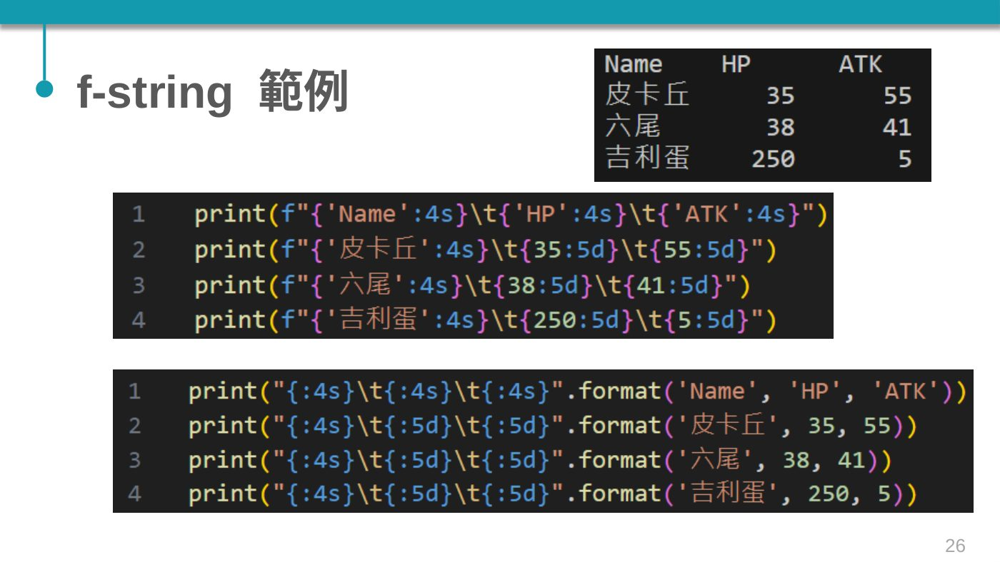

**講義文字（原稿轉錄）**

> f-string 範例

#### f-string 表格

在字串前加 f，括號內可放變數或運算式。這裡改用變數，修改數值後更容易重用。

In [27]:
name, hp, atk = '皮卡丘', 35, 55
print(f"{'Name':4s}\t{'HP':4s}\t{'ATK':4s}")
print(f'{name:4s}\t{hp:5d}\t{atk:5d}')
print(f"{'六尾':4s}\t{38:5d}\t{41:5d}")
print(f"{'吉利蛋':4s}\t{250:5d}\t{5:5d}")
print(f'HP 加 10 後：{hp + 10}')

Name	HP  	ATK 
皮卡丘 	   35	   55
六尾  	   38	   41
吉利蛋 	  250	    5
HP 加 10 後：45


### P027｜練習

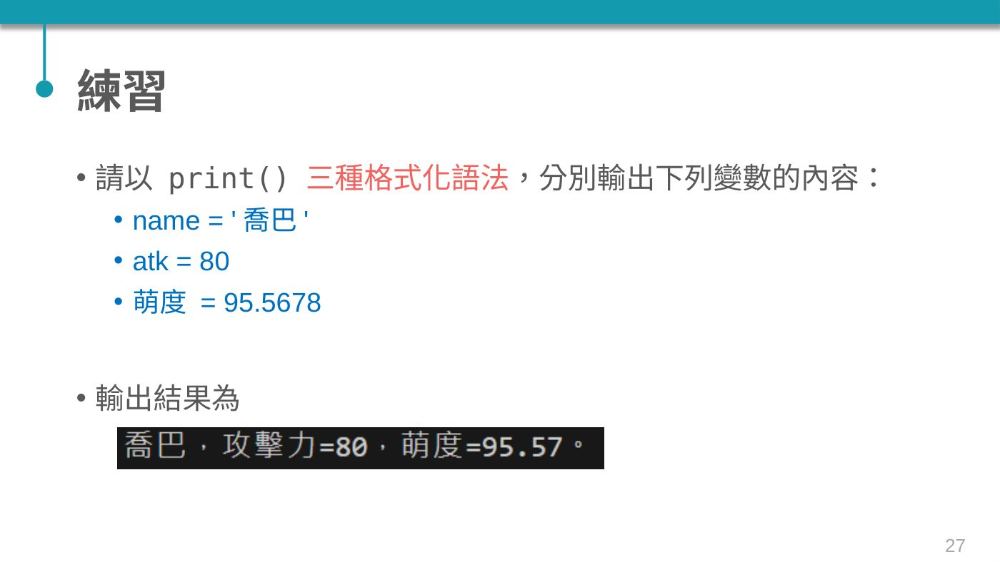

**講義文字（原稿轉錄）**

> 練習

> 請以 print() 三種格式化語法，分別輸出下列變數的內容：

> name = &#x27;喬巴&#x27;

> atk = 80

> 萌度 = 95.5678

> 輸出結果為

<a id="answer-27"></a>

#### 習題解答｜三種格式化

題目：name="喬巴"、atk=80、萌度=95.5678。三種方法皆須得到「喬巴，攻擊力=80，萌度=95.57。」。先自行嘗試，再執行解答。

**先練習**：依上方原題與提示，自行寫出步驟及程式。可修改輸入資料，測試正常值與邊界值。下方空白練習格不影響全部執行。

In [ ]:
# 我的練習區：請在此撰寫程式。
# 建議先寫輸入、處理、輸出三個步驟。

**參考解答與驗收**

觀察印出的結果，並閱讀 `assert` 檢核；若條件不成立，會出現 AssertionError。

In [ ]:
name, atk, 萌度 = '喬巴', 80, 95.5678
s1 = '%s，攻擊力=%d，萌度=%.2f。' % (name, atk, 萌度)
s2 = '{}，攻擊力={}，萌度={:.2f}。'.format(name, atk, 萌度)
s3 = f'{name}，攻擊力={atk}，萌度={萌度:.2f}。'
print(s1); print(s2); print(s3)
assert s1 == s2 == s3 == '喬巴，攻擊力=80，萌度=95.57。'

喬巴，攻擊力=80，萌度=95.57。
喬巴，攻擊力=80，萌度=95.57。
喬巴，攻擊力=80，萌度=95.57。


<a id="section-28"></a>

## P028 起｜鍵盤輸入與資料轉換

### P028｜主題

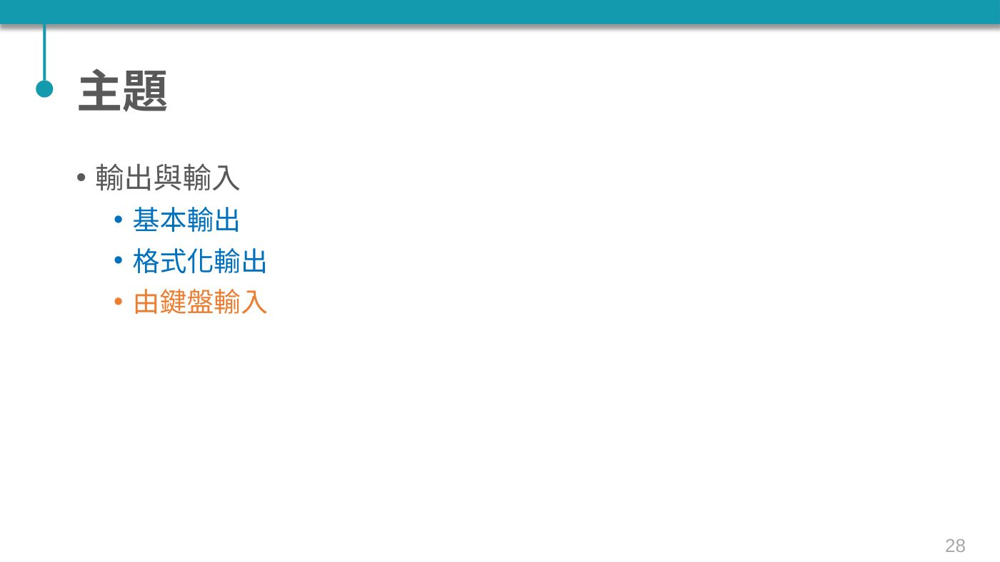

**講義文字（原稿轉錄）**

> 主題

> 輸出與輸入

> 基本輸出

> 格式化輸出

> 由鍵盤輸入

### P029｜輸入資料

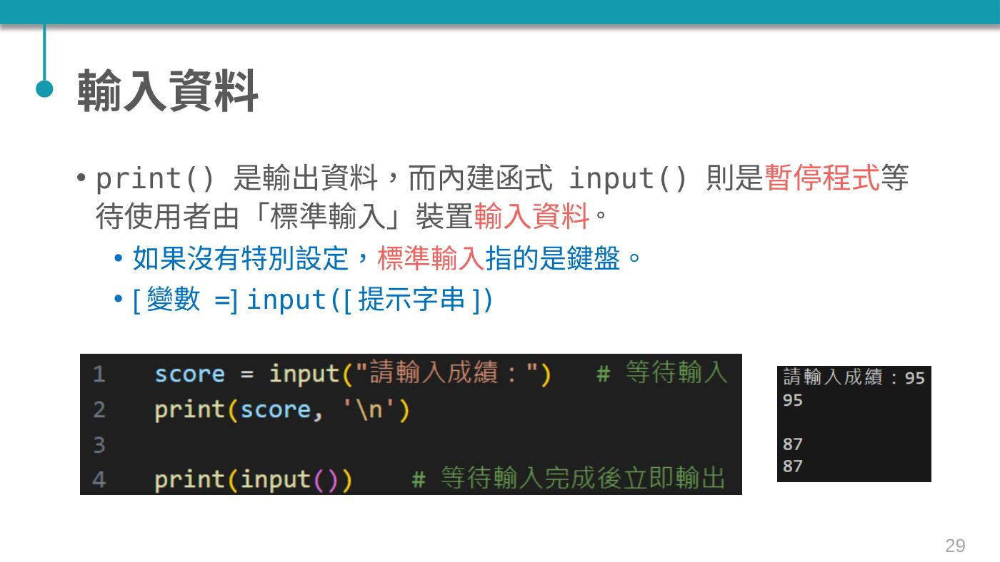

**講義文字（原稿轉錄）**

> 輸入資料

> print() 是輸出資料，而內建函式 input() 則是暫停程式等待使用者由「標準輸入」裝置輸入資料。

> 如果沒有特別設定，標準輸入指的是鍵盤。

> [變數 =] input([提示字串])

In [29]:
score = input("請輸入成績：")
print(score, '\n')

請輸入成績：95
95 



In [30]:
print(input())

85
85


### P030｜注意資料型別

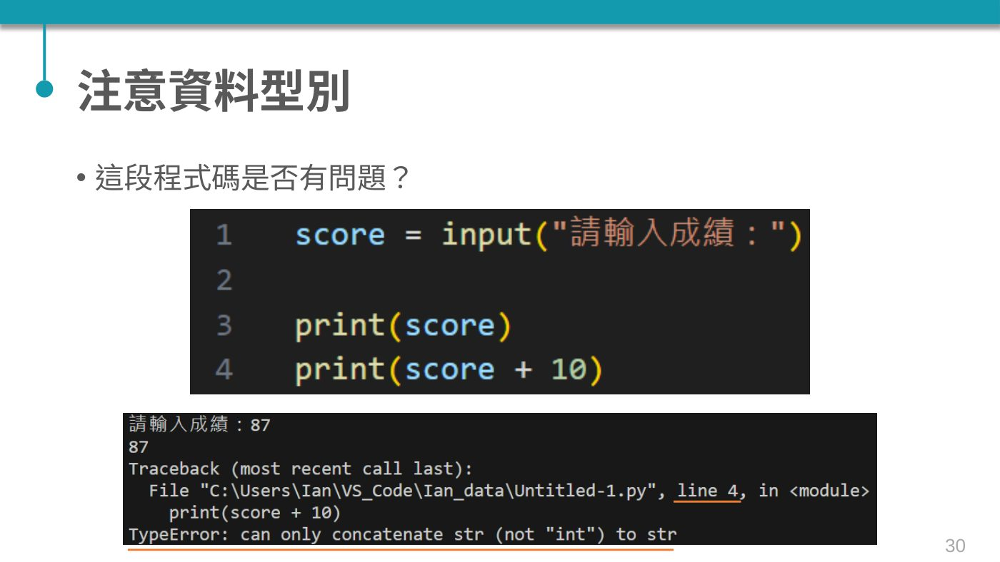

**講義文字（原稿轉錄）**

> 注意資料型別

> 這段程式碼是否有問題？

In [31]:
score = input("請輸入成績：")
print(score, '\n')
print(score + 10)

請輸入成績：97
97 



TypeError: can only concatenate str (not "int") to str

### P031｜修正方式

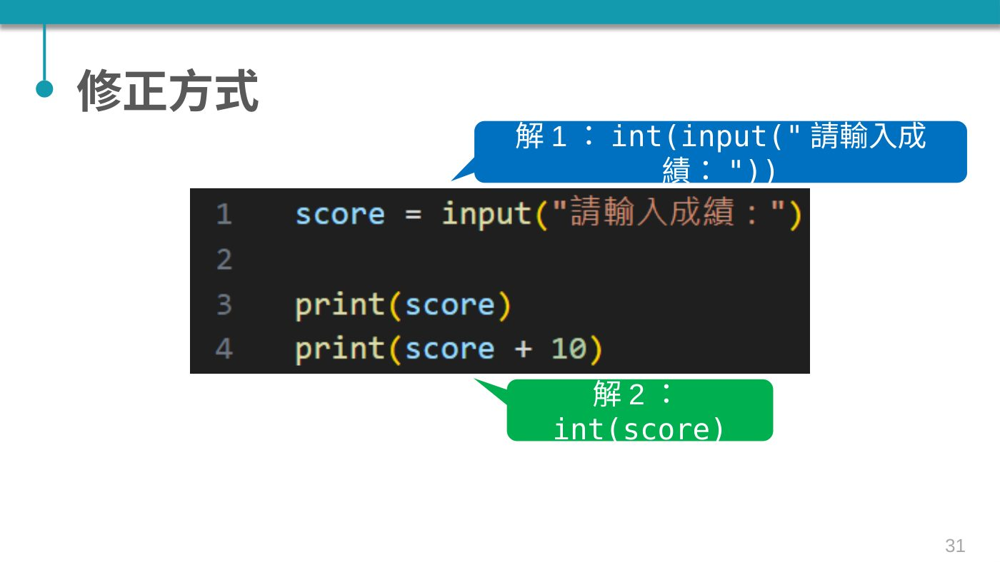

**講義文字（原稿轉錄）**

> 修正方式

> 解1：int(input(&quot;請輸入成績：&quot;))

> 解2：int(score)

In [32]:
score = int(input("請輸入成績："))
print(score, '\n')
print(score + 10)

請輸入成績：97
97 

107


In [33]:
score = input("請輸入成績：")
print(score, '\n')
print(int(score) + 10)

請輸入成績：97
97 

107


### P032｜這有點問題 …

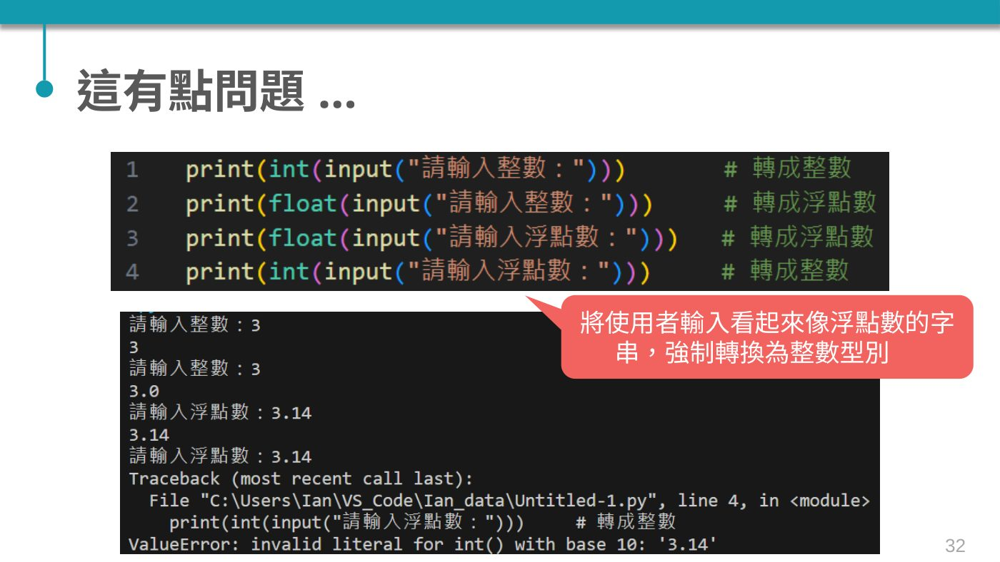

**講義文字（原稿轉錄）**

> 這有點問題 …

> 將使用者輸入看起來像浮點數的字串，強制轉換為整數型別 

In [34]:
print(int(input("請輸入整數：")))  # 輸入：3，轉成整數
print(float(input("請輸入整數：")))  # 輸入：3，轉成浮點數
print(float(input("請輸入浮點數：")))  # 輸入：3.14，轉成浮點數
print(int(input("請輸入浮點數：")))  # 輸入：3.14，轉成整數

請輸入整數：3
3
請輸入整數：3
3.0
請輸入整數：3.14
3.14
請輸入整數：3.14


ValueError: invalid literal for int() with base 10: '3.14'

這個錯誤 ValueError: invalid literal for int() with base 10: '3.14' 產生的原因非常簡單且常見：

##核心原因：int() 無法直接解析含有小數點的「字串」
當您在第四行輸入 3.14 時：

input() 函數會將您的輸入接收為字串類型，也就是 '3.14'。
接著，您試圖使用 int('3.14') 將這個字串強制轉換成整數。
Python 的 int() 函數在處理字串時，預設字串內只能含有整數數字（如 '3'）。一旦字串中出現了小數點 . 或其他非數字字元，int() 就不知道該如何解析它，因此會直接拋出 ValueError（數值錯誤）。

###為什麼 float() 卻可以？

在第三行中，您輸入 3.14 得到字串 '3.14'，傳給 float('3.14') 時，因為 float() 本身就是設計來解析小數的，所以可以順利轉換為浮點數 3.14。
甚至如果您輸入整數 3 得到字串 '3'，傳給 float('3') 也行，它會自動幫您加上小數點變成 3.0。

###解決方法

如果您希望把使用者輸入的 '3.14' 轉換成整數，您需要分兩步進行（如同講義 w2-0063 儲存格最後一行的寫法）：

先轉成浮點數：去掉字串的外殼，將其變成真正的數值類型 3.14。
再轉換成整數：這時 int() 接收到的是數值 3.14（而不是字串），它就能順利將小數點後方的數字無條件捨去，得到 3。


```
# 錯誤寫法
# int("3.14") -> 產生 ValueError

# 正確寫法
print(int(float(input("請輸入浮點數："))))
# 輸入 3.14 -> float("3.14") 得到 3.14 -> int(3.14) 得到 3
```


In [35]:
# 正確寫法
print(int(float(input("請輸入浮點數："))))
# 輸入 3.14 -> float("3.14") 得到 3.14 -> int(3.14) 得到 3

請輸入浮點數：3.14
3


#### input 與型別轉換

input 回傳字串。這裡的 ask 在示範模式供應預設輸入；開啟互動模式後會呼叫真正的 input。刻意的錯誤以 try/except 顯示，避免中止整本教材。

In [ ]:
ask = make_input(['87', '3.14'])
score = ask('請輸入成績：')
print(type(score).__name__)
try:
    print(score + 10)
except TypeError as error:
    print('預期的 TypeError：', error)
print(int(score) + 10)
raw = ask('請輸入小數：')
try:
    print(int(raw))
except ValueError as error:
    print('預期的 ValueError：', error)
print(float(raw))
print(int(float(raw)))  # 明確先轉浮點，再向零截斷；會失去小數

請輸入成績：87
str
預期的 TypeError： can only concatenate str (not "int") to str
97
請輸入小數：3.14
預期的 ValueError： invalid literal for int() with base 10: '3.14'
3.14
3


### P033｜判斷小數點

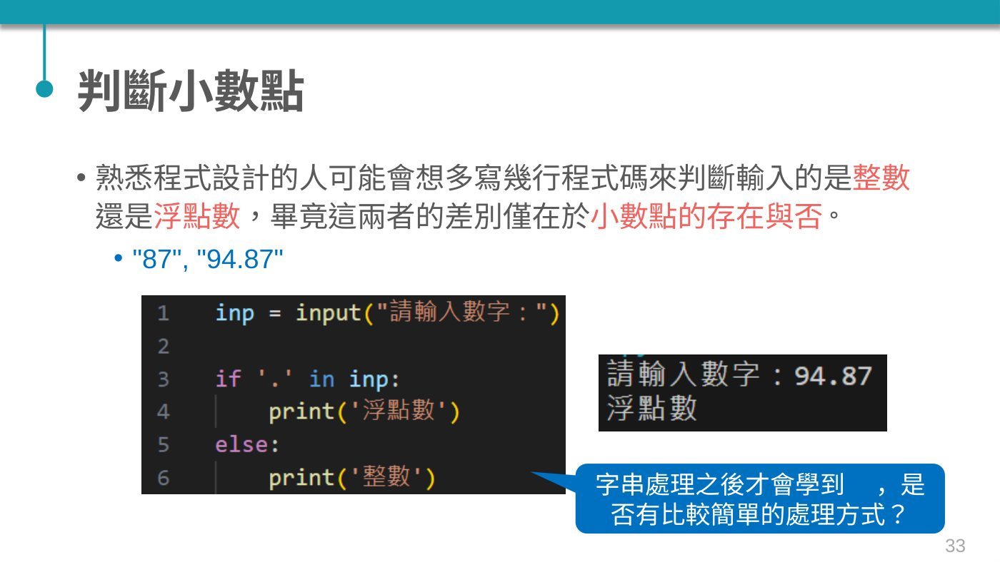

**講義文字（原稿轉錄）**

> 判斷小數點

> 熟悉程式設計的人可能會想多寫幾行程式碼來判斷輸入的是整數還是浮點數，畢竟這兩者的差別僅在於小數點的存在與否。

> &quot;87&quot;, &quot;94.87&quot;

> 字串處理之後才會學到 ，是否有比較簡單的處理方式？

In [37]:
inp = input("請輸入數字：")

if '.' in inp:
  print("浮點數")
else:
  print("整數")

請輸入數字：3
整數


### P034｜內建函式 eval()

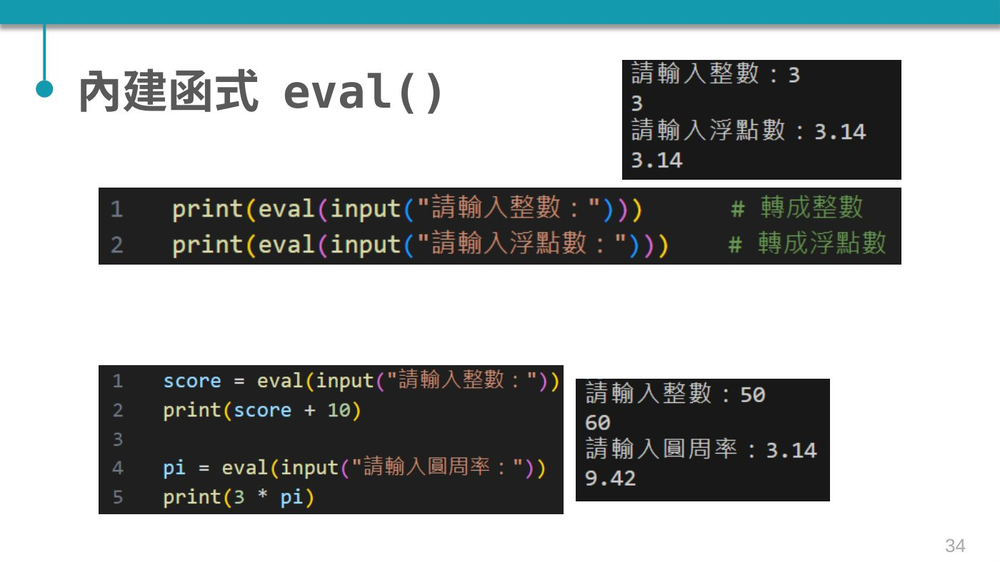

**講義文字（原稿轉錄）**

> 內建函式 eval()

### P035｜eval(運算式)

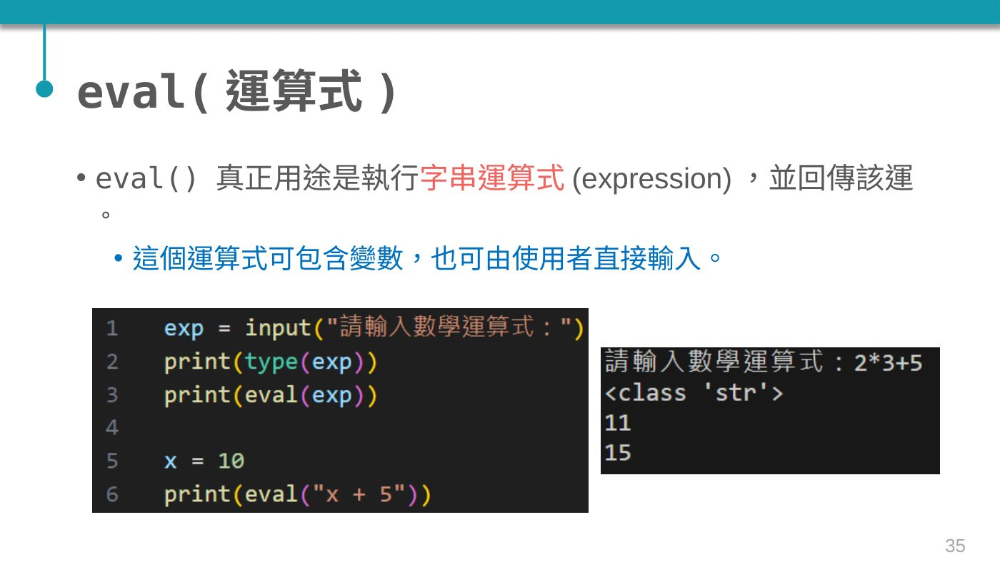

**講義文字（原稿轉錄）**

> eval(運算式)

> eval() 真正用途是執行字串運算式(expression)，並回傳該運算式的運算結果。

> 這個運算式可包含變數，也可由使用者直接輸入。

In [42]:
exp = input("請輸入一個運算式：")
print(type(exp))
print(eval(exp))

x = 10
print(eval("x+10"))

請輸入一個運算式：2*3+5
<class 'str'>
11
20


### P036｜簡化輸入

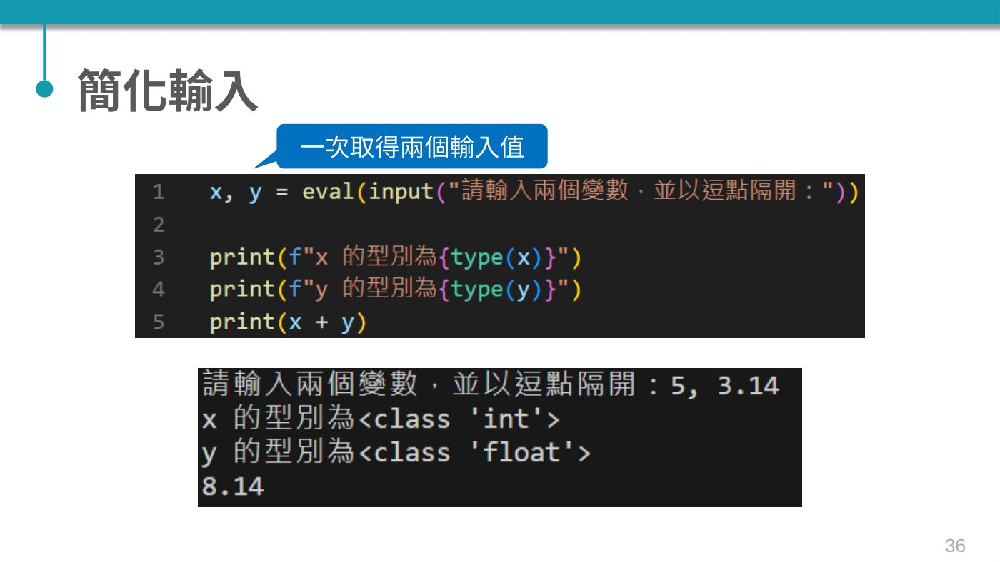

**講義文字（原稿轉錄）**

> 簡化輸入

> 一次取得兩個輸入值

In [44]:
x, y = eval(input("請輸入兩個變數，並以逗點隔開："))

print(f"x 的型別為{type(x)}")
print(f"y 的型別為{type(y)}")
print(x + y)

請輸入兩個變數，並以逗點隔開：5,3.14
x 的型別為<class 'int'>
y 的型別為<class 'float'>
8.14


### P037｜注意

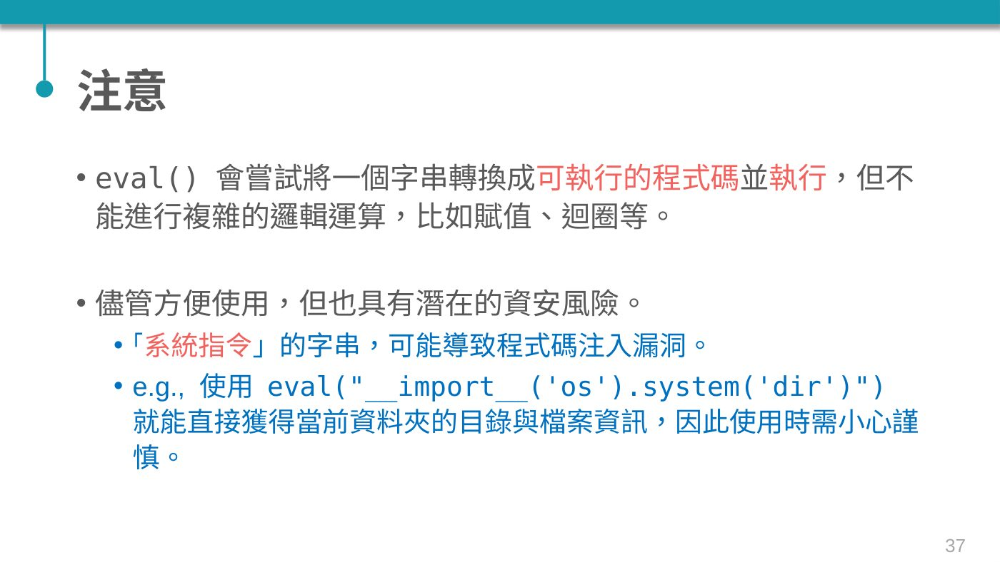

**講義文字（原稿轉錄）**

> 注意

> eval() 會嘗試將一個字串轉換成可執行的程式碼並執行，但不能進行複雜的邏輯運算，比如賦值、迴圈等。

> 儘管方便使用，但也具有潛在的資安風險。

> 使用者惡意輸入類似「系統指令」的字串，可能導致程式碼注入漏洞。

> e.g., 使用 eval(&quot;__import__(&#x27;os&#x27;).system(&#x27;dir&#x27;)&quot;) 就能直接獲得當前資料夾的目錄與檔案資訊，因此使用時需小心謹慎。

In [48]:
import sys
# 將 import('os') 改為內建函數 __import__('os')
# 因為 Colab 環境為 Linux，將 'dir' 指令改為 'ls'
a = eval("__import__('os').system('ls')")
print(a)

0


In [49]:
import os
files = os.listdir('.') # 取得當前目錄下的檔案與資料夾列表
print(files) # 這會是一個 list，例如 ['sample_data', '.config']

['.config', 'sample_data']


In [50]:
import subprocess
# 執行 ls 指令並捕獲輸出內容（轉成 utf-8 字串）
output = subprocess.check_output('ls', text=True)
print(output)

sample_data



#### eval 的意義與輸入替代方案

eval 可求值運算式，不能把賦值陳述式當作運算式。只示範寫死的可信字串；對輸入數值使用 int、float 或 split。Template 是另一種字串替換工具，本身不等於完整的輸入安全機制。

In [40]:
x = 5
print(eval('x + 3'))  # 固定教材字串，不是使用者輸入
ask = make_input(['5, 3.14'])
raw = ask('請輸入兩個數，以逗點隔開：')
x, y = [float(part.strip()) for part in raw.split(',')]
print(x, y, x + y)
assert math.isclose(x+y, 8.14) if not INTERACTIVE else True

8
請輸入兩個數，以逗點隔開：3 , 3.14
3.0 3.14 6.140000000000001


### P038｜練習：計算 BMI

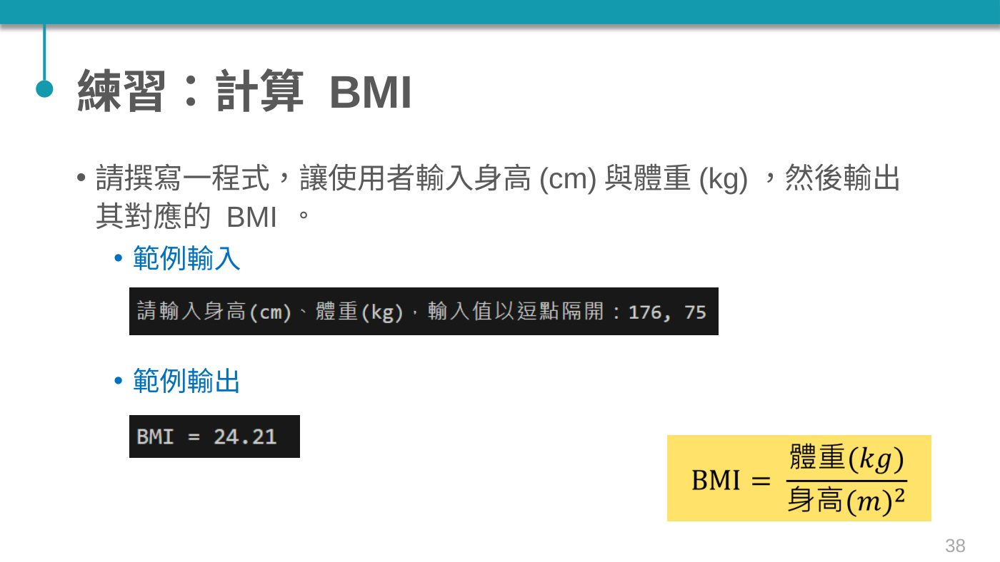

**講義文字（原稿轉錄）**

> 練習：計算 BMI

> 請撰寫一程式，讓使用者輸入身高(cm)與體重(kg)，然後輸出其對應的 BMI 值（四捨五入至小數點後第二位）。

> 範例輸入

> 範例輸出

> BMI= 體重(𝑘𝑔)身高(𝑚)2

<a id="answer-38"></a>

#### 習題解答｜BMI

公式：$BMI=W/(H/100)^2$，H 的單位為公分。解析逗點分隔的兩個數值，檢查身高及體重為正，再格式化到小數後兩位。176,75 應輸出 24.21。

**先練習**：依上方原題與提示，自行寫出步驟及程式。可修改輸入資料，測試正常值與邊界值。下方空白練習格不影響全部執行。

In [ ]:
# 我的練習區：請在此撰寫程式。
# 建議先寫輸入、處理、輸出三個步驟。

**參考解答與驗收**

觀察印出的結果，並閱讀 `assert` 檢核；若條件不成立，會出現 AssertionError。

In [ ]:
def bmi_cm(height, weight):
    if not (math.isfinite(height) and math.isfinite(weight)) or height <= 0 or weight <= 0:
        raise ValueError('身高與體重必須是有限正數')
    return weight / (height / 100) ** 2
ask = make_input(['176, 75'])
height, weight = map(float, ask('身高(cm),體重(kg)：').split(','))
print(f'BMI = {bmi_cm(height, weight):.2f}')
assert f'{bmi_cm(176,75):.2f}' == '24.21'

身高(cm),體重(kg)：176, 75
BMI = 24.21


<a id="section-39"></a>

## P039 起｜運算式與優先順序

### P039｜主題

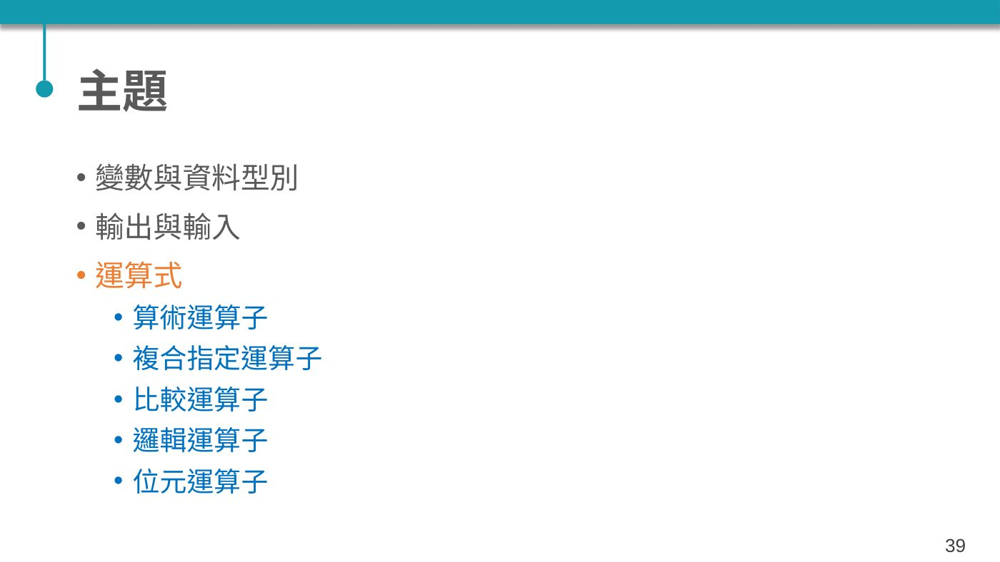

**講義文字（原稿轉錄）**

> 主題

> 變數與資料型別

> 輸出與輸入

> 運算式

> 算術運算子

> 複合指定運算子

> 比較運算子

> 邏輯運算子

> 位元運算子

### P040｜3 + 2

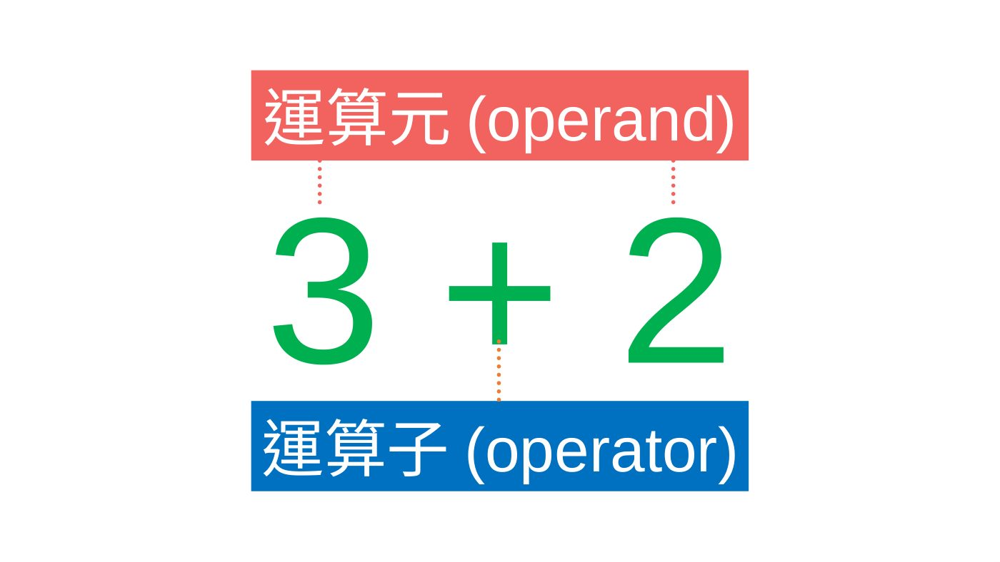

**講義文字（原稿轉錄）**

> 3 + 2

> 運算元(operand)

> 運算子(operator)

### P041｜x and y

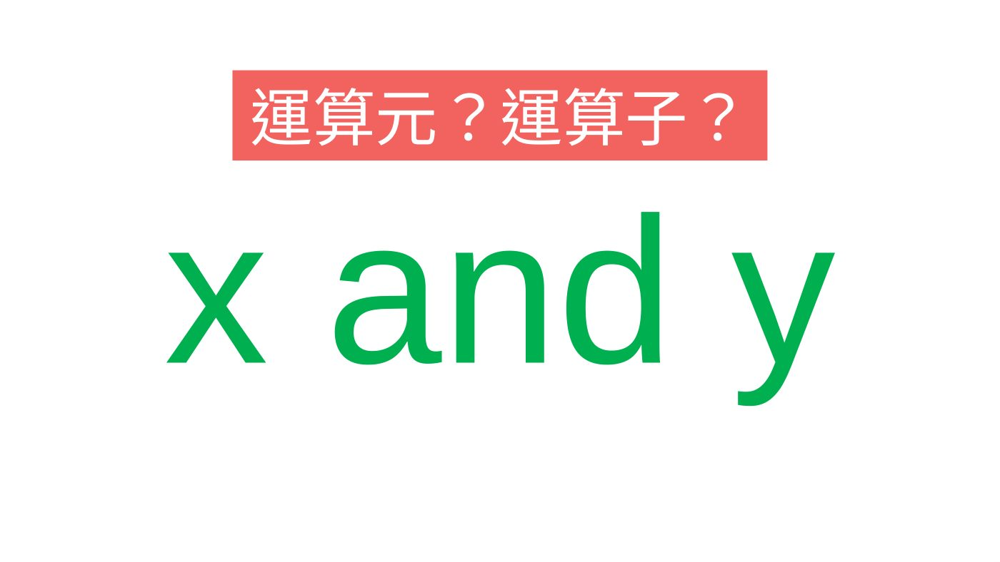

**講義文字（原稿轉錄）**

> x and y

> 運算元？運算子？

### P042｜-100

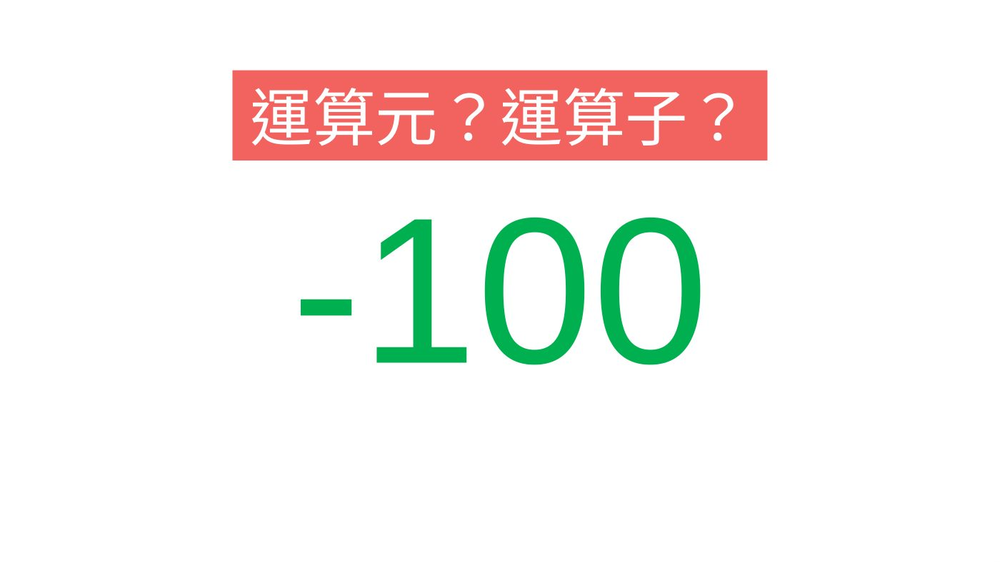

**講義文字（原稿轉錄）**

> -100

> 運算元？運算子？

### P043｜運算子的種類

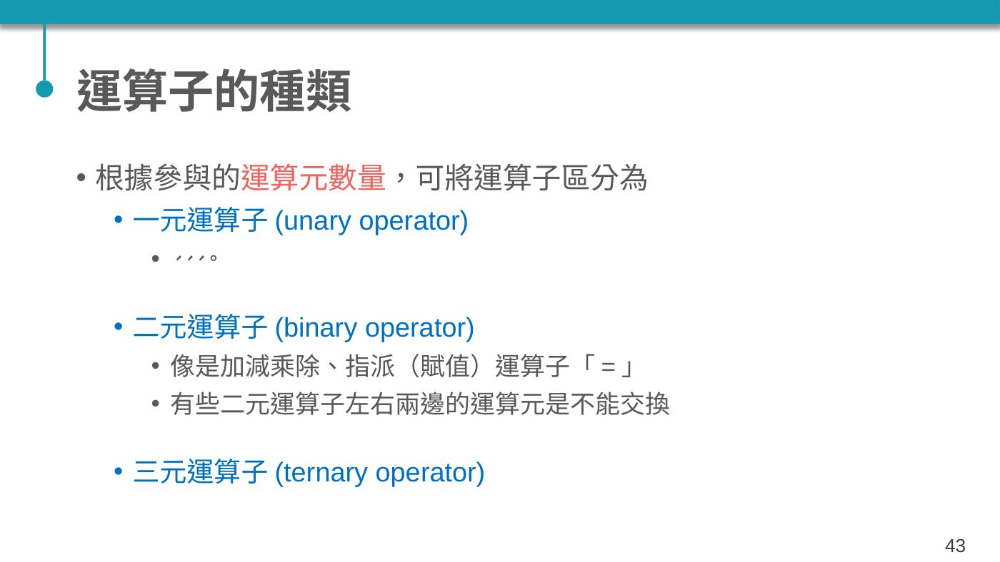

**講義文字（原稿轉錄）**

> 運算子的種類

> 根據參與的運算元數量，可將運算子區分為

> 一元運算子(unary operator)

> 只需要一個運算元，比如負號、階乘符號、矩陣的轉置、開平方等。

> 二元運算子(binary operator)

> 像是加減乘除、指派（賦值）運算子「=」

> 有些二元運算子左右兩邊的運算元是不能交換

> 三元運算子(ternary operator)

### P044｜數學上 …

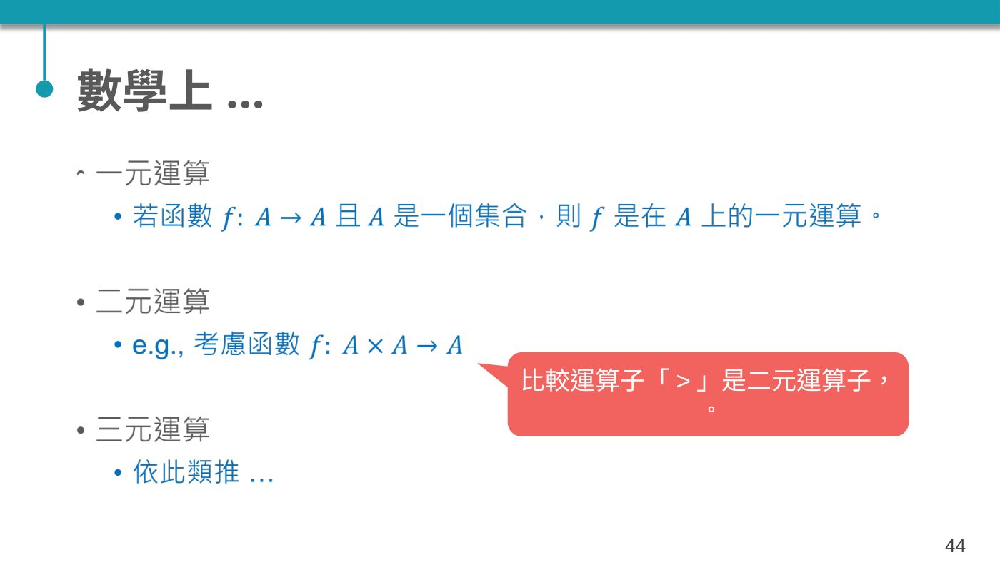

**講義文字（原稿轉錄）**

> 數學上 …

> 一元運算

> 若函數 𝑓: 𝐴→𝐴 且 𝐴 是一個集合，則 𝑓 是在 𝐴 上的一元運算。

> 二元運算

> e.g., 考慮函數 𝑓: 𝐴×𝐴→𝐴

> 三元運算

> 依此類推 …

> 比較運算子「&gt;」是二元運算子，但不是數學上的二元運算。

### P045｜運算子的優先順序(operator precedence)

**講義文字（原稿轉錄）**

> 運算子的優先順序(operator precedence)

> 稍後會看到許多不同種類的運算子，而稍微複雜一點的運算往往使用到多個運算子，這時就要注意運算子的優先順序。

> e.g., 統計上經常對資料進行標準化(standardization)得到所謂的 z 分數(z-score)，計算公式如下：

> 𝑧=𝑥−𝜇𝜎

> 平均數

> 標準差

> 假設 𝜇=10, 𝜎=2，當資料 𝑥=8 時，會得到 z-score = –1，代表這筆資料比平均數要小一個標準差。

> 𝑧=𝑥−𝜇𝜎=8−102=−1

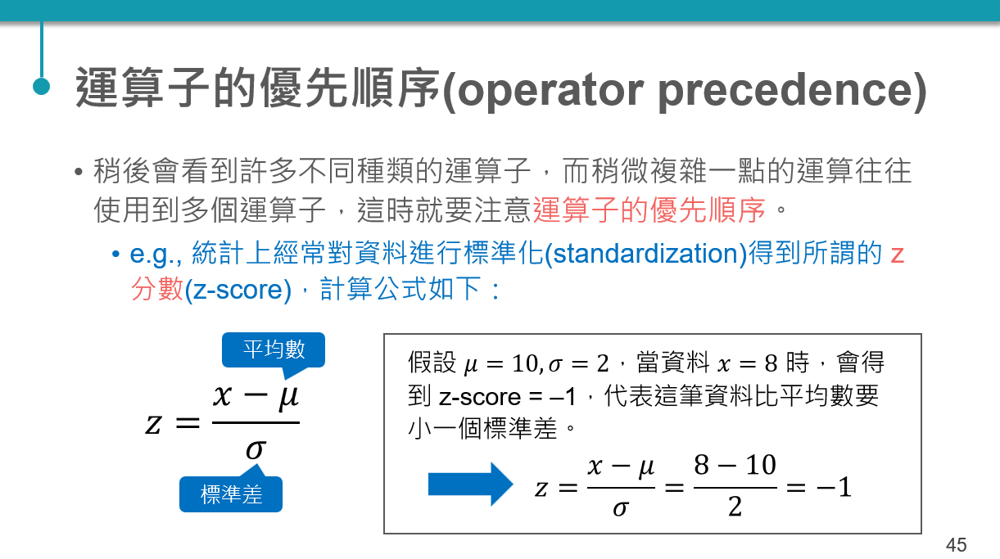

### P046｜z = (x – (mu / sigma))

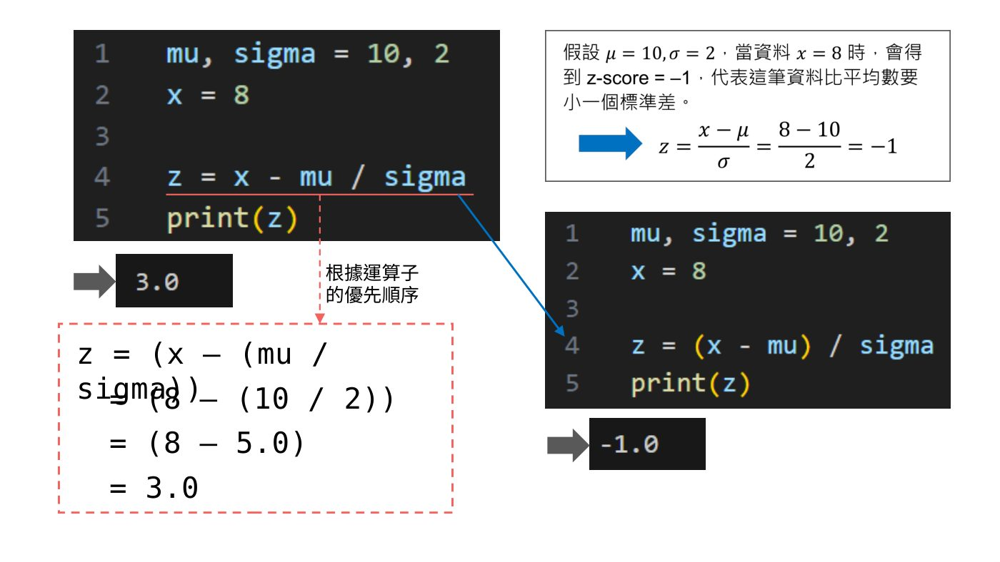

**講義文字（原稿轉錄）**

> z = (x – (mu / sigma))

> = (8 – (10 / 2))

> = (8 – 5.0)

> = 3.0

> 根據運算子的優先順序

### P047｜Source: Python–Operator precedence

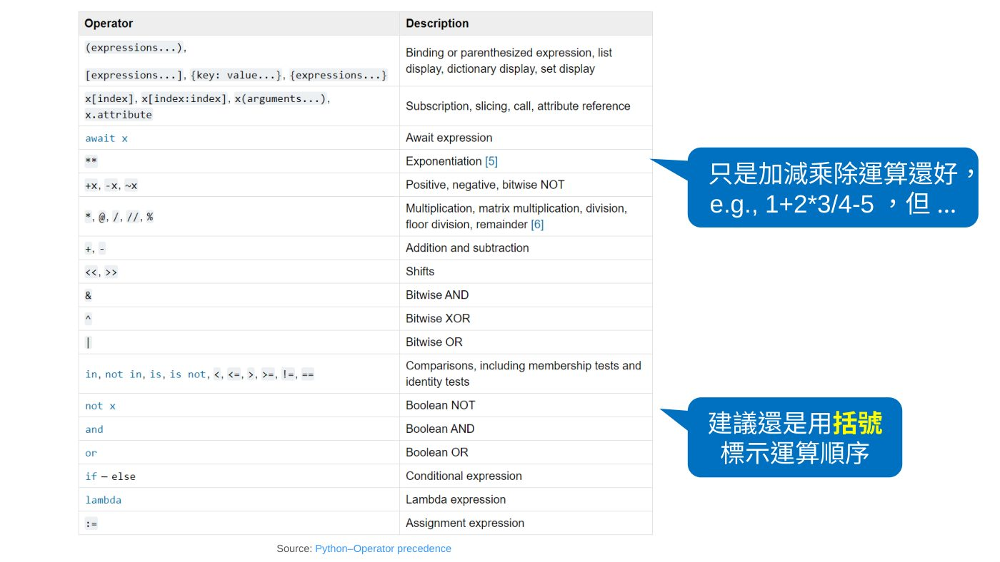

**講義文字（原稿轉錄）**

> Source: Python–Operator precedence

> 只是加減乘除運算還好，e.g., 1+2*3/4-5，但 …

> 建議還是用括號標示運算順序

#### 運算元、運算子與優先順序

3+2 是二元運算，-100 是一元運算；Python 的條件運算式是 a if condition else b。標準化必須寫成 $(x-\mu)/\sigma$。數學上的一元／二元運算分類不代表 Python 都有對應符號，例如階乘須使用 math.factorial。

In [51]:
x, mu, sigma = 8, 10, 2
print('正確 z-score:', (x-mu)/sigma)
print('缺少括號:', x-mu/sigma)
print(1+2*3/4-5)
print(-2**2, (-2)**2)
print(math.factorial(5), math.sqrt(9)) # math.factorial(5)：5 的階乘
assert (x-mu)/sigma == -1

正確 z-score: -1.0
缺少括號: 3.0
-2.5
-4 4
120 3.0


<a id="section-48"></a>

## P048 起｜算術運算

### P048｜主題

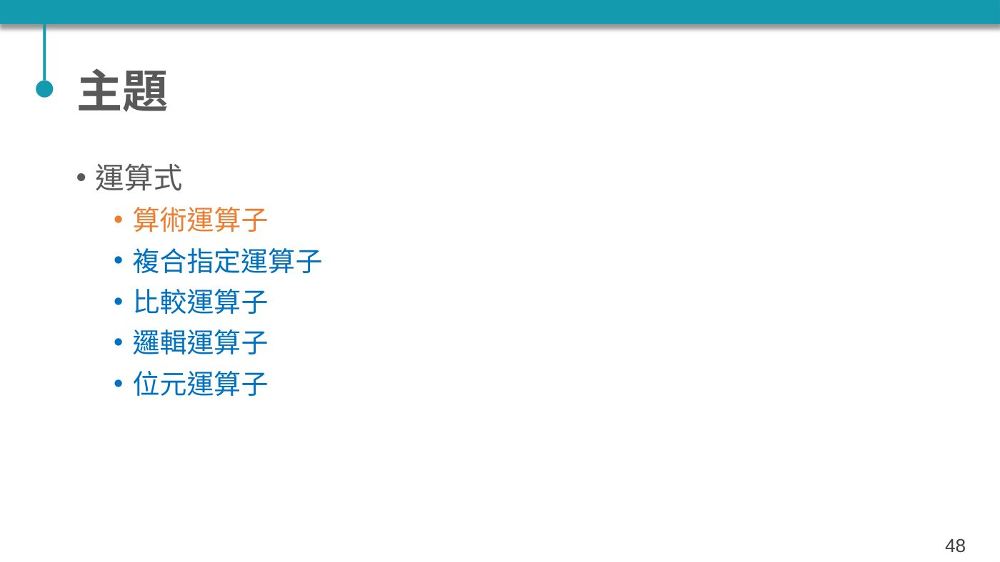

**講義文字（原稿轉錄）**

> 主題

> 運算式

> 算術運算子

> 複合指定運算子

> 比較運算子

> 邏輯運算子

> 位元運算子

### P049｜算術運算子(arithmetic operator)

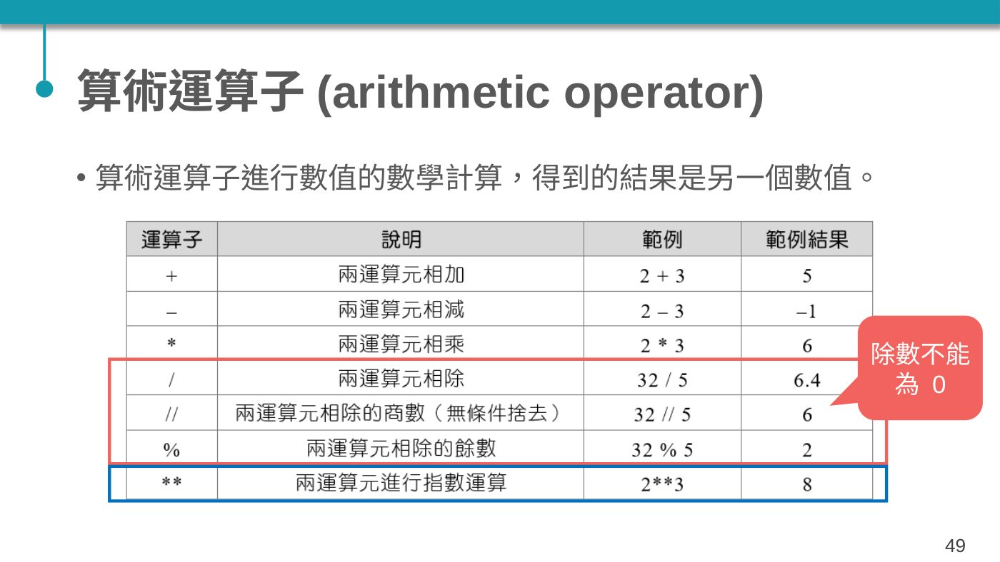

**講義文字（原稿轉錄）**

> 算術運算子(arithmetic operator)

> 算術運算子進行數值的數學計算，得到的結果是另一個數值。

> 除數不能為 0

### P050｜三種除法

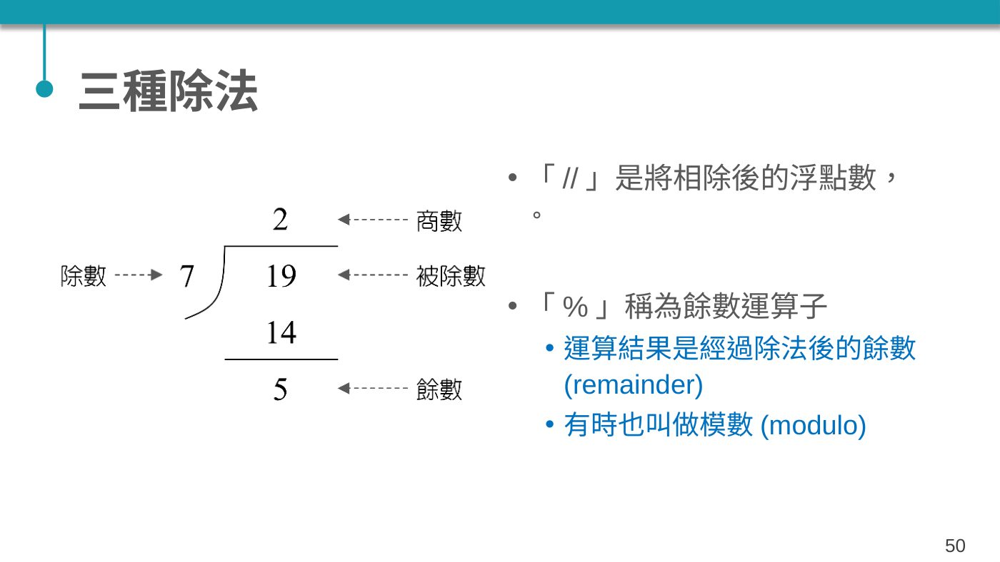

**講義文字（原稿轉錄）**

> 三種除法

> 「//」是將相除後的浮點數，無條件捨去小數點的結果。

> 「%」稱為餘數運算子

> 運算結果是經過除法後的餘數(remainder)

> 有時也叫做模數(modulo)

### P051｜範例：三種除法

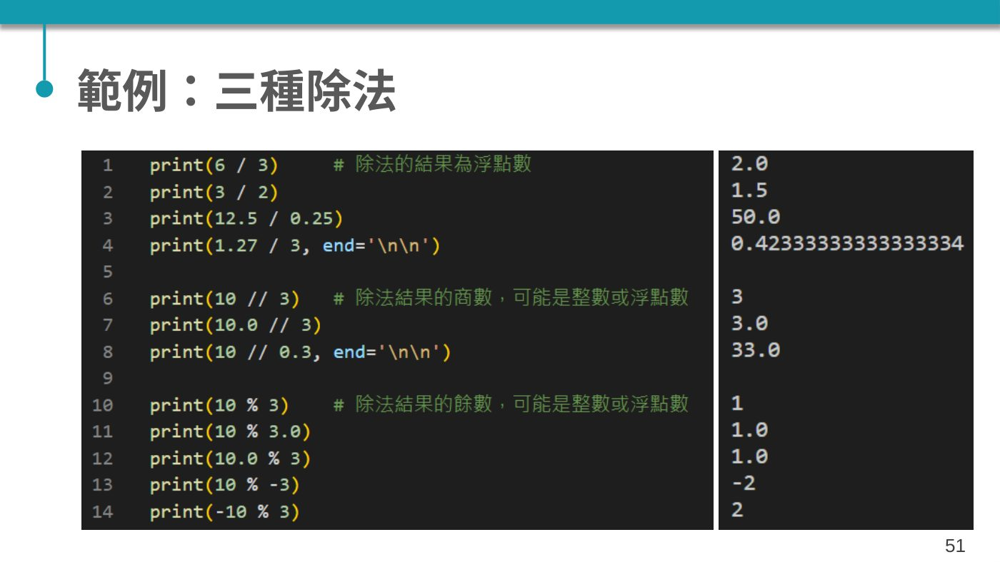

**講義文字（原稿轉錄）**

> 範例：三種除法

In [53]:
print(6 / 3)
print(3 / 2)
print(12.5 / 0.25)
print(1.27 / 3, end='\n\n')

print(10 // 3)
print(10.0 // 3)
print(10 // 0.3, end='\n\n')

print(10 % 3)
print(10.0 % 3)
print(10 % 3.0)
print(10 % -3)
print(-10 % 3)

2.0
1.5
50.0
0.42333333333333334

3
3.0
33.0

1
1.0
1.0
-2
2


💡 快速記法

在 Python 中，餘數的「正負號」永遠會跟著「除數（後面的數字）」相同：

* 10 % 3 的除數是 3（正數），所以餘數是 1（正數）。

* 10 % -3 的除數是 -3（負數），所以餘數是 -2（負數）。

### P052｜(10%-3)  -2？

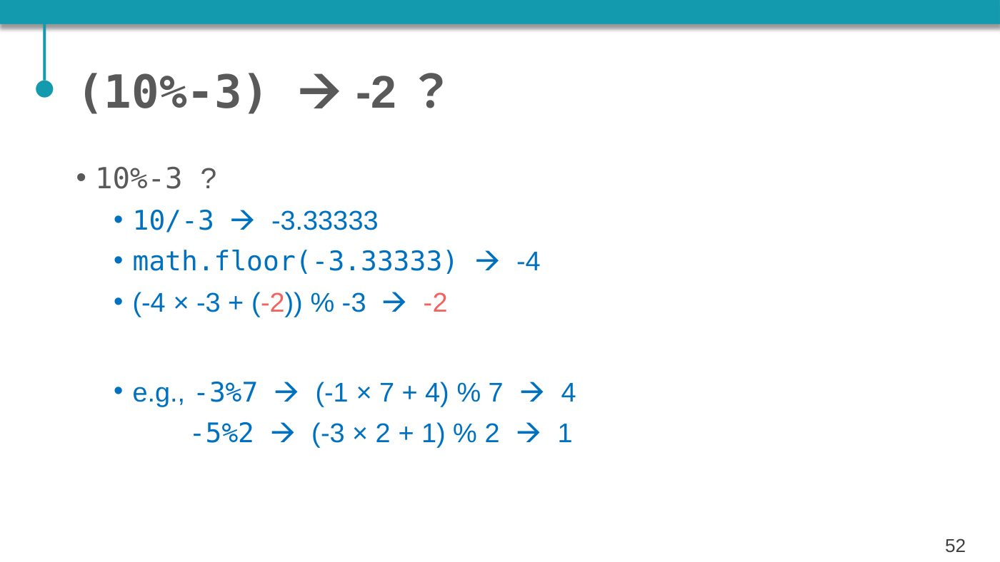

**講義文字（原稿轉錄）**

> (10%-3)  -2？

> 10%-3 ?

> 10/-3    -3.33333

> math.floor(-3.33333)    -4

> (-4 × -3 + (-2)) % -3    -2

> e.g., -3%7    (-1 × 7 + 4) % 7    4

> -5%2    (-3 × 2 + 1) % 2    1

### P053｜範例：不同資料型別做運算

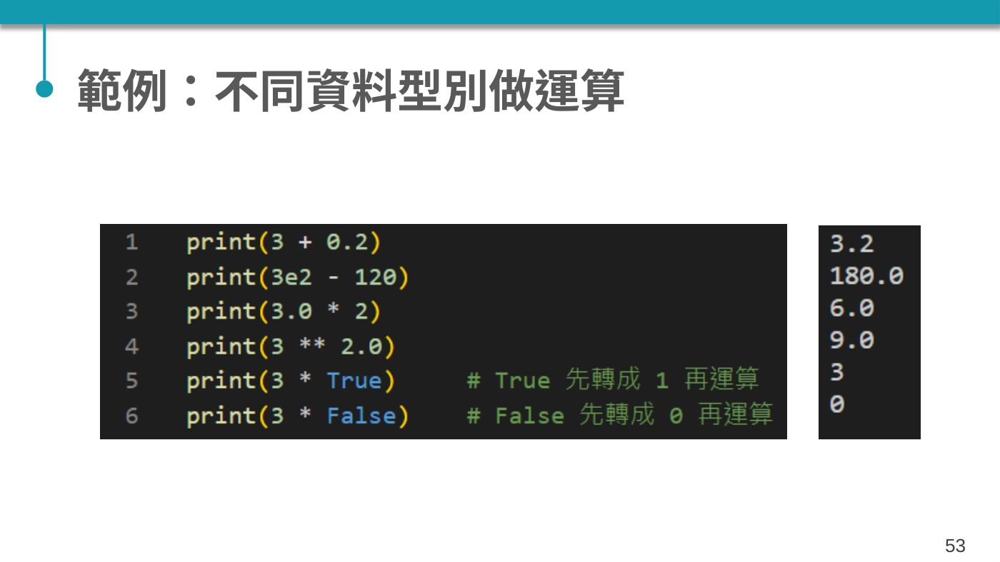

**講義文字（原稿轉錄）**

> 範例：不同資料型別做運算

#### 三種除法與混合型別

勘誤：// 向負無限大取整，不是向零去掉小數；a=b*(a//b)+a%b。負除數的餘數通常為負。float 的 // 結果仍可能是 float。

In [54]:
print(6/3, 3/2, 12.5/0.25, 1.27/3)
print(10//3, 10.0//3, 10//0.3)
print(10%3, 10%3.0, 10.0%3, 10%-3, -10%3)
print(-7//2, int(-7/2))
print(3+0.2, 3e2-120, 3.0*2, 3**2.0, 3*True, 3*False)
assert 10 == (-3)*(10//-3) + (10%-3)
try:
    print(1/0)
except ZeroDivisionError:
    print('除數為 0 不合法')

2.0 1.5 50.0 0.42333333333333334
3 3.0 33.0
1 1.0 1.0 -2 2
-4 -3
3.2 180.0 6.0 9.0 3 0
除數為 0 不合法


<a id="section-54"></a>

## P054 起｜複合指定

### P054｜主題

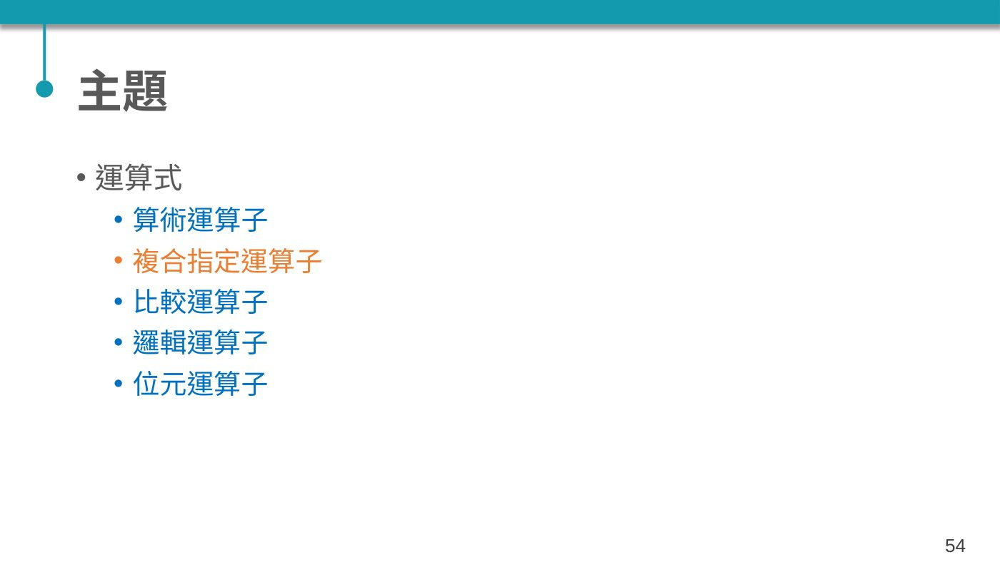

**講義文字（原稿轉錄）**

> 主題

> 運算式

> 算術運算子

> 複合指定運算子

> 比較運算子

> 邏輯運算子

> 位元運算子

### P055｜複合指定運算子(compound assignment operator)

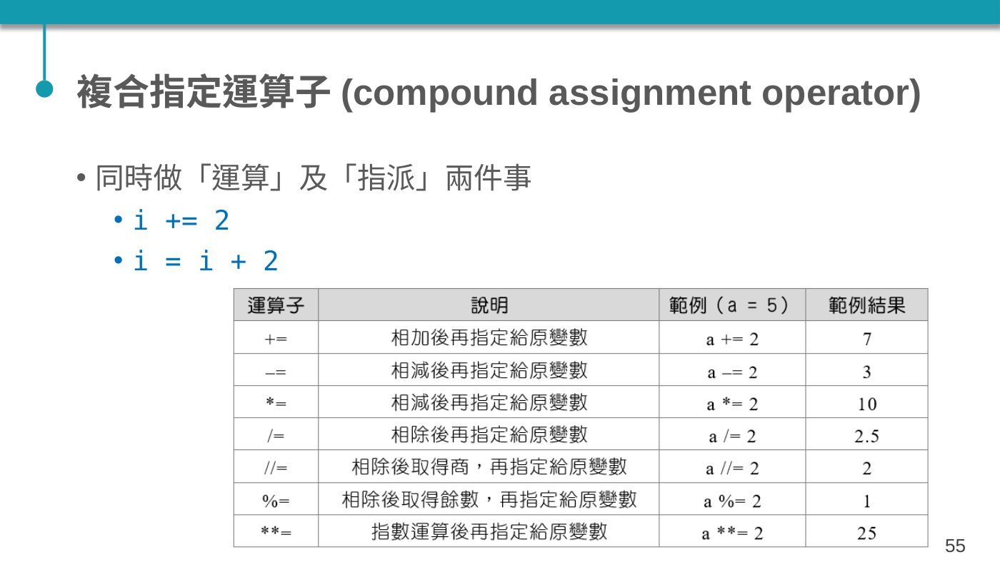

**講義文字（原稿轉錄）**

> 複合指定運算子(compound assignment operator)

> 同時做「運算」及「指派」兩件事

> i += 2

> i = i + 2

### P056｜範例：求圓面積

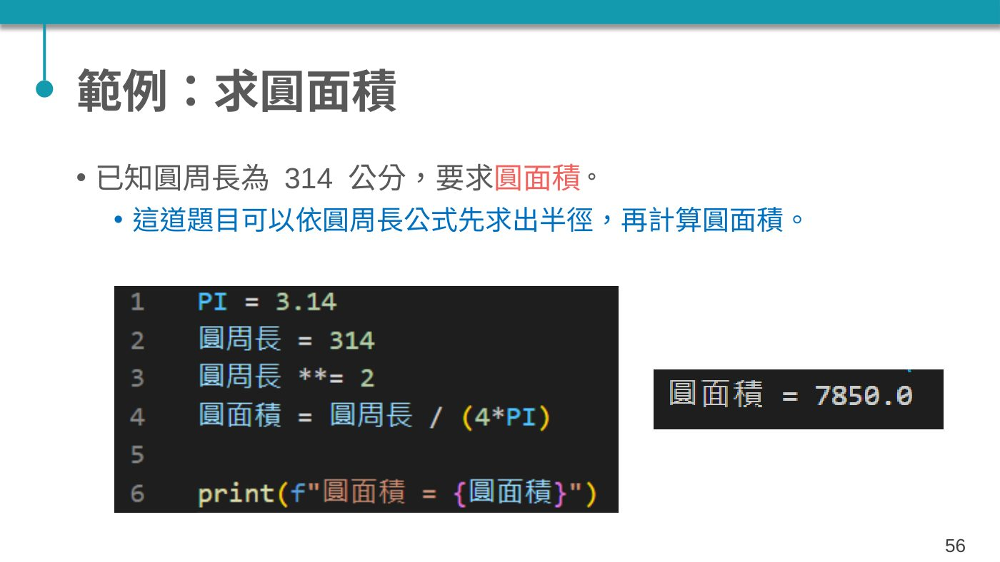

**講義文字（原稿轉錄）**

> 範例：求圓面積

> 已知圓周長為 314 公分，要求圓面積大小。

> 這道題目可以依圓周長公式先求出半徑，再計算圓面積。

#### 複合指定與圓面積

先以 $r=C/(2\pi)$ 求半徑，再計算面積；也可直接用 $A=C^2/(4\pi)$。保留原題 PI=3.14，以重現 7850.0。

In [55]:
i = 10
i += 2; print(i)
i -= 2; i *= 3; i /= 2; print(i)
PI, circumference = 3.14, 314
radius = circumference/(2*PI)
area = PI*radius**2
circumference **= 2
print('圓面積 =', circumference/(4*PI))
assert area == 7850

12
15.0
圓面積 = 7850.0


### P057｜練習：計算導數值

**講義文字（原稿轉錄）**

> 練習：計算導數值

> 使用者輸入一個數 𝑎，並給定一個函數 𝑓(𝑥) 如下，請計算 𝑓(𝑥) 在 𝑥=𝑎 的導數(derivative)。

> 輸入：一個數 𝑎

> 輸出：𝑓(𝑥) 在 𝑥=𝑎 的導數

> 注意：請利用導數的極限定義來計算，勿直接將導數寫在程式碼裡。

> 𝑓𝑥=3𝑥4−7𝑥2+5

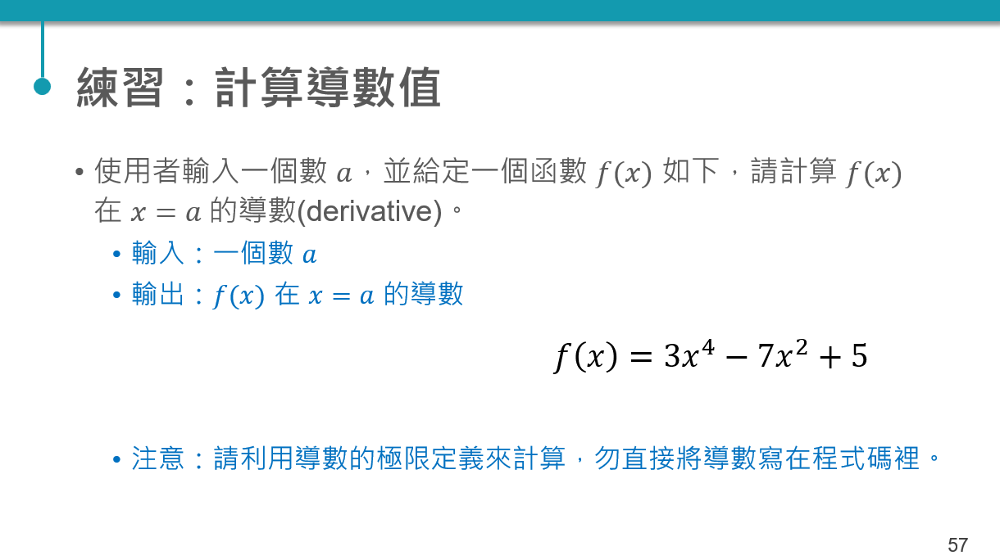

<a id="answer-57"></a>

#### 習題解答｜多項式的數值導數

原投影片公式為 $f(x)=3x^4-7x^2+5$。以差商 $[f(a+h)-f(a)]/h$ 近似極限；h 不能直接設為 0，也不是越小越好。以下額外比較中心差分，不以解析導數代替答案。原頁部分公式在轉圖時可能缺字，以此文字公式為準。

**先練習**：依上方原題與提示，自行寫出步驟及程式。可修改輸入資料，測試正常值與邊界值。下方空白練習格不影響全部執行。

In [ ]:
# 我的練習區：請在此撰寫程式。
# 建議先寫輸入、處理、輸出三個步驟。

**參考解答與驗收**

觀察印出的結果，並閱讀 `assert` 檢核；若條件不成立，會出現 AssertionError。

In [58]:
# 1. 輸入數字 a
a = float(input("請輸入 a 的值："))

# 2. 設定一個非常小的數 h（代表靠近 0 的微小變化量）
h = 0.0000001

# 3. 直接寫出 f(a + h) 的運算式： 3*(a+h)^4 - 7*(a+h)^2 + 5
f_a_plus_h = 3 * ((a + h) ** 4) - 7 * ((a + h) ** 2) + 5

# 4. 直接寫出 f(a) 的運算式： 3*a^4 - 7*a^2 + 5
f_a = 3 * (a**4) - 7 * (a**2) + 5

# 5. 依導數極限定義公式算答案： [f(a + h) - f(a)] / h
ans = (f_a_plus_h - f_a) / h

# 6. 印出結果
print("導數值約為：", ans)

請輸入 a 的值：2
導數值約為： 68.00000644346937


In [ ]:
def polynomial(x):
    return 3*x**4 - 7*x**2 + 5
ask = make_input(['2'])
a = float(ask('a = '))
for h in [1e-2,1e-3,1e-4,1e-5]:
    forward = (polynomial(a+h)-polynomial(a))/h
    central = (polynomial(a+h)-polynomial(a-h))/(2*h)
    print(f'h={h:g}，前向差商={forward:.6f}，中心差分={central:.6f}')
# 額外使用固定點的已知答案驗收，答案計算仍採差商。
h=1e-5
assert math.isclose((polynomial(2+h)-polynomial(2-h))/(2*h),68,abs_tol=1e-6)

a = 2
h=0.01，前向差商=68.652403，中心差分=68.002400
h=0.001，前向差商=68.065024，中心差分=68.000024
h=0.0001，前向差商=68.006500，中心差分=68.000000
h=1e-05，前向差商=68.000650，中心差分=68.000000


<a id="section-58"></a>

## P058 起｜比較運算

### P058｜主題

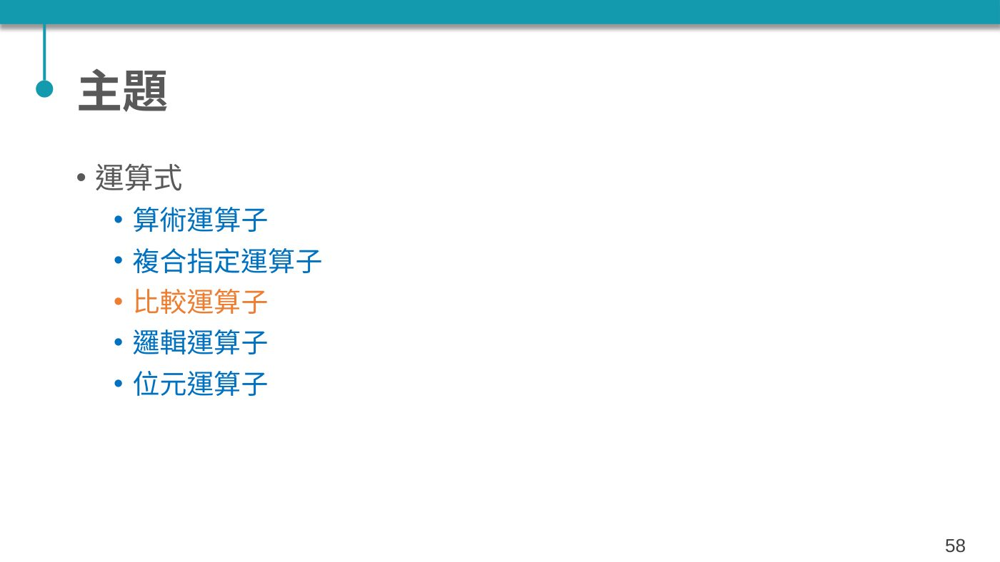

**講義文字（原稿轉錄）**

> 主題

> 運算式

> 算術運算子

> 複合指定運算子

> 比較運算子

> 邏輯運算子

> 位元運算子

### P059｜比較運算子(comparison operator)

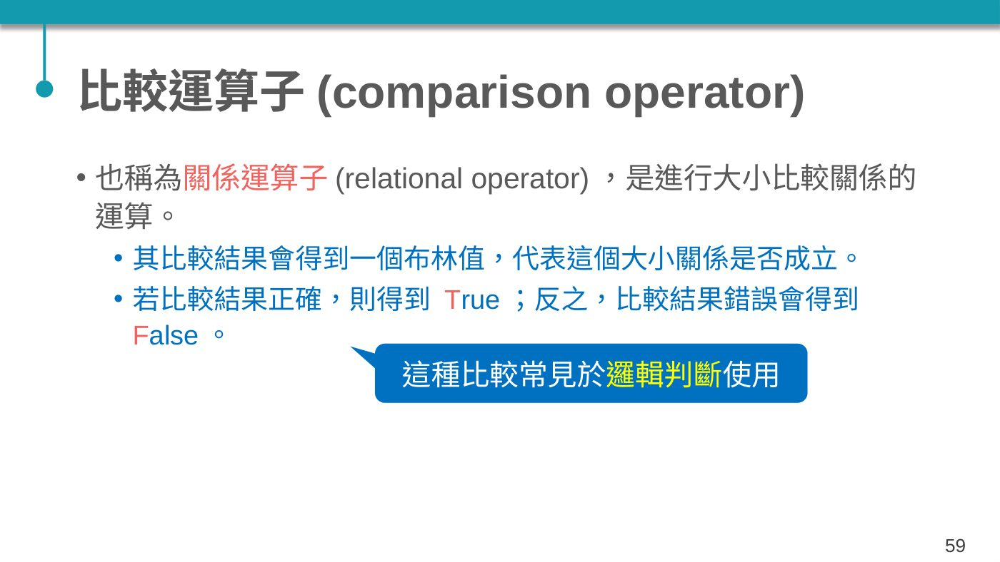

**講義文字（原稿轉錄）**

> 比較運算子(comparison operator)

> 也稱為關係運算子(relational operator)，是進行大小比較關係的運算。

> 其比較結果會得到一個布林值，代表這個大小關係是否成立。

> 若比較結果正確，則得到 True；反之，比較結果錯誤會得到 False。

> 這種比較常見於邏輯判斷使用

### P060｜比較運算子

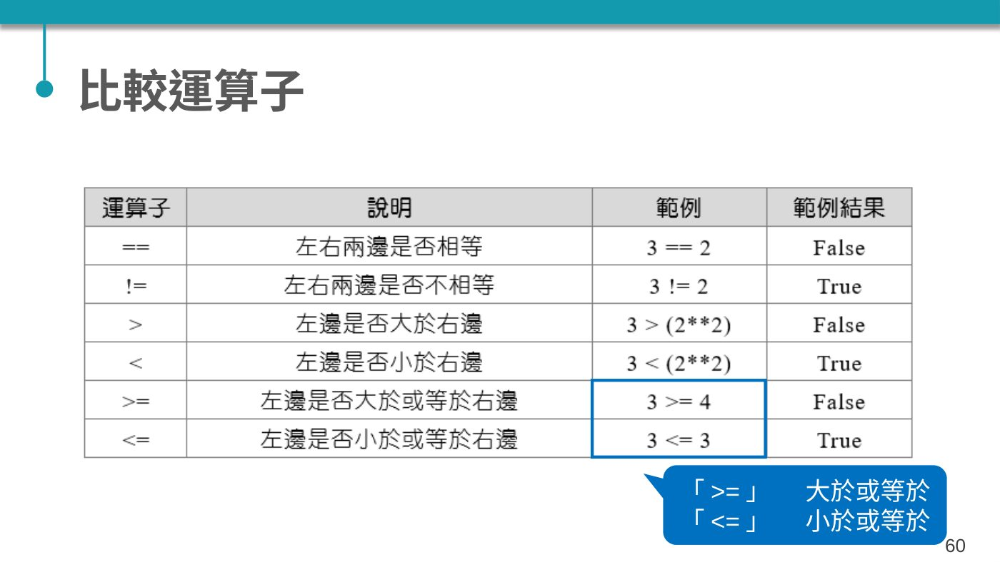

**講義文字（原稿轉錄）**

> 比較運算子

> 「&gt;=」   大於或等於

> 「&lt;=」   小於或等於

### P061｜注意

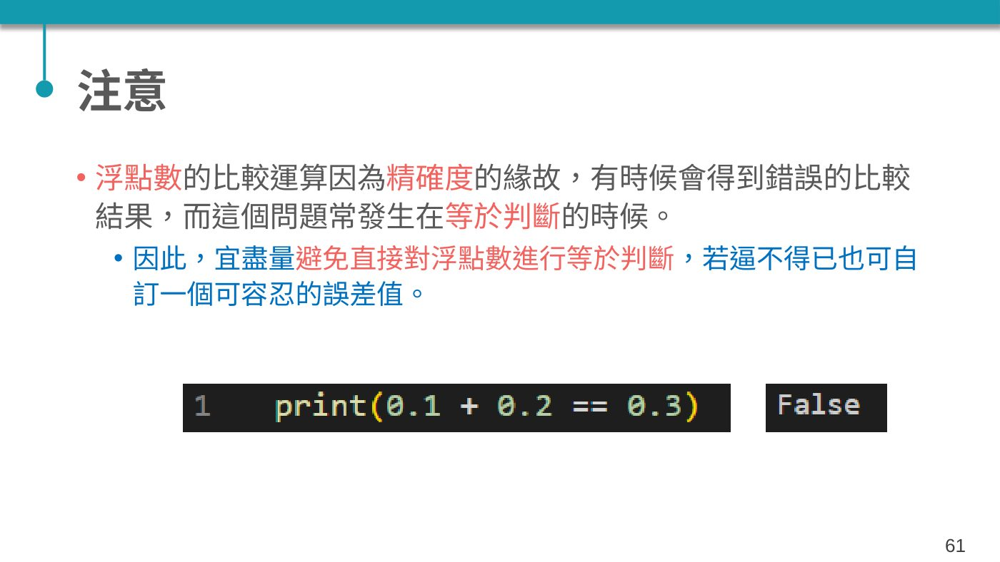

**講義文字（原稿轉錄）**

> 注意

> 浮點數的比較運算因為精確度的緣故，有時候會得到錯誤的比較結果，而這個問題常發生在等於判斷的時候。

> 因此，宜盡量避免直接對浮點數進行等於判斷，若逼不得已也可自訂一個可容忍的誤差值。

#### 比較與浮點容許誤差

比較可串接。等號 = 是指派，== 才是相等比較。對浮點計算結果使用 math.isclose。

In [59]:
x, y = 2, 5
print(x==y, x!=y, x<y, x<=y, x>y, x>=y)
print(0 <= 85 <= 100)
print(0.1+0.2 == 0.3)
print(math.isclose(0.1+0.2, 0.3))
assert math.isclose(0.1+0.2, 0.3)

False True True True False False
True
False
True


<a id="section-62"></a>

## P062 起｜邏輯運算

### P062｜主題

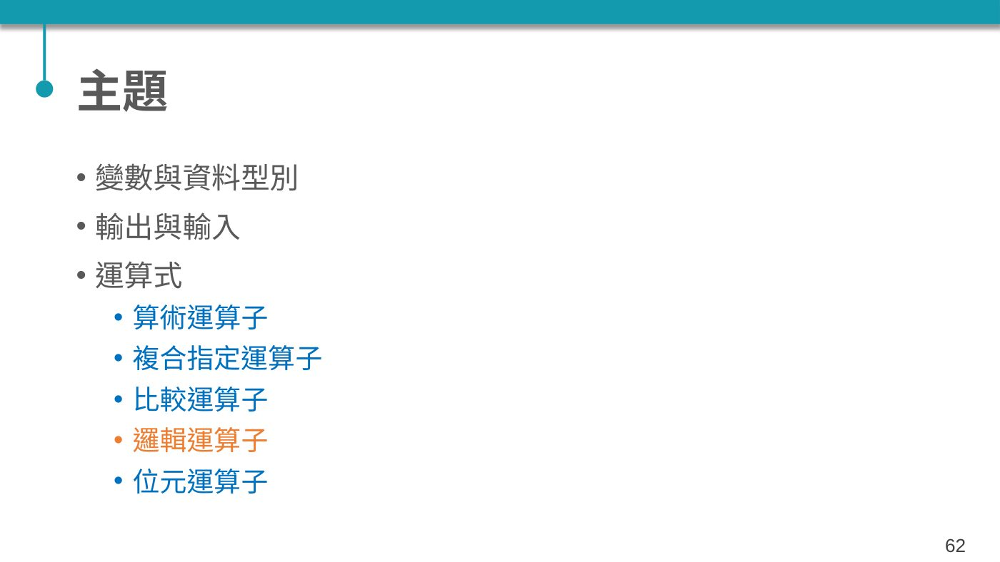

**講義文字（原稿轉錄）**

> 主題

> 變數與資料型別

> 輸出與輸入

> 運算式

> 算術運算子

> 複合指定運算子

> 比較運算子

> 邏輯運算子

> 位元運算子

### P063｜邏輯運算子(logical operator)

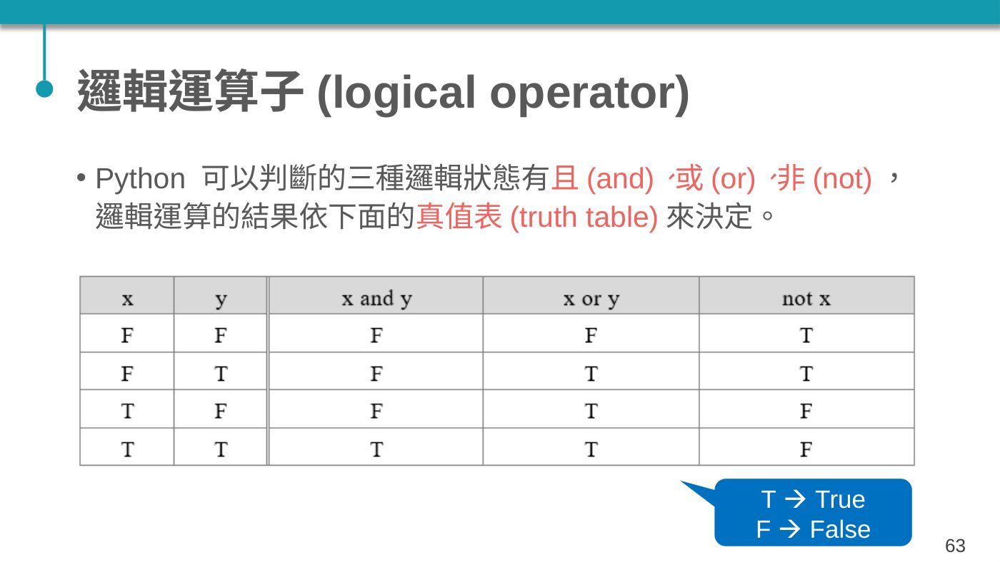

**講義文字（原稿轉錄）**

> 邏輯運算子(logical operator)

> Python 可以判斷的三種邏輯狀態有且(and)、或(or)、非(not)，邏輯運算的結果依下面的真值表(truth table)來決定。

> T  True

> F  False

### P064｜邏輯運算子

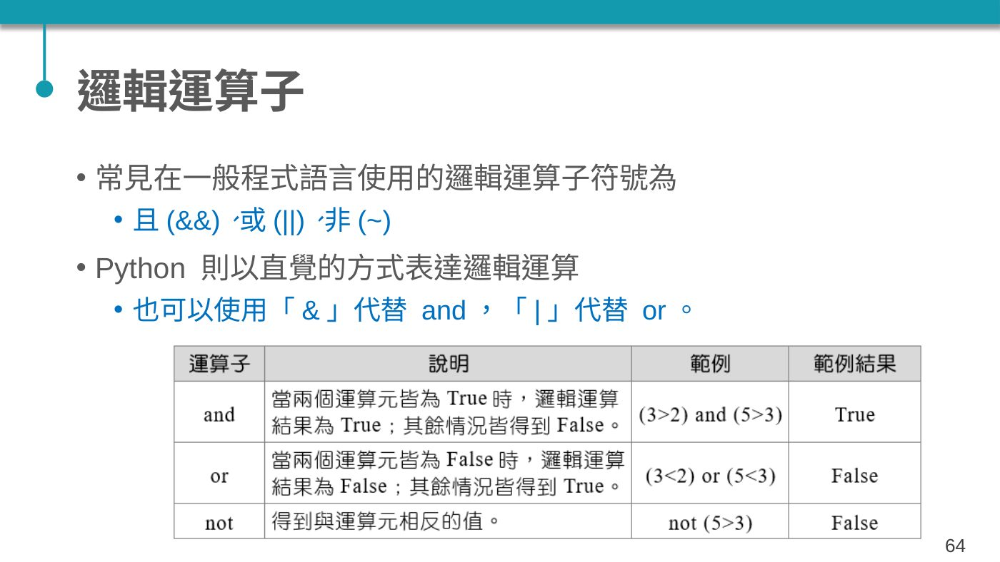

**講義文字（原稿轉錄）**

> 邏輯運算子

> 常見在一般程式語言使用的邏輯運算子符號為

> 且(&amp;&amp;)、或(||)、非(~)

> Python 則以直覺的方式表達邏輯運算

> 也可以使用「&amp;」代替 and，「|」代替 or。

### P065｜範例

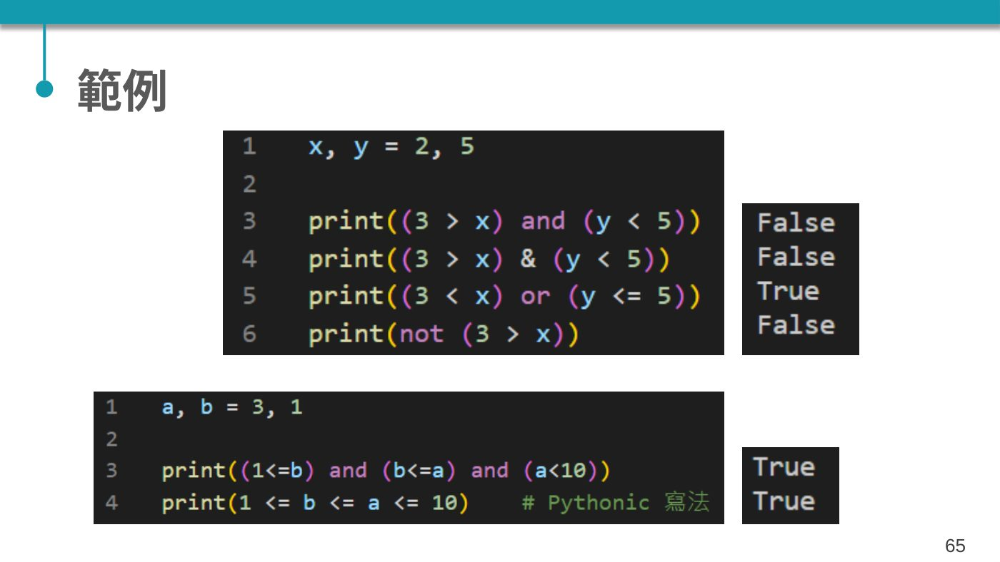

**講義文字（原稿轉錄）**

> 範例

#### 邏輯、真值表與短路

勘誤：&、| 是位元運算，不能一般性取代 and、or。and/or 會短路，並可能回傳運算元而不只是 bool。

In [ ]:
for x in [False,True]:
    for y in [False,True]:
        print(x,y,'and:',x and y,'or:',x or y,'not x:',not x)
b = 0
print(b != 0 and 10/b > 2)  # 短路，避免除以 0
print('' or '預設文字', '有內容' and 123)
x,y=2,5
print((3>x) and (y<5), (3<x) or (y<=5), not(3>x))
print(1 <= 1 <= 3 <= 10)

False False and: False or: False not x: True
False True and: False or: True not x: True
True False and: False or: True not x: False
True True and: True or: True not x: False
False
預設文字 123
False True False
True


In [77]:
# 使用 Python 標準的邏輯運算子 not 及 or
print(not(2 < 1) or not(2 < 3))

# 如果一定要用 |，必須加上括號：
print( (not(2 < 1)) | (not(2 < 3)) )

True
True


### P066｜範例：交換兩變數值

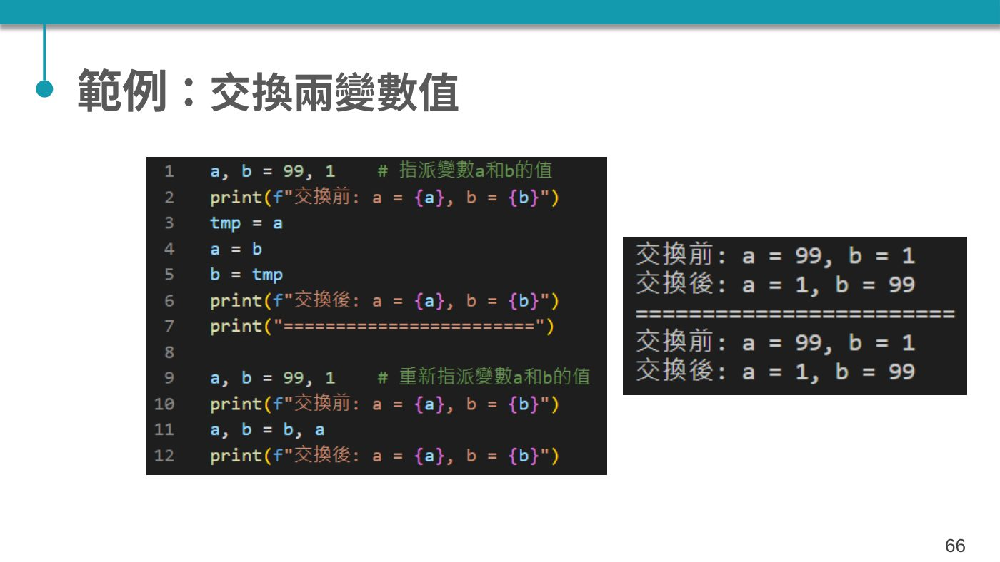

**講義文字（原稿轉錄）**

> 範例：交換兩變數值

#### 交換兩個變數

先用暫存值理解交換，再以 Python 的同時指派改寫。右側會先求值。

In [80]:
a,b=99,1
print(f"交換前：a = {a}, b = {b}")
tmp=a; a=b; b=tmp
print(f"交換後：a = {a}, b = {b}")
print("=============================")
a,b=99,1
print(f"交換前：a = {a}, b = {b}")
a,b=b,a
print(f"交換後：a = {a}, b = {b}")
assert (a,b)==(1,99)

交換前：a = 99, b = 1
交換後：a = 1, b = 99
交換前：a = 99, b = 1
交換後：a = 1, b = 99


### P067｜練習：XOR

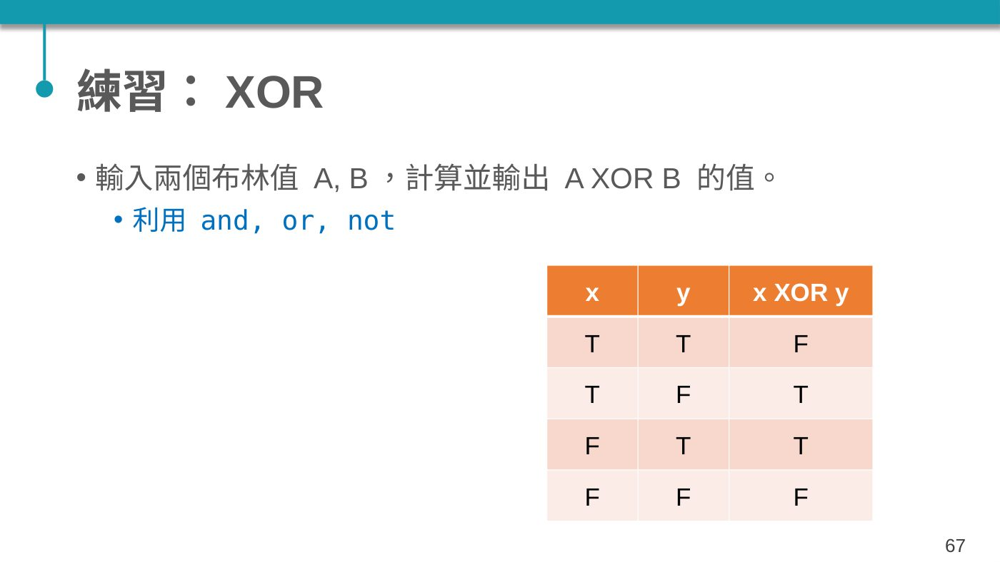

**講義文字（原稿轉錄）**

> 練習：XOR

> 輸入兩個布林值 A, B，計算並輸出 A XOR B 的值。

> 利用 and, or, not

> x

> y

> x XOR y

> T

> T

> F

> T

> F

> T

> F

> T

> T

> F

> F

> F

<a id="answer-67"></a>

#### 習題解答｜XOR

兩者恰有一個為真時 XOR 才為真：$(A\land\lnot B)\lor(\lnot A\land B)$。不要使用 bool("False") 解析輸入，它仍是 True。

**先練習**：依上方原題與提示，自行寫出步驟及程式。可修改輸入資料，測試正常值與邊界值。下方空白練習格不影響全部執行。

In [ ]:
# 我的練習區：請在此撰寫程式。
# 建議先寫輸入、處理、輸出三個步驟。

**參考解答與驗收**

觀察印出的結果，並閱讀 `assert` 檢核；若條件不成立，會出現 AssertionError。

In [81]:
def parse_bool(text):
    values={'true':True,'false':False,'1':True,'0':False,'t':True,'f':False}
    key=text.strip().lower()
    if key not in values:
        raise ValueError('請輸入 True/False 或 1/0')
    return values[key]
def xor_logic(a,b):
    return (a and not b) or (not a and b)
ask=make_input(['True','False'])
A=parse_bool(ask('A：')); B=parse_bool(ask('B：'))
print('A XOR B =',xor_logic(A,B))
for A in [True,False]:
    for B in [True,False]:
        assert xor_logic(A,B)==(A!=B)
        print(A,B,xor_logic(A,B))

A：0
B：1
A XOR B = True
True True False
True False True
False True True
False False False


<a id="section-68"></a>

## P068 起｜位元運算

### P068｜主題

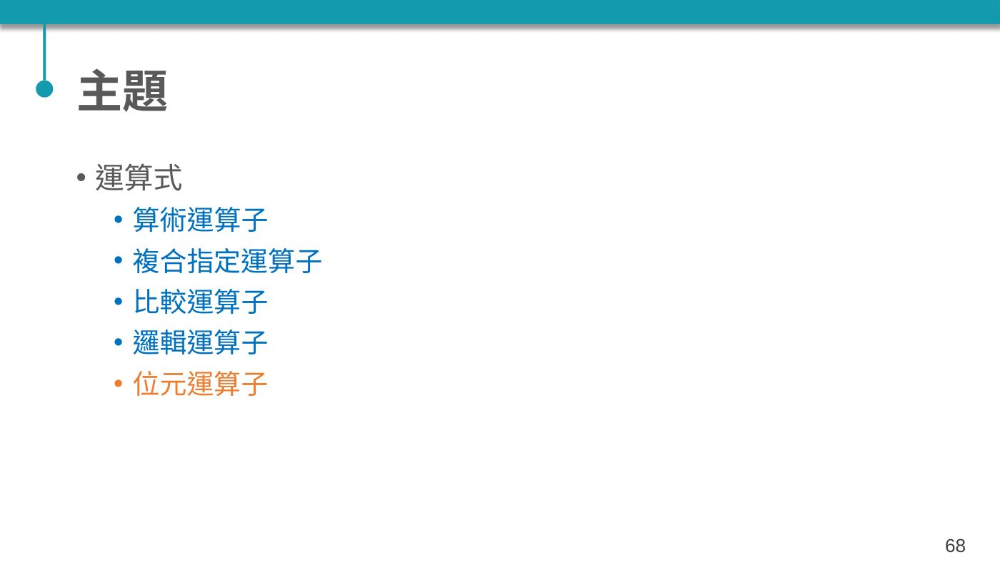

**講義文字（原稿轉錄）**

> 主題

> 運算式

> 算術運算子

> 複合指定運算子

> 比較運算子

> 邏輯運算子

> 位元運算子

### P069｜位元運算子(bitwise operator)

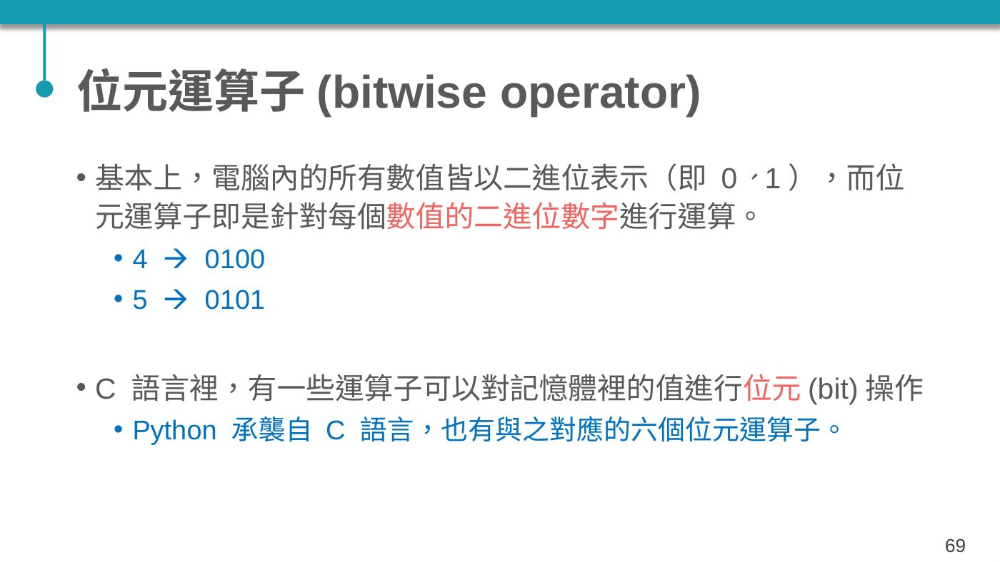

**講義文字（原稿轉錄）**

> 位元運算子(bitwise operator)

> 基本上，電腦內的所有數值皆以二進位表示（即 0、1），而位元運算子即是針對每個數值的二進位數字進行運算。

> 4    0100

> 5    0101

> C 語言裡，有一些運算子可以對記憶體裡的值進行位元(bit)操作

> Python 承襲自 C 語言，也有與之對應的六個位元運算子。

### P070｜位元運算子

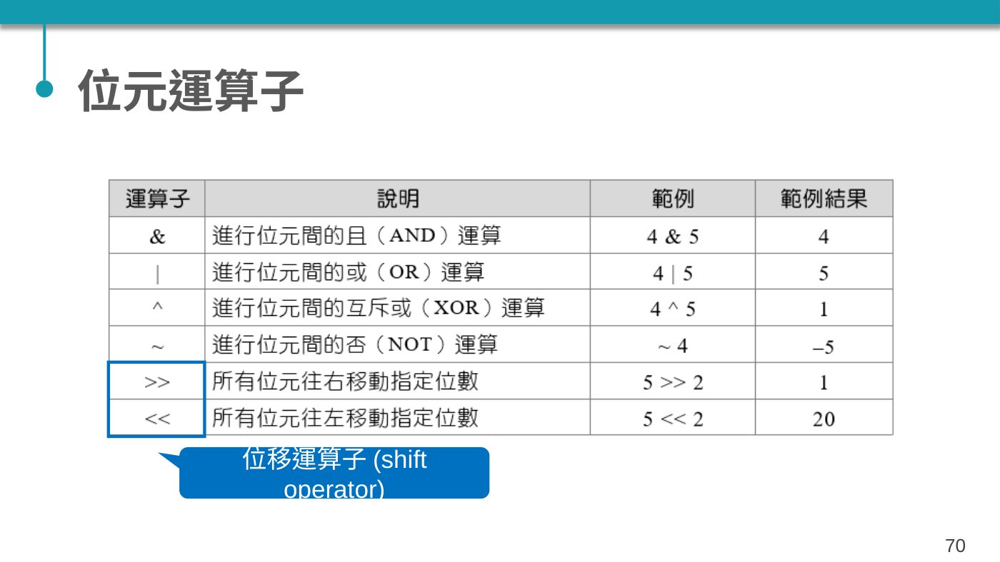

**講義文字（原稿轉錄）**

> 位元運算子

> 位移運算子(shift operator)

### P071｜運算範例(1/2)

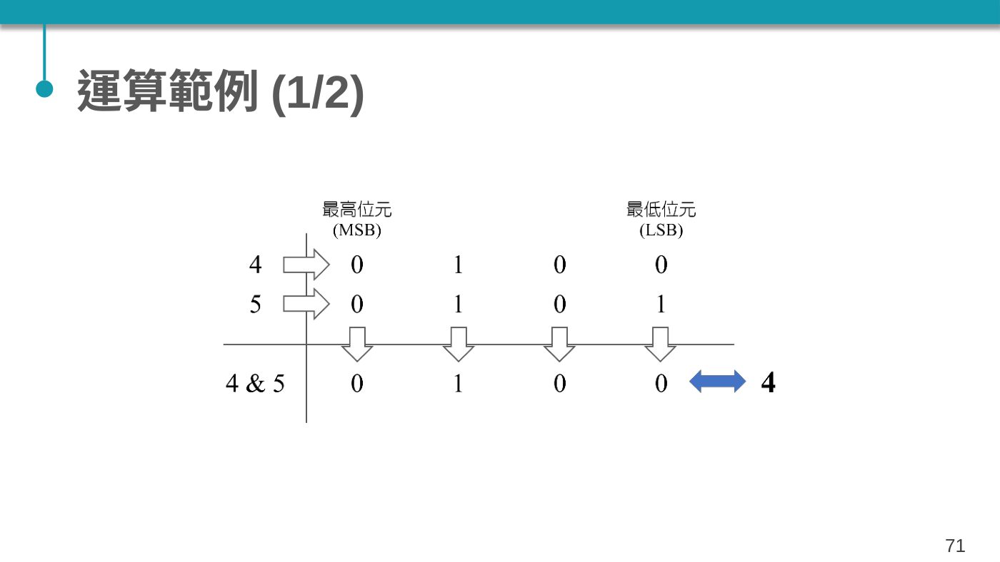

**講義文字（原稿轉錄）**

> 運算範例(1/2)

### P072｜運算範例(2/2)

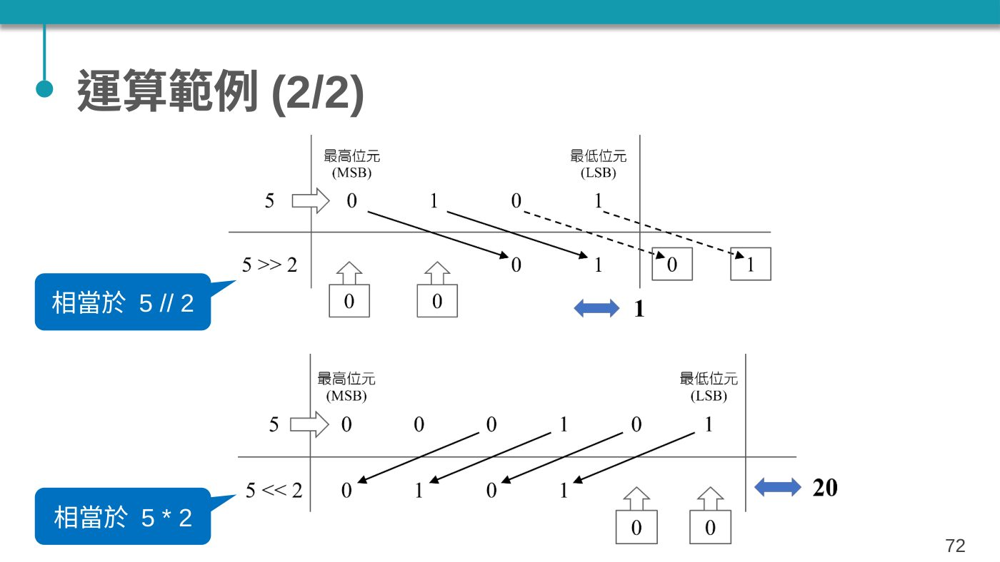

**講義文字（原稿轉錄）**

> 運算範例(2/2)

> 相當於 5 // 2

> 相當於 5 * 2

### P073｜範例：奇偶數判斷

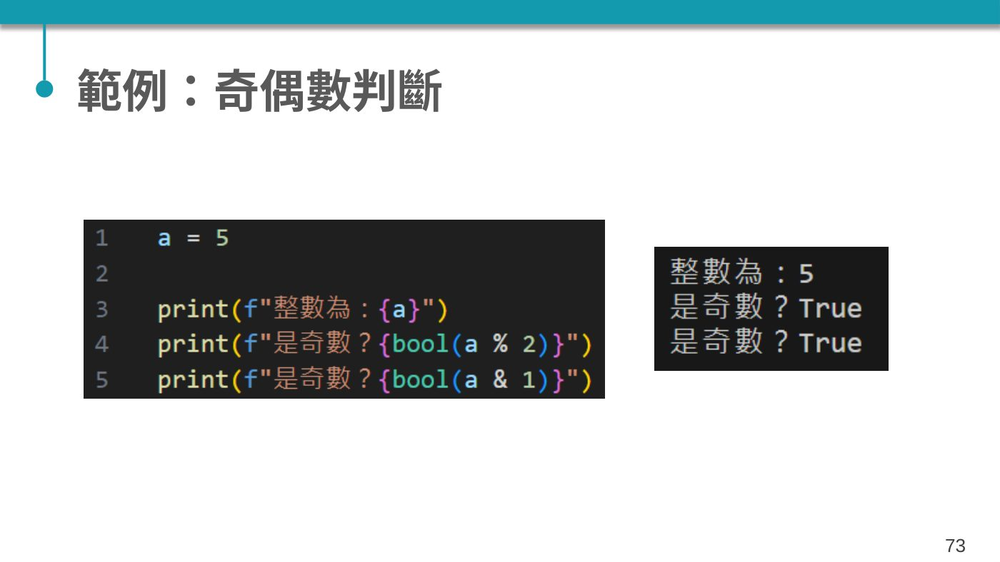

**講義文字（原稿轉錄）**

> 範例：奇偶數判斷

#### 位元運算與奇偶判斷

勘誤：移動 k 位相當於乘或整除 $2^k$。原第 72 頁標示移動 2 位卻寫乘除 2，應為乘除 4。~x 等於 -x-1。

In [83]:
a,b=4,5
print(f'a={a:04b}, b={b:04b}')
print('AND:',a&b,'OR:',a|b,'XOR:',a^b,'NOT:',~a)
print(5>>2,5<<2)
assert 5>>2 == 5//4 and 5<<2 == 5*4
for n in [-3,0,4,5]:
    print(n,'是奇數？',bool(n%2),bool(n&1))

a=0100, b=0101
AND: 4 OR: 5 XOR: 1 NOT: -5
1 20
-3 是奇數？ True True
0 是奇數？ False False
4 是奇數？ False False
5 是奇數？ True True


💡 實用小結：

這種寫法常用於奇偶數或倍數的條件判斷：

* bool(n % 2)：如果 n 是奇數，餘數為 1（True）；如果 n 是偶數，餘數為 0（False）。
* bool(n % d)：可以用來快速判斷 n 能否被 d 整除（若結果為 False 代表能整除，True 代表無法整除）。

In [85]:
print(bool(5%2))
print(bool(5%1))

True
False


<a id="section-74"></a>

## P074 起｜流程控制與單向條件

### P074｜主題

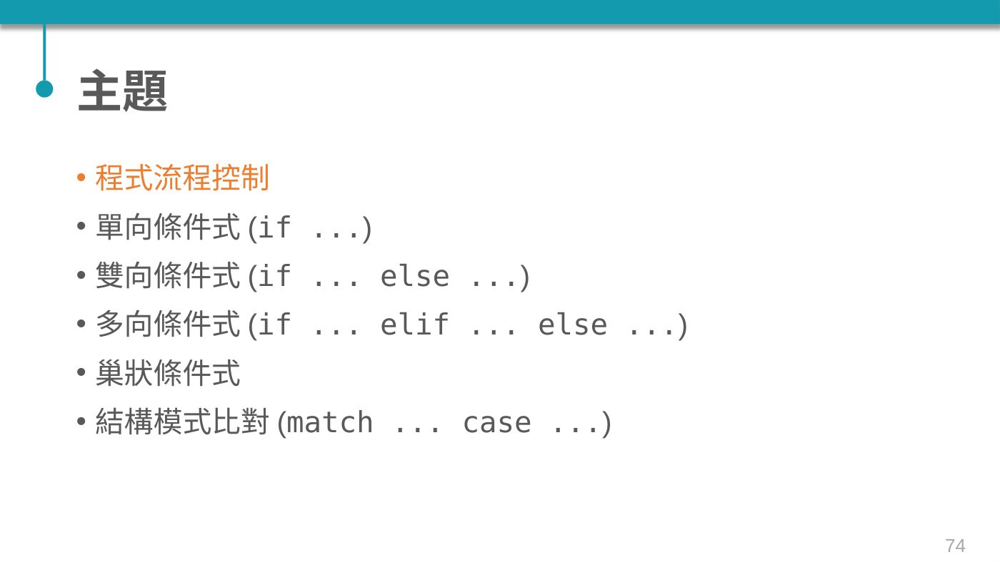

**講義文字（原稿轉錄）**

> 主題

> 程式流程控制

> 單向條件式(if ...)

> 雙向條件式(if ... else ...)

> 多向條件式(if ... elif ... else ...)

> 巢狀條件式

> 結構模式比對(match ... case ...)

### P075｜結構化程式設計(structured programming)

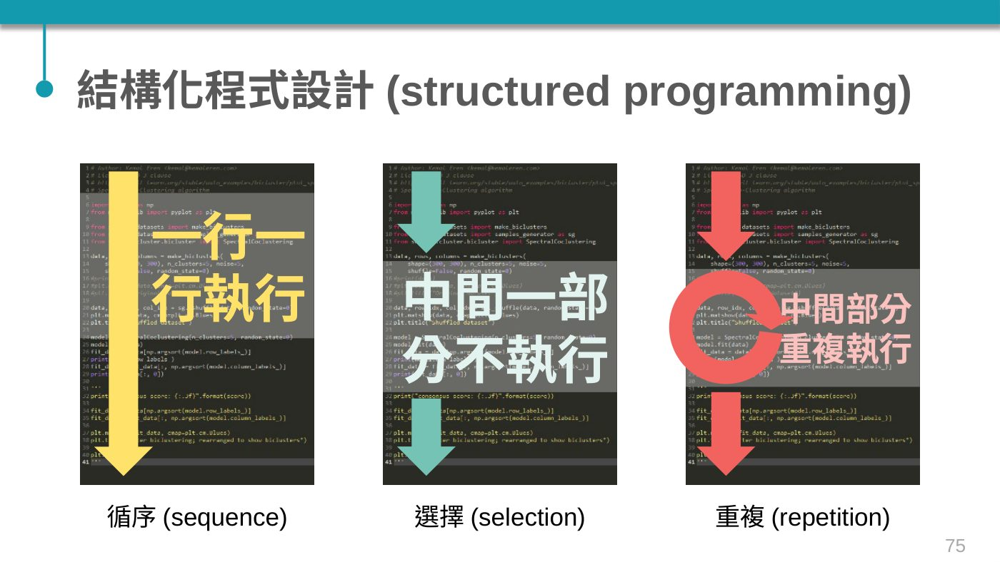

**講義文字（原稿轉錄）**

> 結構化程式設計(structured programming)

> 一行一行執行：循序(sequence)

> 中間一部分不執行：選擇(selection)

> 中間部分重複執行：重複(repetition)

### P076｜流程控制(flow control) (1/2)

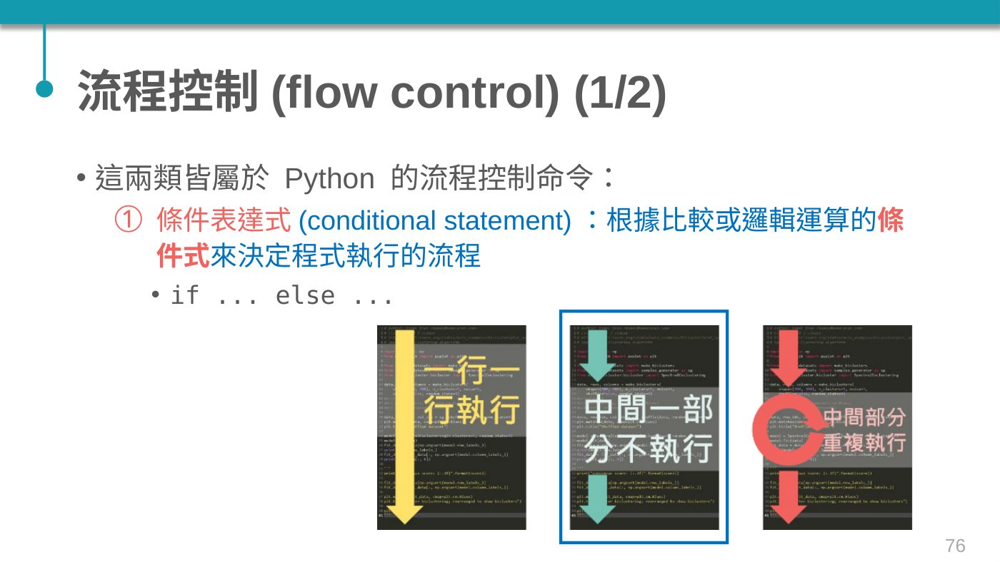

**講義文字（原稿轉錄）**

> 流程控制(flow control) (1/2)

> 這兩類皆屬於 Python 的流程控制命令：

> 條件表達式(conditional statement)：根據比較或邏輯運算的條件式來決定程式執行的流程

> if ... else ...

### P077｜流程控制(2/2)

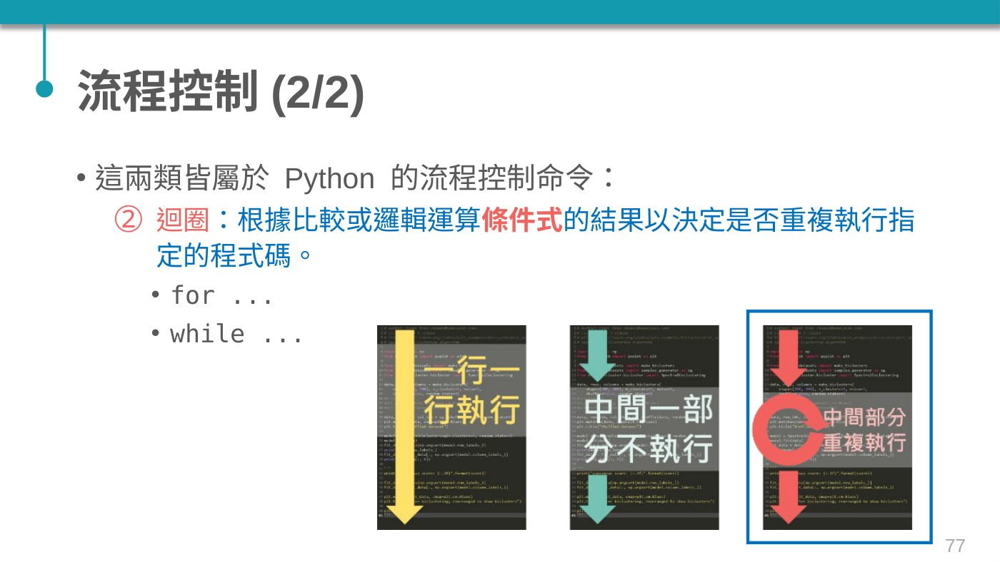

**講義文字（原稿轉錄）**

> 流程控制(2/2)

> 這兩類皆屬於 Python 的流程控制命令：

> 迴圈：根據比較或邏輯運算條件式的結果以決定是否重複執行指定的程式碼。

> for ...

> while ...

### P078｜主題

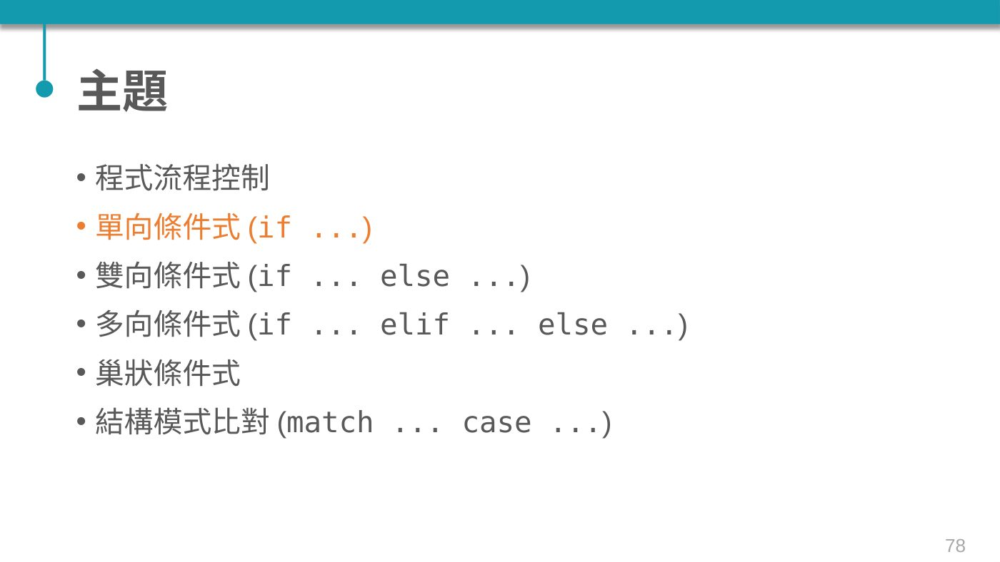

**講義文字（原稿轉錄）**

> 主題

> 程式流程控制

> 單向條件式(if ...)

> 雙向條件式(if ... else ...)

> 多向條件式(if ... elif ... else ...)

> 巢狀條件式

> 結構模式比對(match ... case ...)

### P079｜選擇敘述

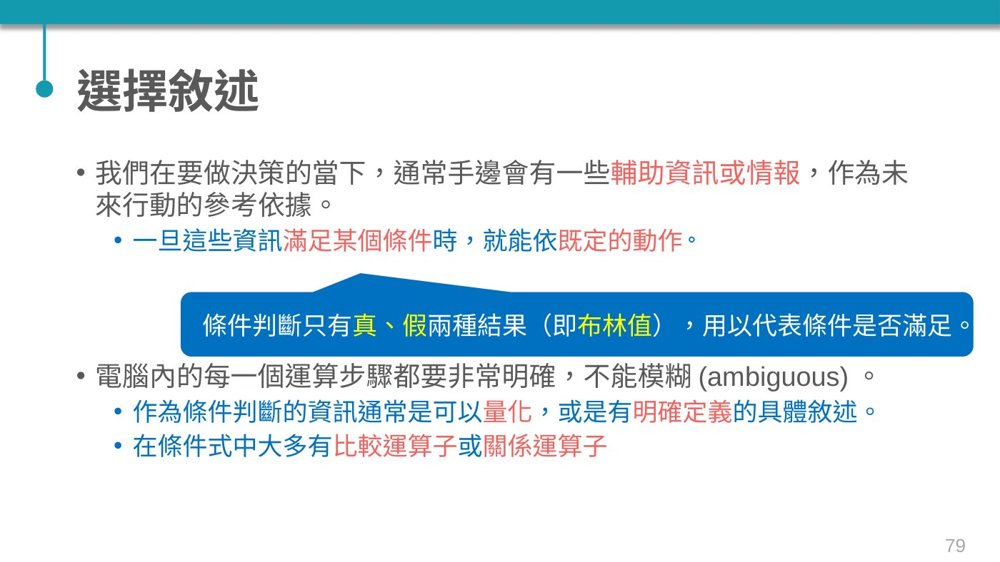

**講義文字（原稿轉錄）**

> 選擇敘述

> 我們在要做決策的當下，通常手邊會有一些輔助資訊或情報，作為未來行動的參考依據。

> 一旦這些資訊滿足某個條件時，就能依既定的動作來進行。

> 電腦內的每一個運算步驟都要非常明確，不能模糊(ambiguous)。

> 作為條件判斷的資訊通常是可以量化，或是有明確定義的具體敘述。

> 在條件式中大多有比較運算子或關係運算子

> 條件判斷只有真、假兩種結果（即布林值），用以代表條件是否滿足。

### P080｜範例

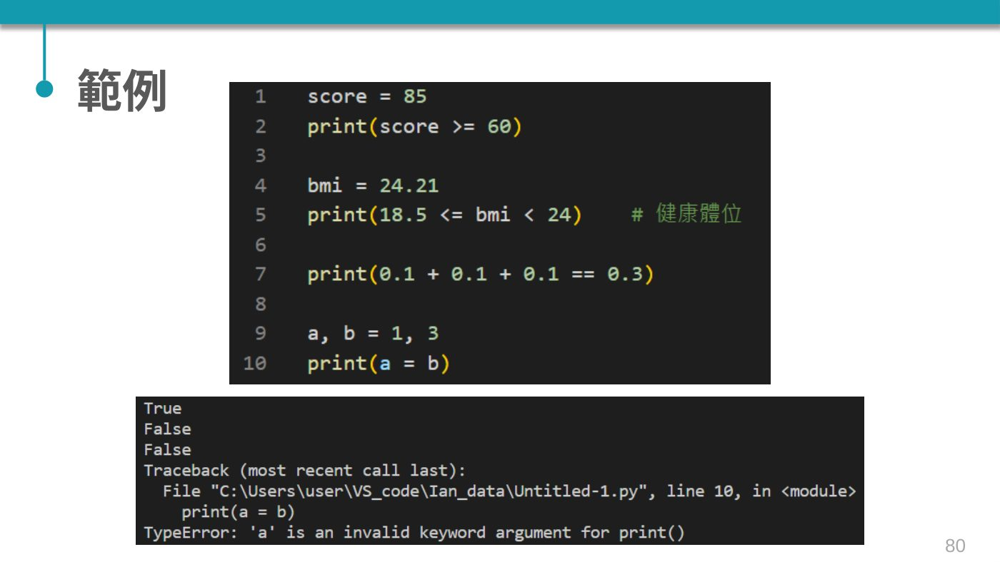

**講義文字（原稿轉錄）**

> 範例

In [88]:
score = 85
print(score >= 60)

bmi = 24.21
print(18.5 <= bmi < 24)

print(0.1 + 0.1 + 0.1 == 0.3)

a, b = 1, 3
print(a == b)

True
False
False
False


### P081｜單向條件式（if ...）

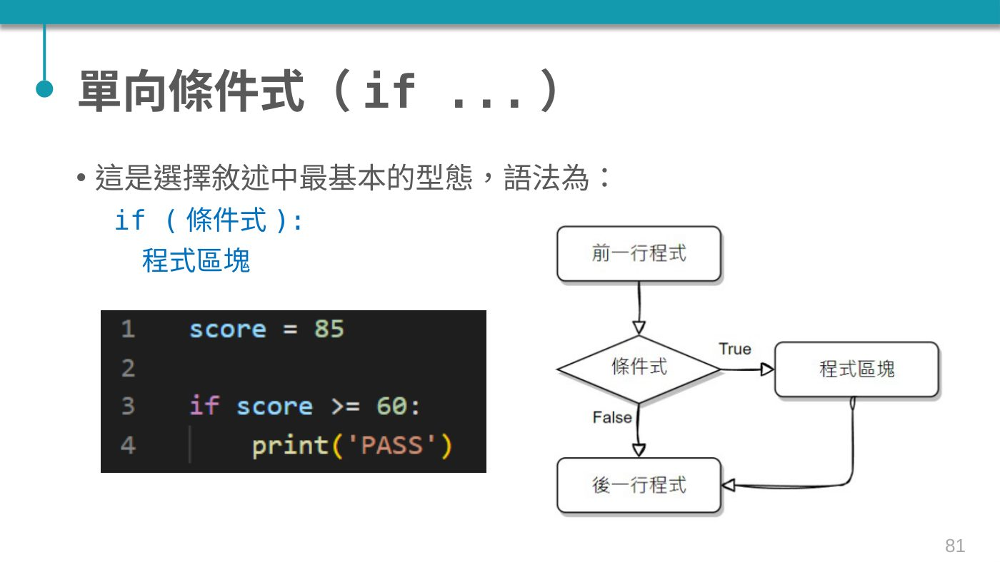

**講義文字（原稿轉錄）**

> 單向條件式（if ...）

> 這是選擇敘述中最基本的型態，語法為：

> if (條件式):

> 程式區塊

### P082｜if ...

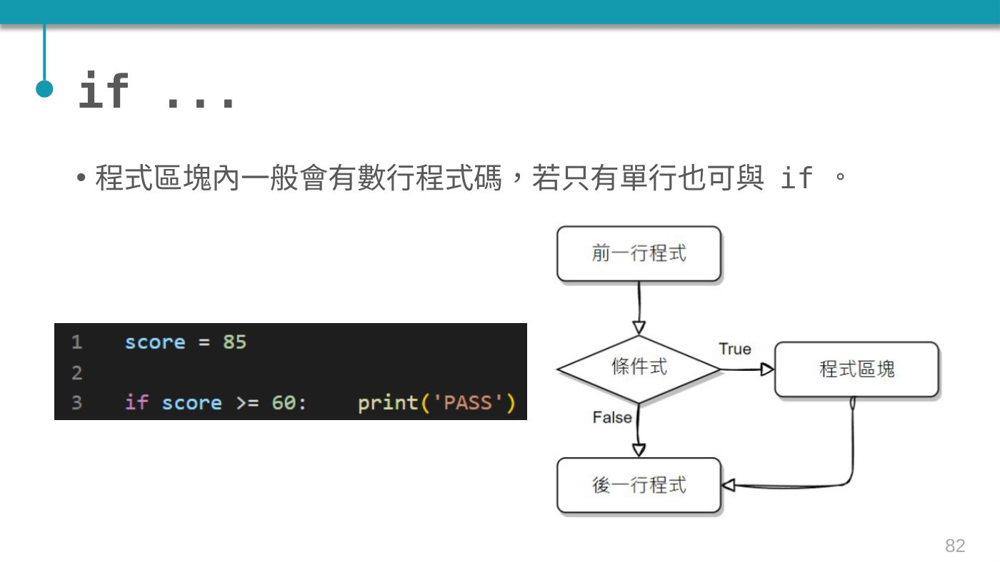

**講義文字（原稿轉錄）**

> if ...

> 程式區塊內一般會有數行程式碼，若只有單行也可與 if 敘述合併成一行。

#### 單向條件與基本流程

循序逐行執行；條件成立才進入縮排區塊。Python 使用冒號與縮排表示區塊。

In [89]:
score=85
if score >= 60:
    print('PASS')
    print('這一行也在 if 區塊內')
print('條件判斷結束')

PASS
這一行也在 if 區塊內
條件判斷結束


### P083｜有時會看到這種寫法

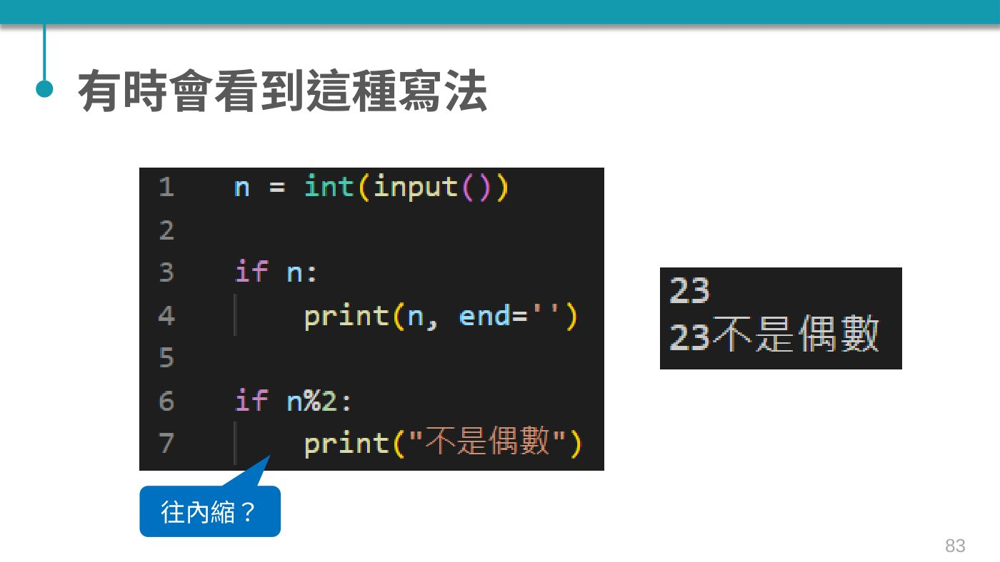

**講義文字（原稿轉錄）**

> 有時會看到這種寫法

> 往內縮？

In [98]:
n = int(input())

if n:
  print(n, end='')

if n % 2 != 0:
  print("這不是偶數")
else:
  print("這是偶數")

15
15這不是偶數


### P084｜縮排(indentation)

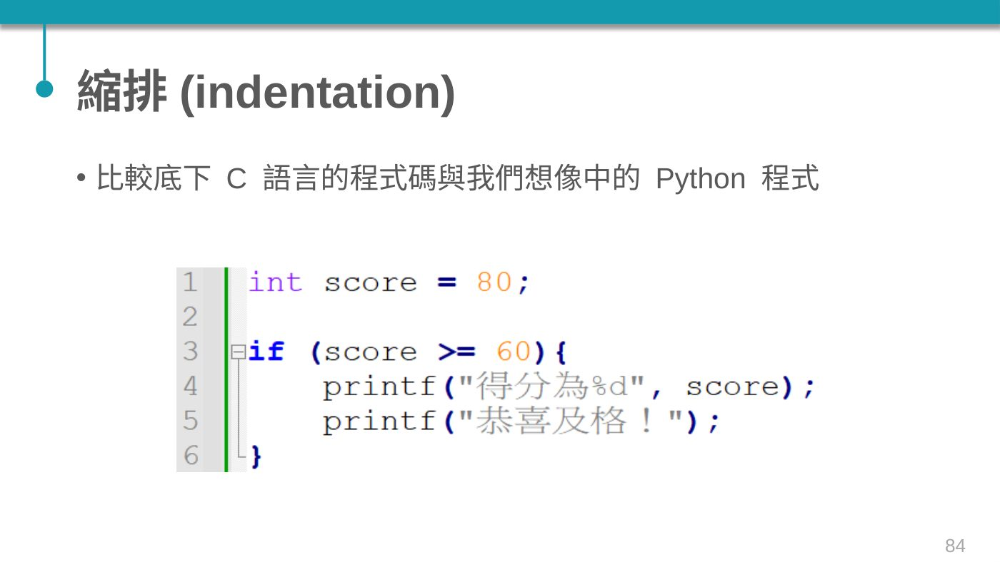

**講義文字（原稿轉錄）**

> 縮排(indentation)

> 比較底下 C 語言的程式碼與我們想像中的 Python 程式

### P085｜縮排

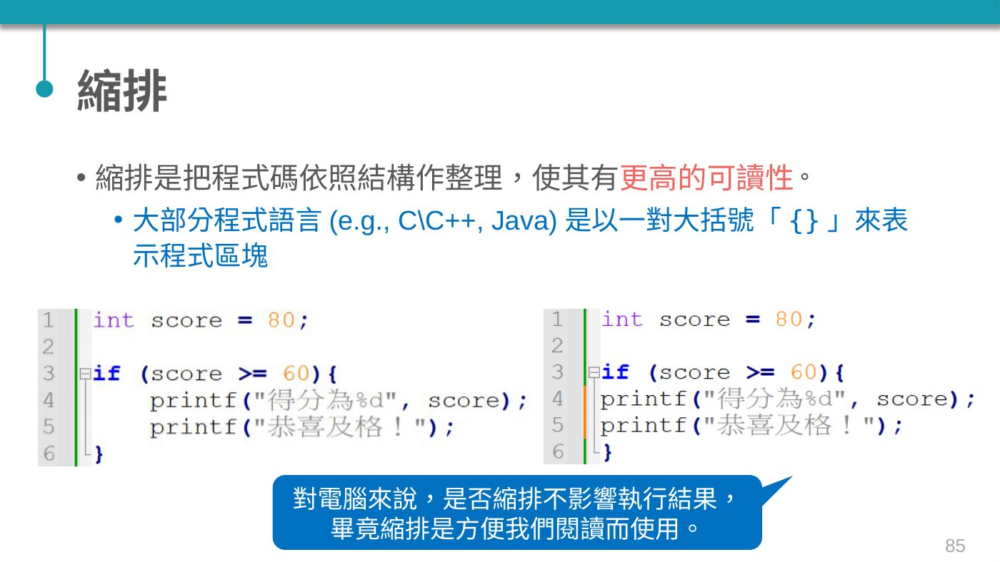

**講義文字（原稿轉錄）**

> 縮排

> 縮排是把程式碼依照結構作整理，使其有更高的可讀性。

> 大部分程式語言(e.g., C\C++, Java)是以一對大括號「{}」來表示程式區塊

> 對電腦來說，是否縮排不影響執行結果，畢竟縮排是方便我們閱讀而使用。

### P086｜Python 的縮排(1/2)

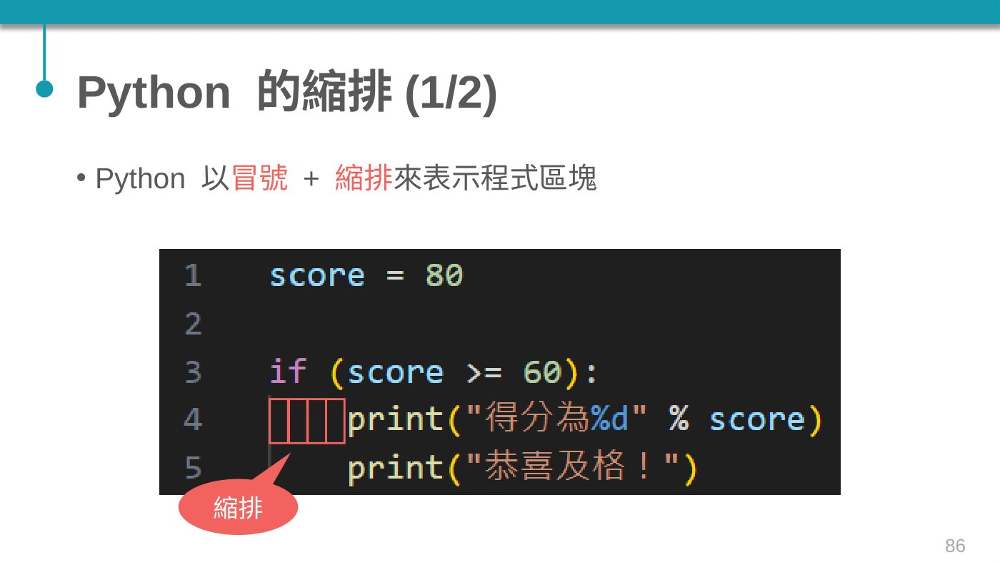

**講義文字（原稿轉錄）**

> Python 的縮排(1/2)

> Python 以冒號 + 縮排來表示程式區塊

> 縮排

### P087｜Python 的縮排(2/2)

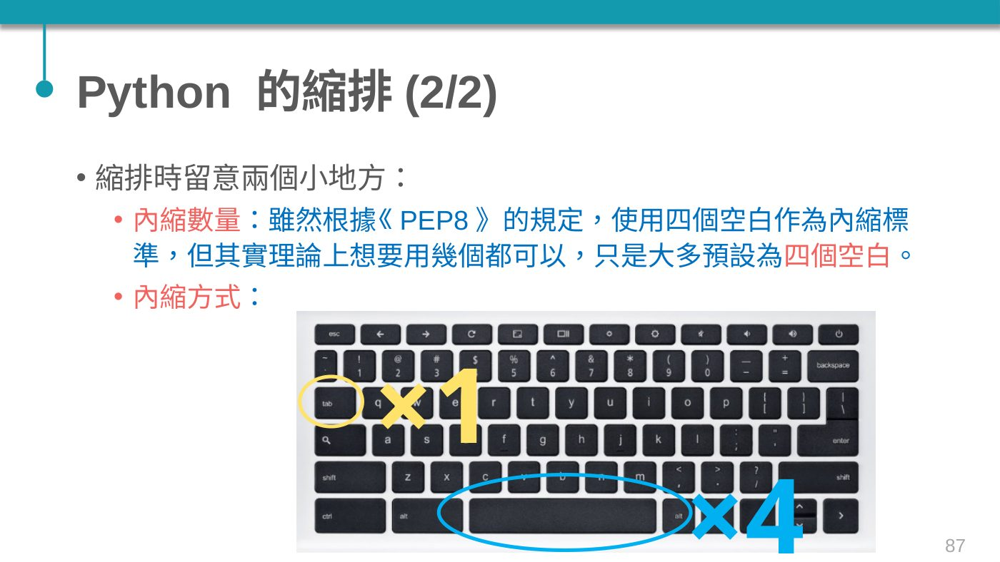

**講義文字（原稿轉錄）**

> Python 的縮排(2/2)

> 縮排時留意兩個小地方：

> 內縮數量：雖然根據《PEP8》的規定，使用四個空白作為內縮標準，但其實理論上想要用幾個都可以，只是大多預設為四個空白。

> 內縮方式：

> ×4

> ×1

### P088｜用哪一種有差嗎？

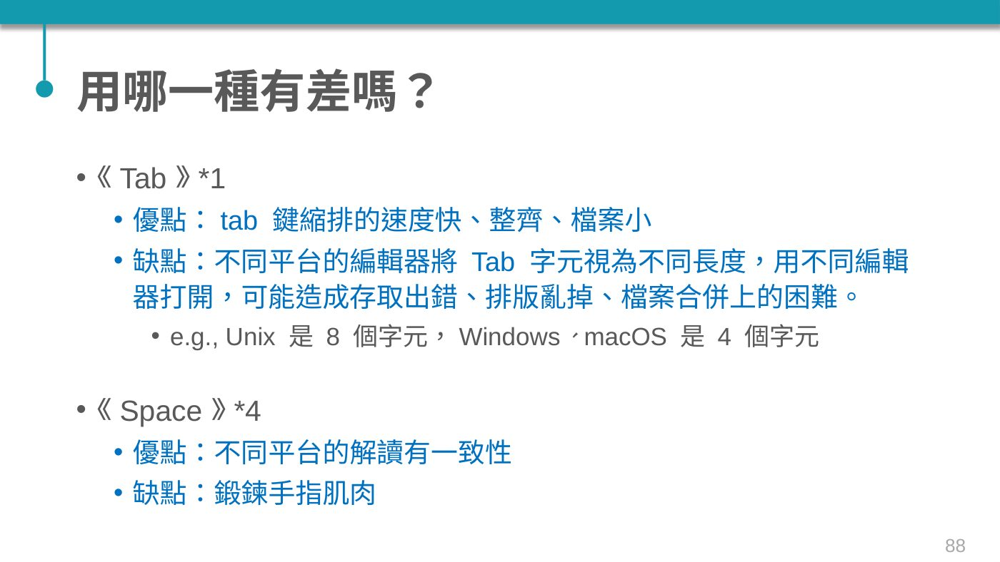

**講義文字（原稿轉錄）**

> 用哪一種有差嗎？

> 《Tab》*1

> 優點：tab 鍵縮排的速度快、整齊、檔案小

> 缺點：不同平台的編輯器將 Tab 字元視為不同長度，用不同編輯器打開，可能造成存取出錯、排版亂掉、檔案合併上的困難。

> e.g., Unix 是 8 個字元，Windows、macOS 是 4 個字元

> 《Space》*4

> 優點：不同平台的解讀有一致性

> 缺點：鍛鍊手指肌肉

### P089｜空白鍵 vs Tab鍵

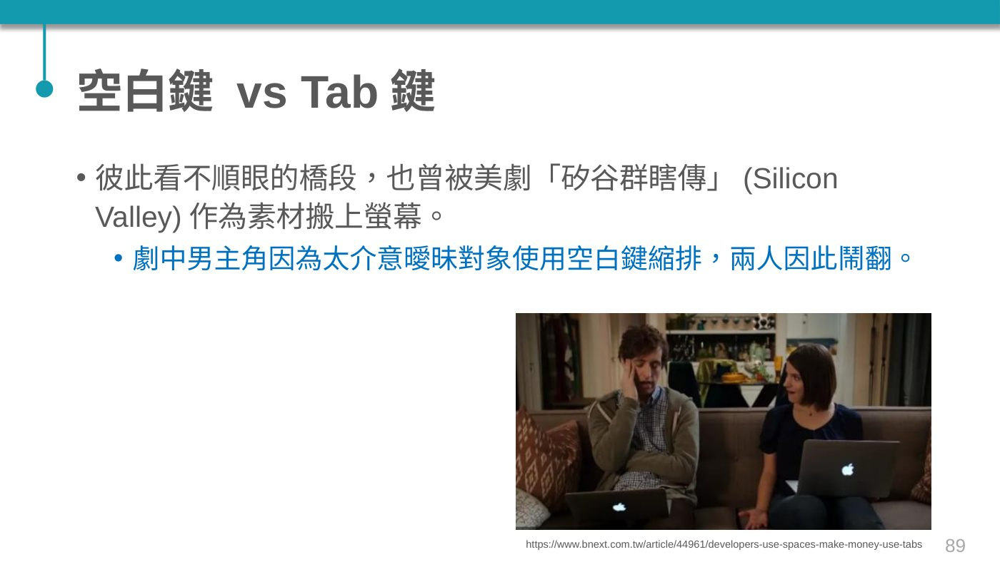

**講義文字（原稿轉錄）**

> 空白鍵 vs Tab鍵

> 彼此看不順眼的橋段，也曾被美劇「矽谷群瞎傳」(Silicon Valley)作為素材搬上螢幕。

> 劇中男主角因為太介意曖昧對象使用空白鍵縮排，兩人因此鬧翻。

> https://www.bnext.com.tw/article/44961/developers-use-spaces-make-money-use-tabs

### P090｜圖解與範例

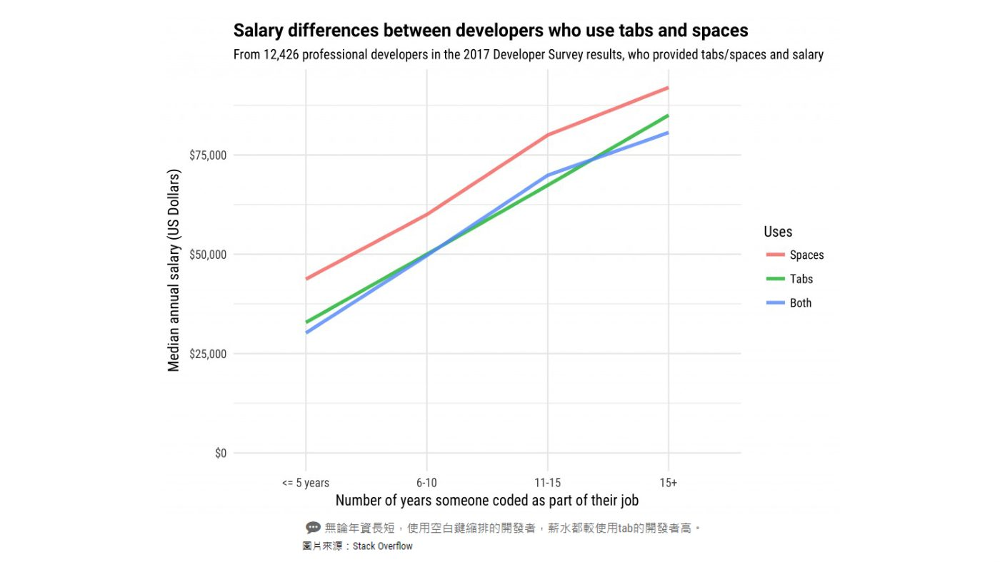

本頁以圖片為主，請閱讀上方原頁圖。

### P091｜圖解與範例

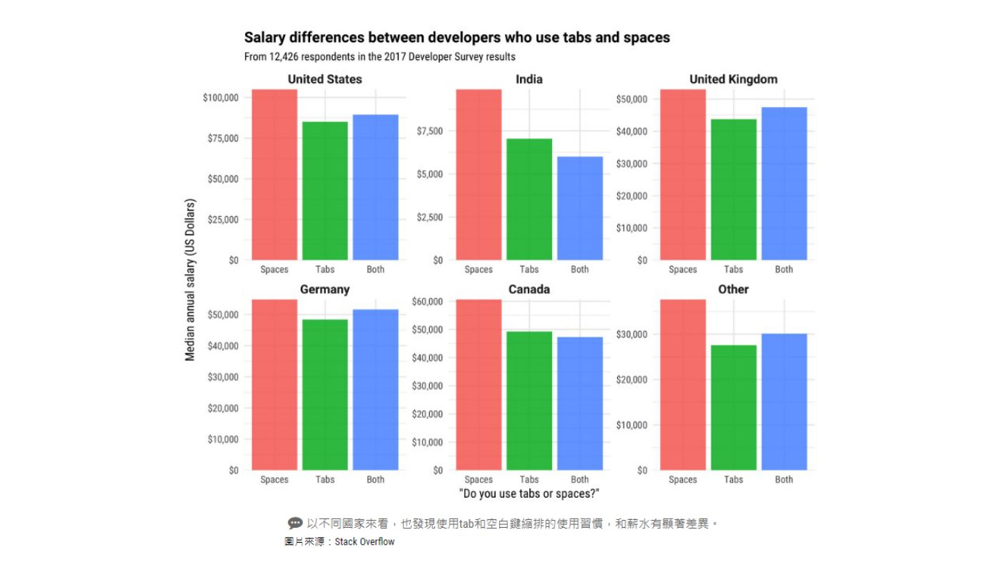

本頁以圖片為主，請閱讀上方原頁圖。

### P092｜圖解與範例

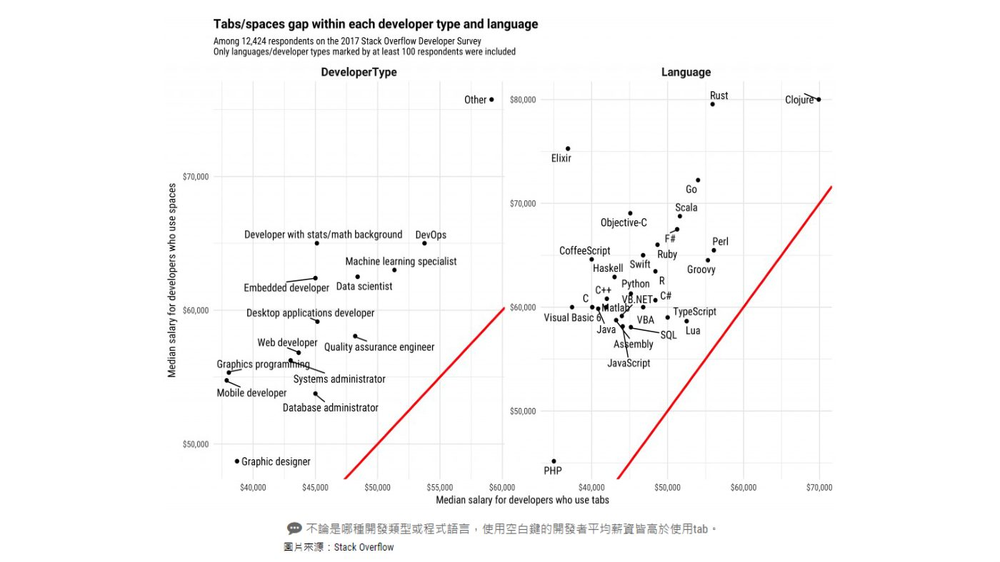

本頁以圖片為主，請閱讀上方原頁圖。

### P093｜分析結果

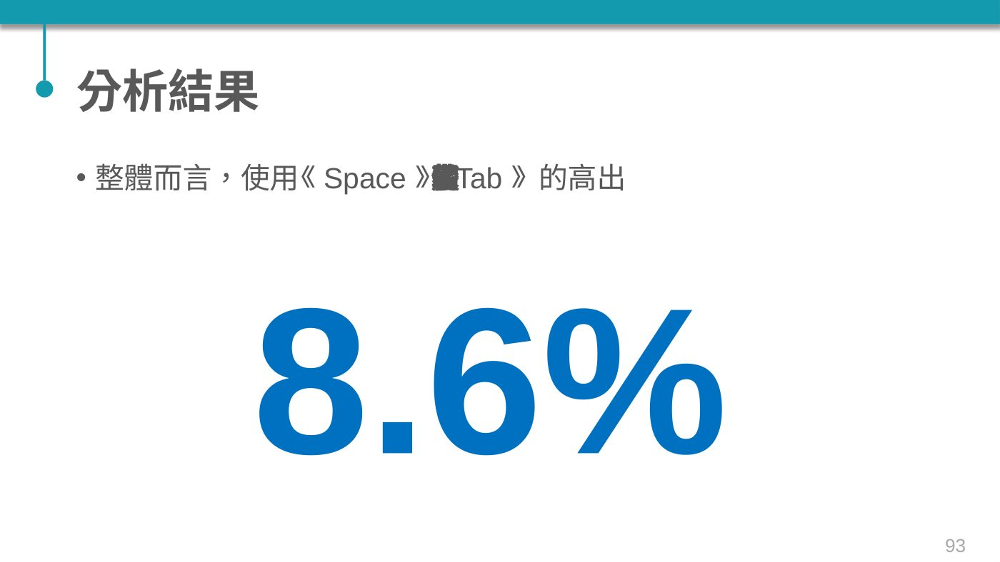

**講義文字（原稿轉錄）**

> 分析結果

> 整體而言，使用《Space》開發者的薪水較使用《Tab》的高出

> 8.6%

### P094｜Soft-Tab

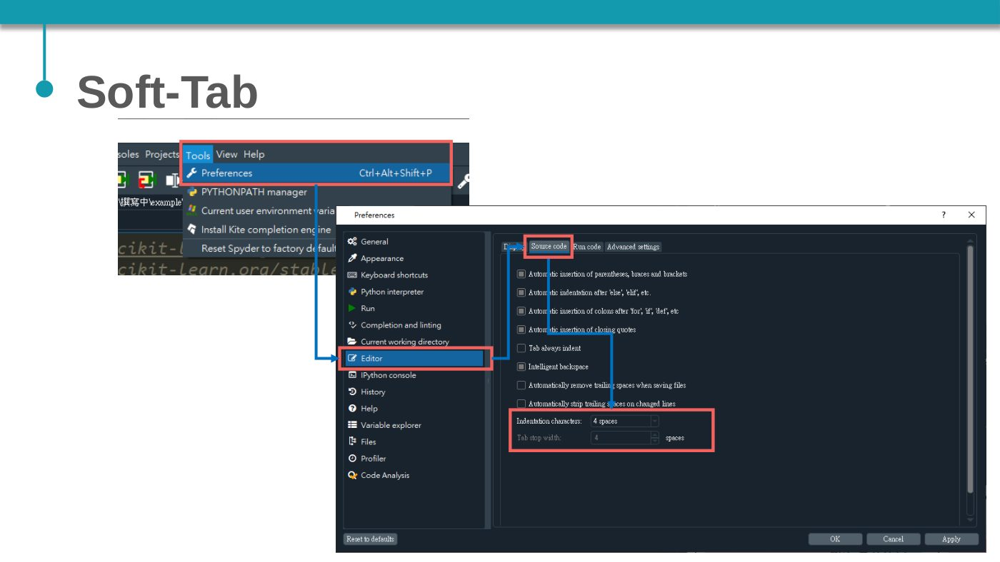

**講義文字（原稿轉錄）**

> Soft-Tab

#### 縮排與預期錯誤

原簡報的薪資圖表是歷史調查，不能推論縮排方式導致薪資差異。程式統一使用四個空白；編輯器的 Tab 可設定為插入四個空白。

In [99]:
bad_code='if True:\nprint("缺少縮排")'
try:
    compile(bad_code,'教學範例','exec')
except IndentationError as error:
    print('預期的縮排錯誤：',error.msg)
if True:
    print('四個空白縮排正確')

預期的縮排錯誤： expected an indented block after 'if' statement on line 1
四個空白縮排正確


<a id="section-95"></a>

## P095 起｜雙向條件與三元運算

### P095｜主題

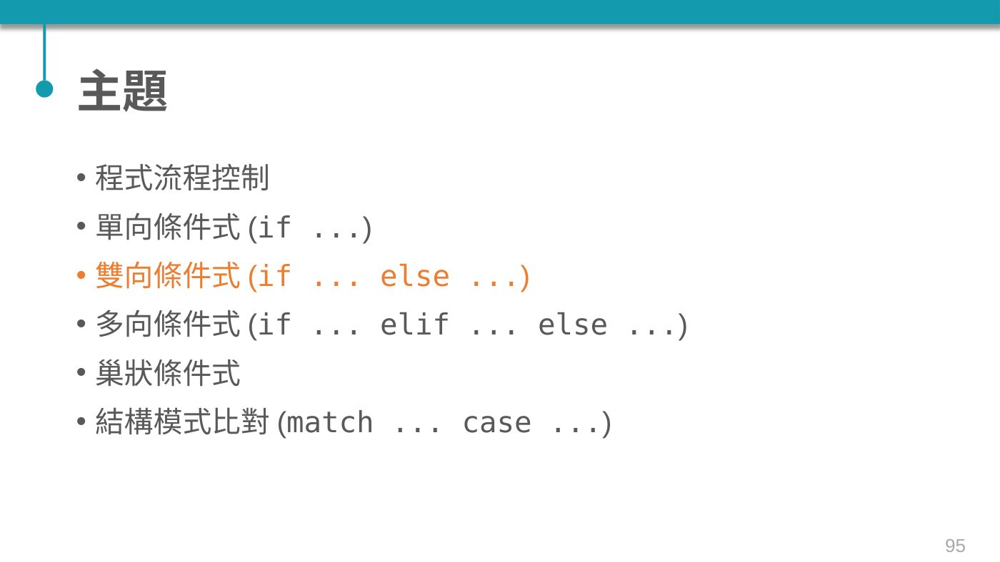

**講義文字（原稿轉錄）**

> 主題

> 程式流程控制

> 單向條件式(if ...)

> 雙向條件式(if ... else ...)

> 多向條件式(if ... elif ... else ...)

> 巢狀條件式

> 結構模式比對(match ... case ...)

### P096｜雙向條件式(if ... else ...)

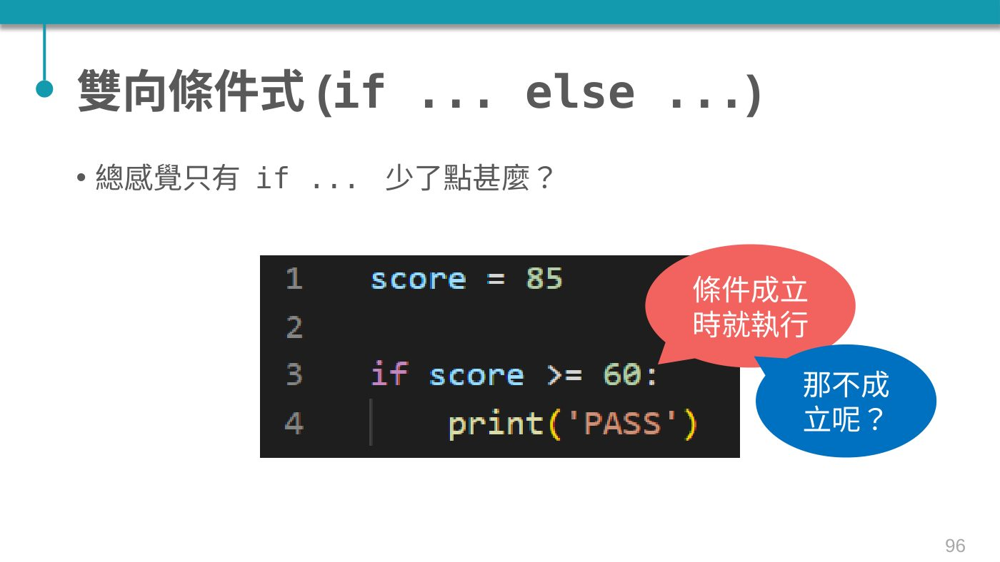

**講義文字（原稿轉錄）**

> 雙向條件式(if ... else ...)

> 總感覺只有 if ... 少了點甚麼？

> 條件成立時就執行

> 那不成立呢？

### P097｜雙向條件式

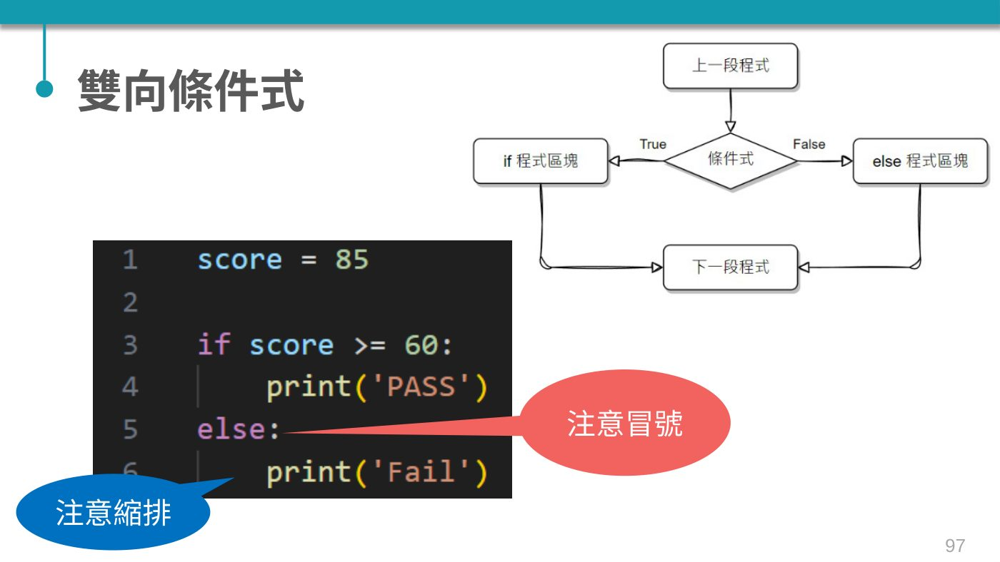

**講義文字（原稿轉錄）**

> 雙向條件式

> 注意冒號

> 注意縮排

### P098｜三元運算子(1/3)

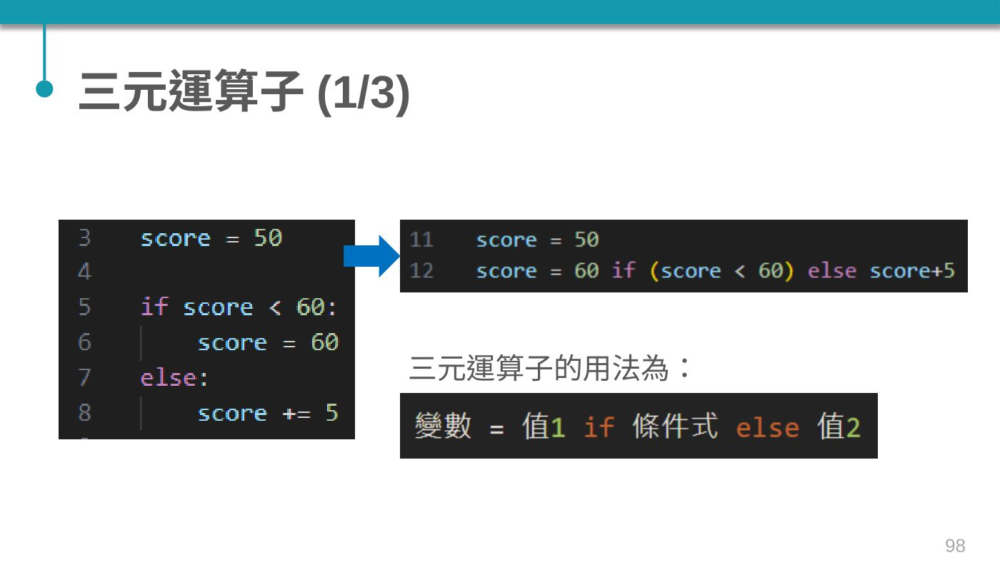

**講義文字（原稿轉錄）**

> 三元運算子(1/3)

> 三元運算子的用法為：

### P099｜三元運算子(2/3)

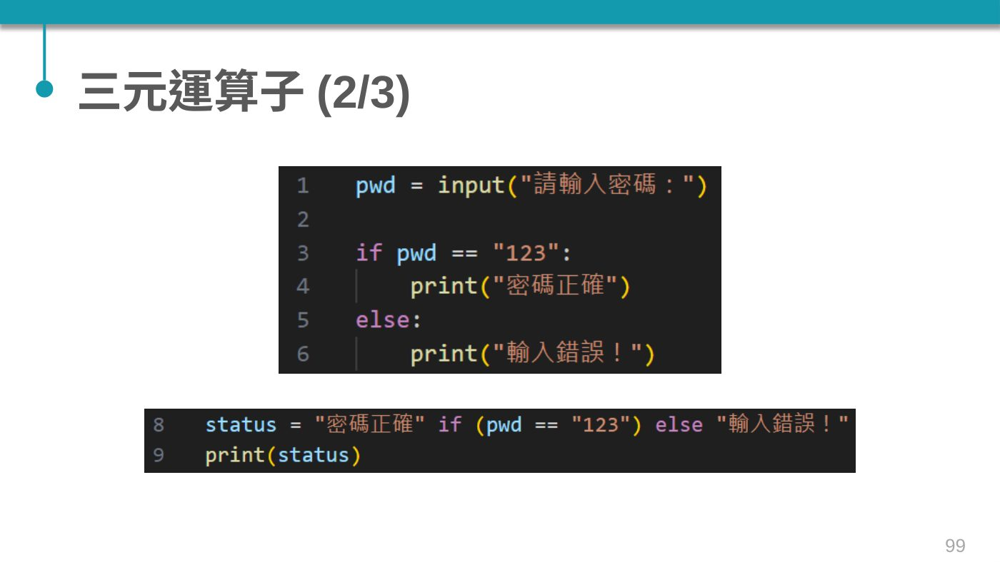

**講義文字（原稿轉錄）**

> 三元運算子(2/3)

### P100｜三元運算子(3/3)

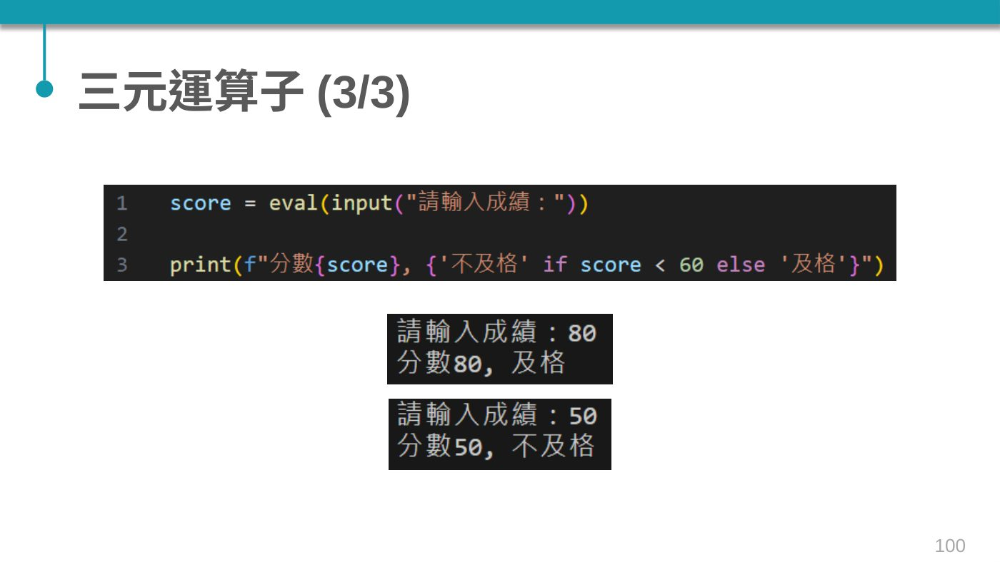

**講義文字（原稿轉錄）**

> 三元運算子(3/3)

#### 雙向條件與條件運算式

先練習 if/else，再改寫成「成立值 if 條件 else 不成立值」。範例密碼只是字串比較教學。

In [100]:
score=85
if score>=60:
    print('PASS')
else:
    print('Fail')
pwd='123'
status='密碼正確' if pwd=='123' else '輸入錯誤！'
print(status)
print(f"分數{score}，{'不及格' if score<60 else '及格'}")

PASS
密碼正確
分數85，及格


### P101｜練習：英制與公制互換

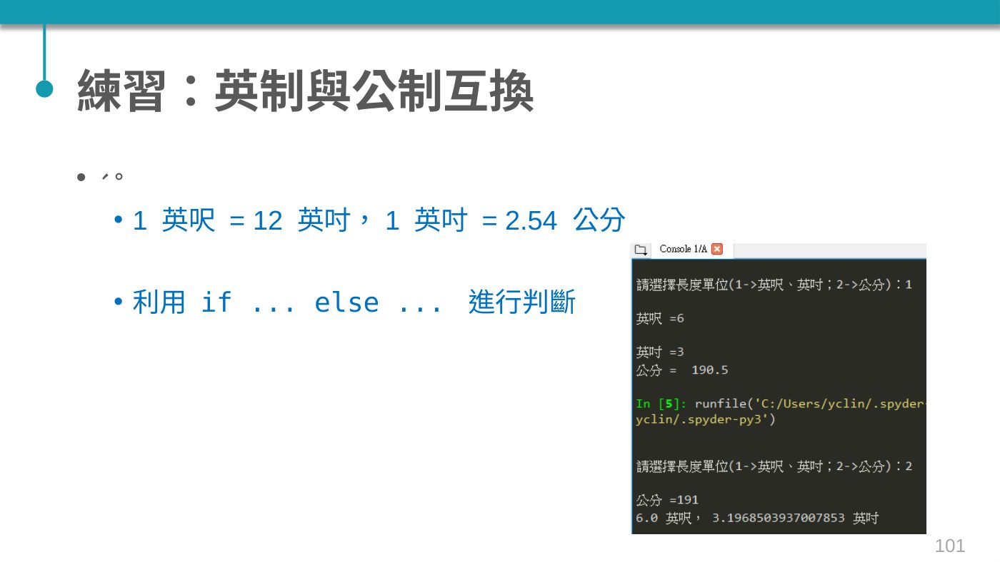

**講義文字（原稿轉錄）**

> 練習：英制與公制互換

> 國外長度單位常使用英制單位，例如身高常使用英呎、英吋表示，請寫一程式進行長度單位的輸入與轉換。

> 1 英呎 = 12 英吋，1 英吋 = 2.54 公分

> 利用 if ... else ... 進行判斷

<a id="answer-101"></a>

#### 習題解答｜英制與公制互換

1 表示英呎、英吋轉公分；2 表示公分轉英呎、英吋。英吋不足一英呎的部分可保留小數。6 呎 3 吋應為 190.5 公分；191 公分約為 6 呎 3.19685 吋。

**先練習**：依上方原題與提示，自行寫出步驟及程式。可修改輸入資料，測試正常值與邊界值。下方空白練習格不影響全部執行。

In [ ]:
# 我的練習區：請在此撰寫程式。
# 建議先寫輸入、處理、輸出三個步驟。

**參考解答與驗收**

觀察印出的結果，並閱讀 `assert` 檢核；若條件不成立，會出現 AssertionError。

In [ ]:
def convert_length(unit, first, inches=0):
    if not all(math.isfinite(x) for x in [first,inches]) or first<0 or inches<0:
        raise ValueError('長度須為有限非負數')
    if unit==1:
        return (first*12+inches)*2.54
    else:
        if unit!=2:
            raise ValueError('單位只能選 1 或 2')
        total_inches=first/2.54
        feet=int(total_inches//12)
        return feet,total_inches-feet*12
ask=make_input(['1','6','3'])
unit=int(ask('原單位 1=英制、2=公分：'))
if unit==1:
    feet=float(ask('英呎：')); inches=float(ask('英吋：'))
    print('公分：',convert_length(unit,feet,inches))
else:
    cm=float(ask('公分：'))
    print('英呎、英吋：',convert_length(unit,cm))
print('191 公分 =',convert_length(2,191))
assert math.isclose(convert_length(1,6,3),190.5)

原單位 1=英制、2=公分：1
英呎：6
英吋：3
公分： 190.5
191 公分 = (6, 3.1968503937007853)


### P102｜練習：計算導數值

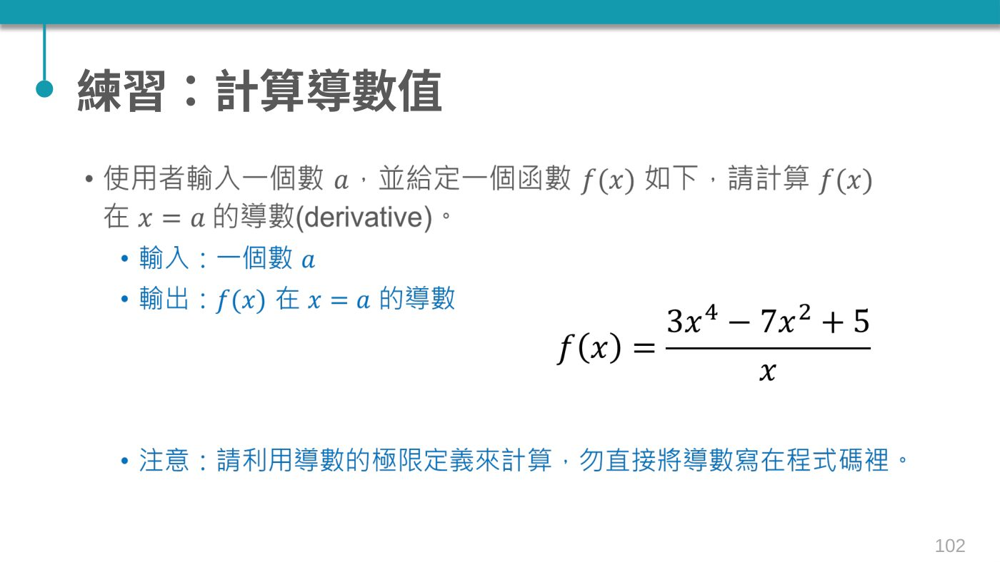

**講義文字（原稿轉錄）**

> 練習：計算導數值

> 使用者輸入一個數 𝑎，並給定一個函數 𝑓(𝑥) 如下，請計算 𝑓(𝑥) 在 𝑥=𝑎 的導數(derivative)。

> 輸入：一個數 𝑎

> 輸出：𝑓(𝑥) 在 𝑥=𝑎 的導數

> 注意：請利用導數的極限定義來計算，勿直接將導數寫在程式碼裡。

> 𝑓𝑥=3𝑥4−7𝑥2+5𝑥

<a id="answer-102"></a>

#### 習題解答｜有定義域限制的數值導數

本題與第 57 頁不同：$f(x)=(3x^4-7x^2+5)/x$，定義域排除 0。先用條件式檢查 a，再使用差商近似；h 取小於 |a| 的值以避免跨越 0。

**先練習**：依上方原題與提示，自行寫出步驟及程式。可修改輸入資料，測試正常值與邊界值。下方空白練習格不影響全部執行。

In [ ]:
# 我的練習區：請在此撰寫程式。
# 建議先寫輸入、處理、輸出三個步驟。

**參考解答與驗收**

觀察印出的結果，並閱讀 `assert` 檢核；若條件不成立，會出現 AssertionError。

In [ ]:
def rational_f(x):
    if x==0:
        raise ValueError('x=0 不在定義域內')
    return (3*x**4-7*x**2+5)/x
ask=make_input(['2'])
a=float(ask('a（不可為0）：'))
if a==0:
    print('a=0，函數與導數皆未定義')
else:
    h=min(1e-5,abs(a)/1000)
    derivative=(rational_f(a+h)-rational_f(a-h))/(2*h)
    print(f'數值導數約為 {derivative:.6f}')
h=1e-5
assert math.isclose((rational_f(2+h)-rational_f(2-h))/(2*h),27.75,abs_tol=1e-6)

a（不可為0）：2
數值導數約為 27.750000


<a id="section-103"></a>

## P103 起｜多向條件

### P103｜主題

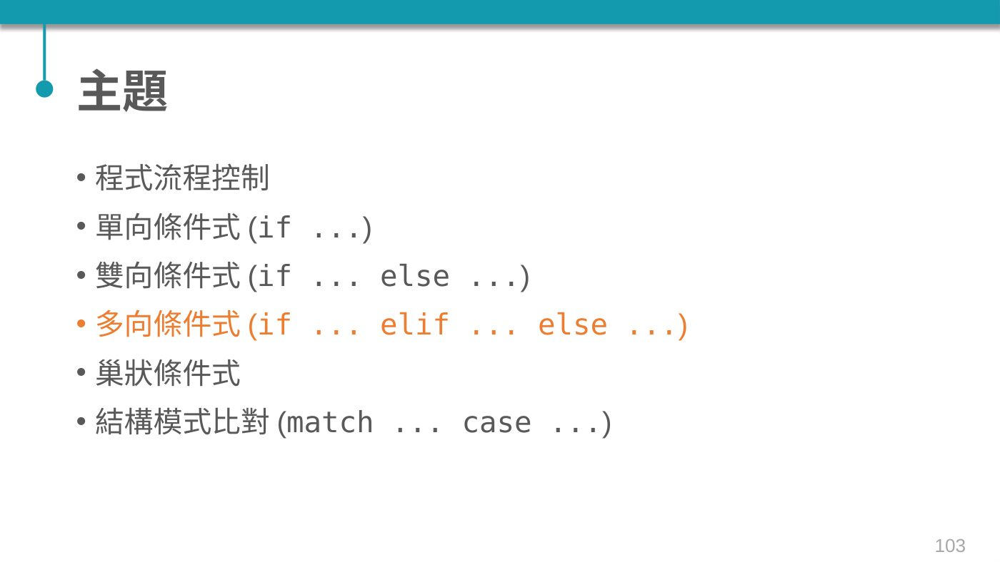

**講義文字（原稿轉錄）**

> 主題

> 程式流程控制

> 單向條件式(if ...)

> 雙向條件式(if ... else ...)

> 多向條件式(if ... elif ... else ...)

> 巢狀條件式

> 結構模式比對(match ... case ...)

### P104｜範例

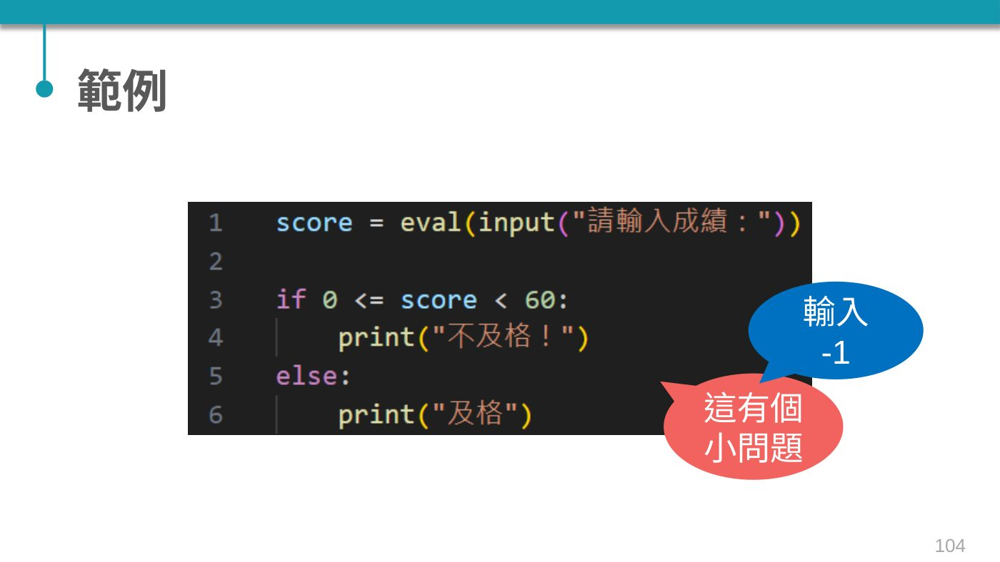

**講義文字（原稿轉錄）**

> 範例

> 這有個小問題

> 輸入 -1

### P105｜修改一下

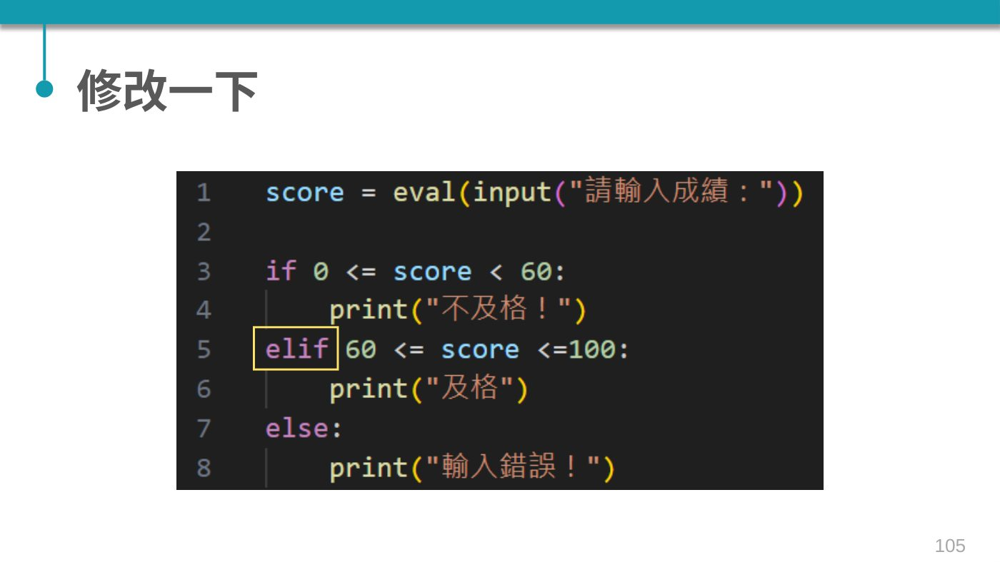

**講義文字（原稿轉錄）**

> 修改一下

### P106｜多向條件式(if ... elif ... else ...)

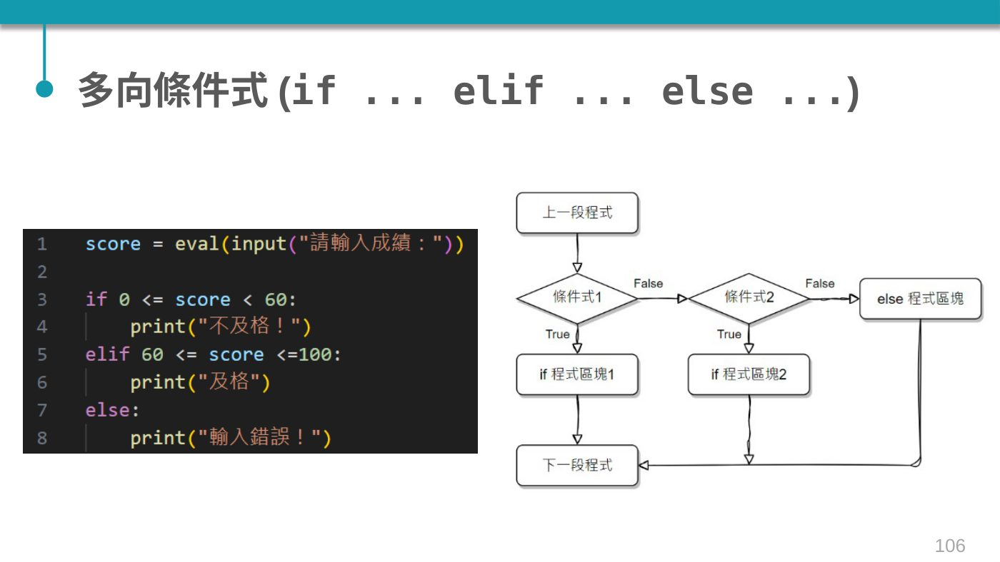

**講義文字（原稿轉錄）**

> 多向條件式(if ... elif ... else ...)

### P107｜範例

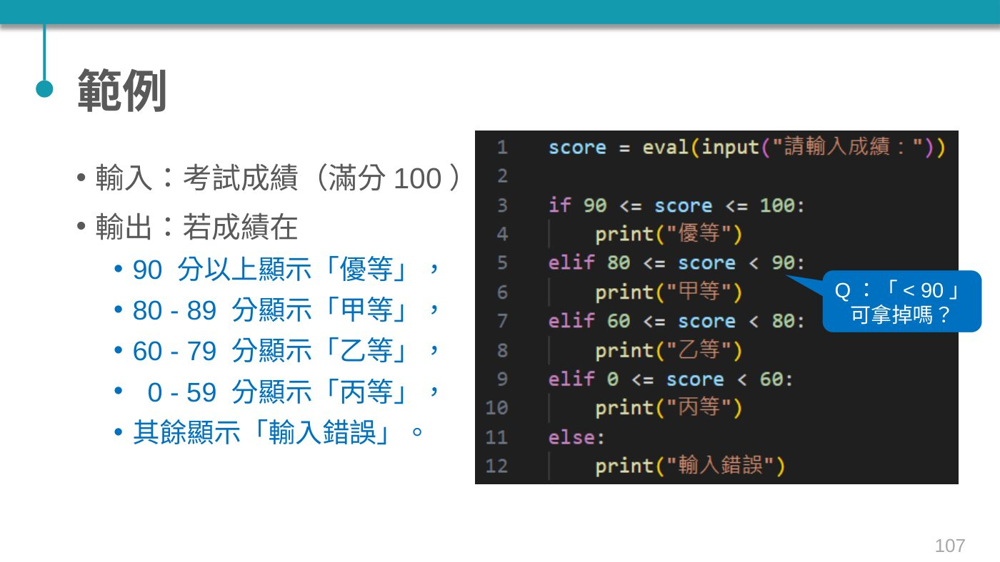

**講義文字（原稿轉錄）**

> 範例

> 輸入：考試成績（滿分100）

> 輸出：若成績在

> 90 分以上顯示「優等」，

> 80 - 89 分顯示「甲等」，

> 60 - 79 分顯示「乙等」，

> 0 - 59 分顯示「丙等」，

> 其餘顯示「輸入錯誤」。

> Q：「&lt; 90」 可拿掉嗎？

#### 多向條件與分數邊界

先排除不合法分數，再由高到低判斷。前面分支不成立才會走到後面，因此不必每一段都再檢查上界。

In [101]:
def grade(score):
    if not 0<=score<=100:
        return '輸入錯誤'
    elif score>=90:
        return '優等'
    elif score>=80:
        return '甲等'
    elif score>=60:
        return '乙等'
    else:
        return '丙等'
for score in [-1,0,59,60,79,80,89,90,100,101]:
    print(score,grade(score))
assert grade(-1)=='輸入錯誤' and grade(60)=='乙等'

-1 輸入錯誤
0 丙等
59 丙等
60 乙等
79 乙等
80 甲等
89 甲等
90 優等
100 優等
101 輸入錯誤


<a id="section-108"></a>

## P108 起｜巢狀條件

### P108｜主題

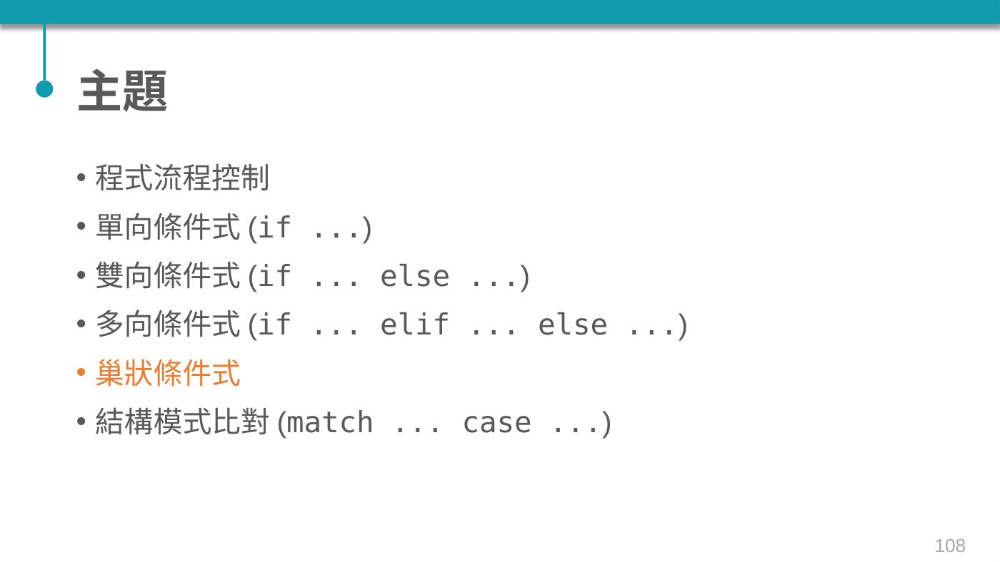

**講義文字（原稿轉錄）**

> 主題

> 程式流程控制

> 單向條件式(if ...)

> 雙向條件式(if ... else ...)

> 多向條件式(if ... elif ... else ...)

> 巢狀條件式

> 結構模式比對(match ... case ...)

### P109｜巢狀(nested)

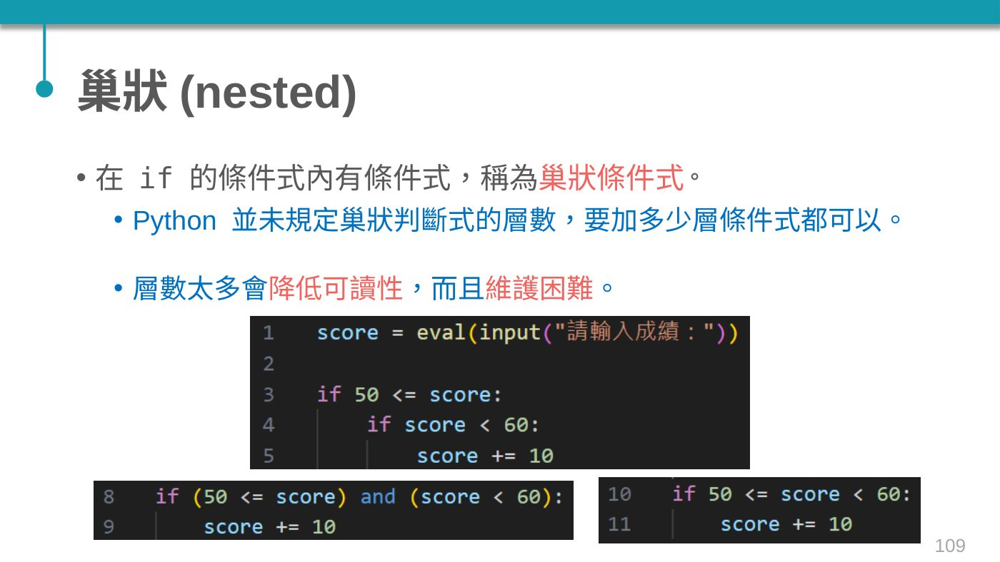

**講義文字（原稿轉錄）**

> 巢狀(nested)

> 在 if 的條件式內有條件式，稱為巢狀條件式。

> Python 並未規定巢狀判斷式的層數，要加多少層條件式都可以。

> 層數太多會降低可讀性，而且維護困難。

In [ ]:
# Python 寫法：
# 寫法 A：巢狀 (Nested)
if 50 <= score:
    if score < 60:
        score += 10

# 寫法 B：使用 and 運算子
if (50 <= score) and (score < 60):
    score += 10

In [ ]:
// C / C++ 對應寫法：
// 寫法 A：巢狀 (Nested)
if (50 <= score) {
    if (score < 60) {
        score += 10;
    }
}

// 寫法 B：使用 && 運算子
if (50 <= score && score < 60) {
    score += 10;
}

### P110｜哪個比較容易閱讀？

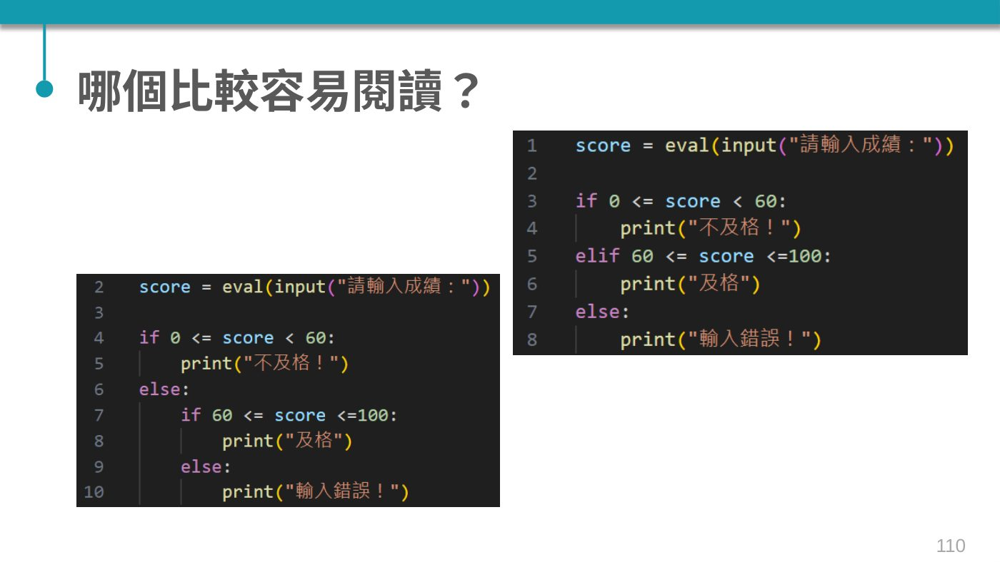

**講義文字（原稿轉錄）**

> 哪個比較容易閱讀？

### P111｜練習：成績評等

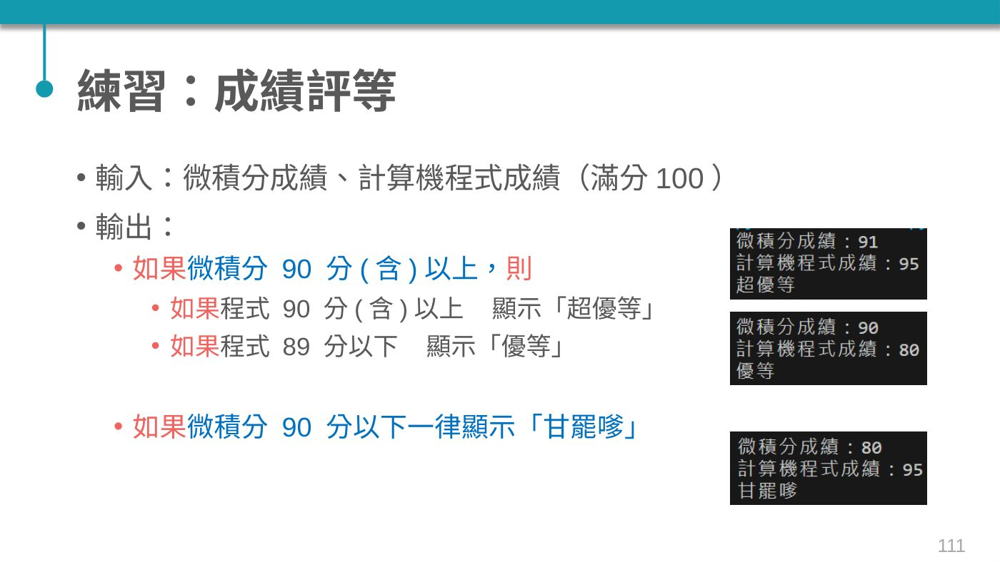

**講義文字（原稿轉錄）**

> 練習：成績評等

> 輸入：微積分成績、計算機程式成績（滿分100）

> 輸出：

> 如果微積分 90 分(含)以上，則

> 如果程式 90 分(含)以上  顯示「超優等」

> 如果程式 89 分以下  顯示「優等」

> 如果微積分 90 分以下一律顯示「甘罷嗲」

<a id="answer-111"></a>

#### 習題解答｜巢狀成績評等

先判斷微積分是否達 90，再判斷程式是否達 90。補充：兩科都須在 0～100。原文「90 分以下」與「90 分含以上」重疊，此處依題目順序將不足 90 解讀為 <90。

**先練習**：依上方原題與提示，自行寫出步驟及程式。可修改輸入資料，測試正常值與邊界值。下方空白練習格不影響全部執行。

In [ ]:
# 我的練習區：請在此撰寫程式。
# 建議先寫輸入、處理、輸出三個步驟。

**參考解答與驗收**

觀察印出的結果，並閱讀 `assert` 檢核；若條件不成立，會出現 AssertionError。

In [ ]:
def two_grades(calculus,programming):
    if not (0<=calculus<=100 and 0<=programming<=100):
        return '輸入錯誤'
    if calculus>=90:
        if programming>=90:
            return '超優等'
        else:
            return '優等'
    else:
        return '甘罷嗲'
ask=make_input(['90','89'])
a=float(ask('微積分：')); b=float(ask('計算機程式：'))
print(two_grades(a,b))
assert two_grades(90,90)=='超優等'
assert two_grades(90,89)=='優等'
assert two_grades(89,100)=='甘罷嗲'

微積分：90
計算機程式：89
優等


<a id="section-112"></a>

## P112 起｜結構模式比對

### P112｜主題

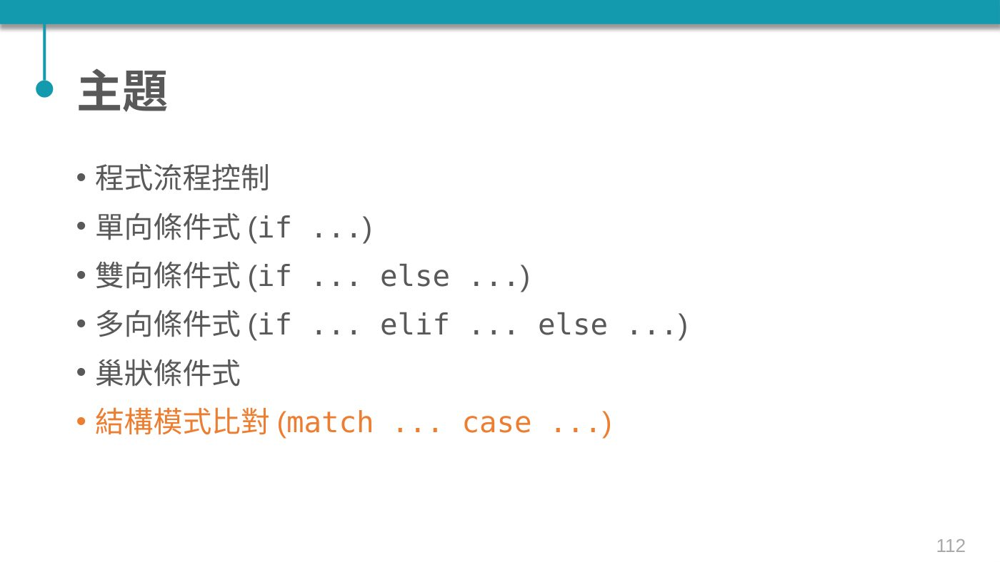

**講義文字（原稿轉錄）**

> 主題

> 程式流程控制

> 單向條件式(if ...)

> 雙向條件式(if ... else ...)

> 多向條件式(if ... elif ... else ...)

> 巢狀條件式

> 結構模式比對(match ... case ...)

### P113｜switch 敘述

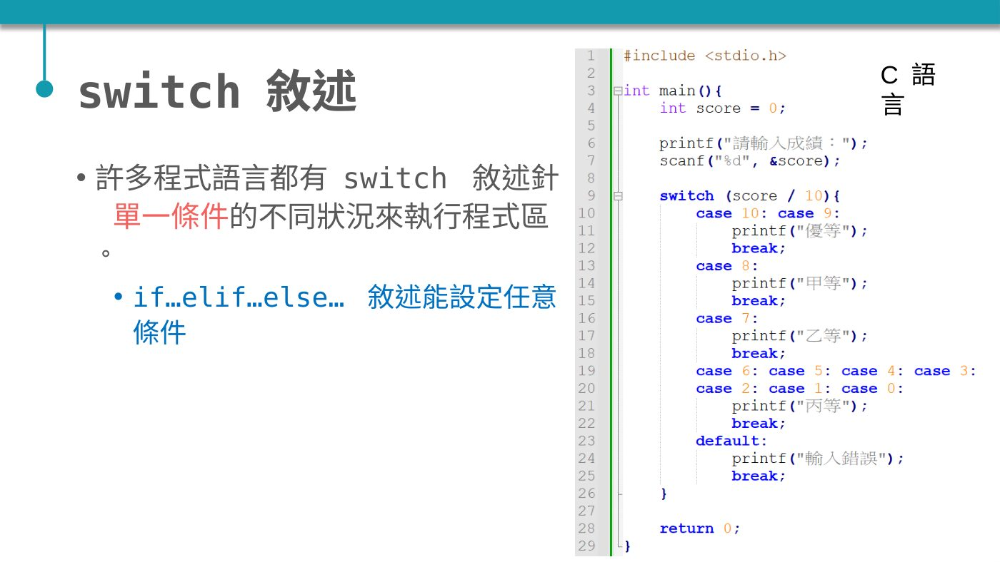

**講義文字（原稿轉錄）**

> switch 敘述

> 許多程式語言都有 switch 敘述針對單一條件的不同狀況來執行程式區塊，有些時候會比多向條件式更直覺些。

> if…elif…else… 敘述能設定任意條件

> C 語言

### P114｜Python 沒有類似 switch 的語法

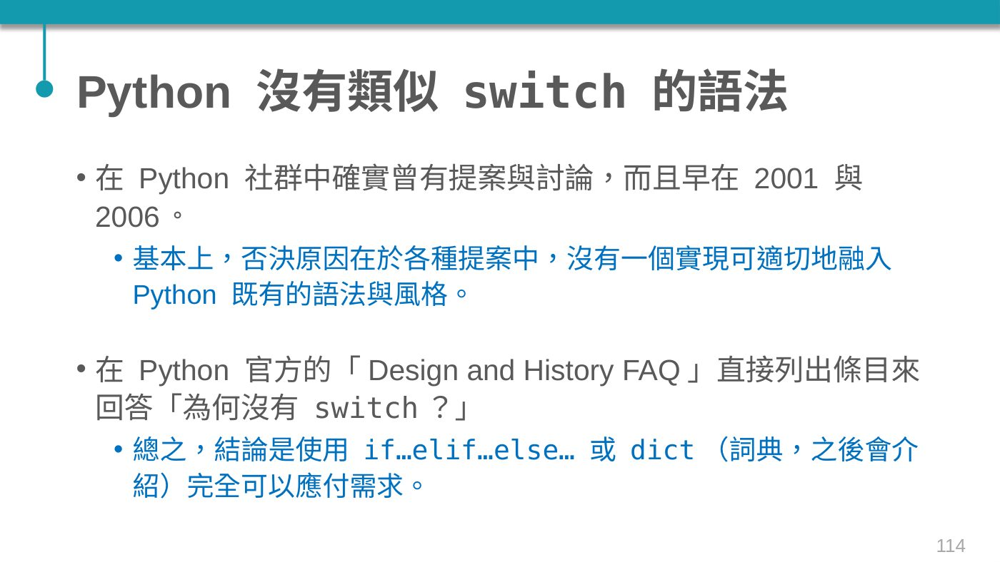

**講義文字（原稿轉錄）**

> Python 沒有類似 switch 的語法

> 在 Python 社群中確實曾有提案與討論，而且早在 2001 與 2006年就提出，可是最終都被否決了。

> 基本上，否決原因在於各種提案中，沒有一個實現可適切地融入 Python 既有的語法與風格。

> 在 Python 官方的「Design and History FAQ」直接列出條目來回答「為何沒有 switch？」

> 總之，結論是使用 if…elif…else… 或 dict（詞典，之後會介紹）完全可以應付需求。

### P115｜結構模式比對(match ... case ...)

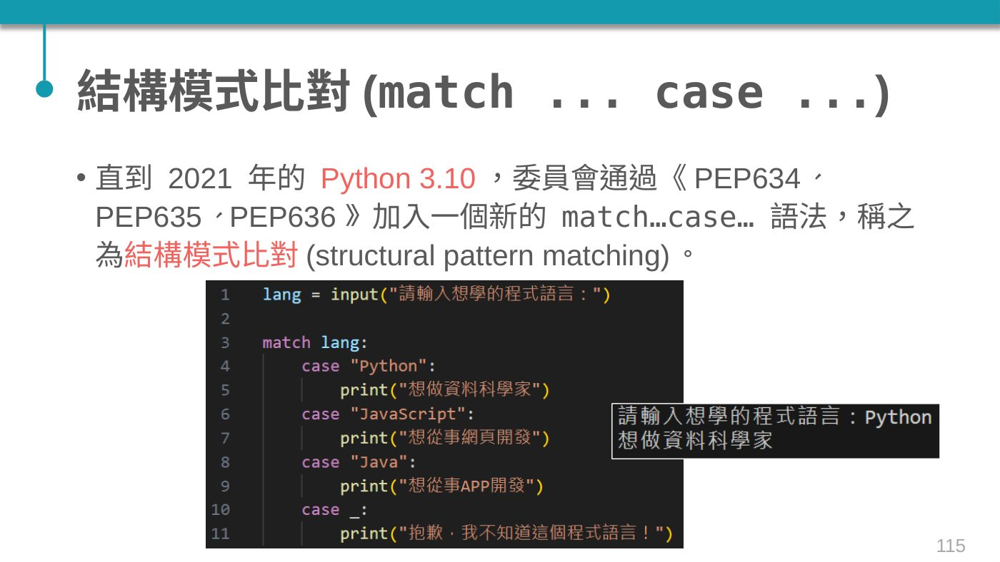

**講義文字（原稿轉錄）**

> 結構模式比對(match ... case ...)

> 直到 2021 年的 Python 3.10，委員會通過《PEP634、PEP635、PEP636》加入一個新的 match…case… 語法，稱之為結構模式比對(structural pattern matching)。

### P116｜C 語言

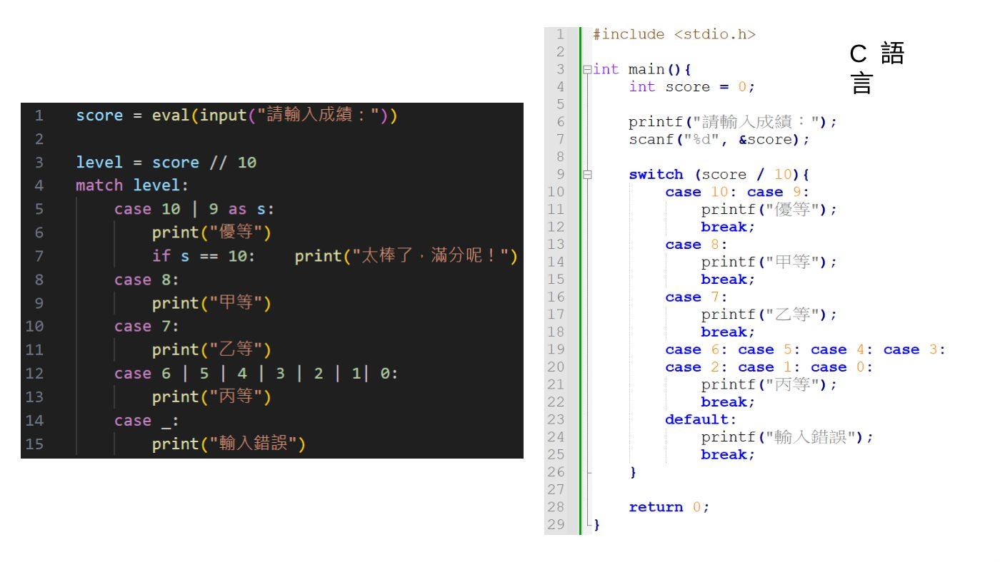

**講義文字（原稿轉錄）**

> C 語言

### P117｜注意

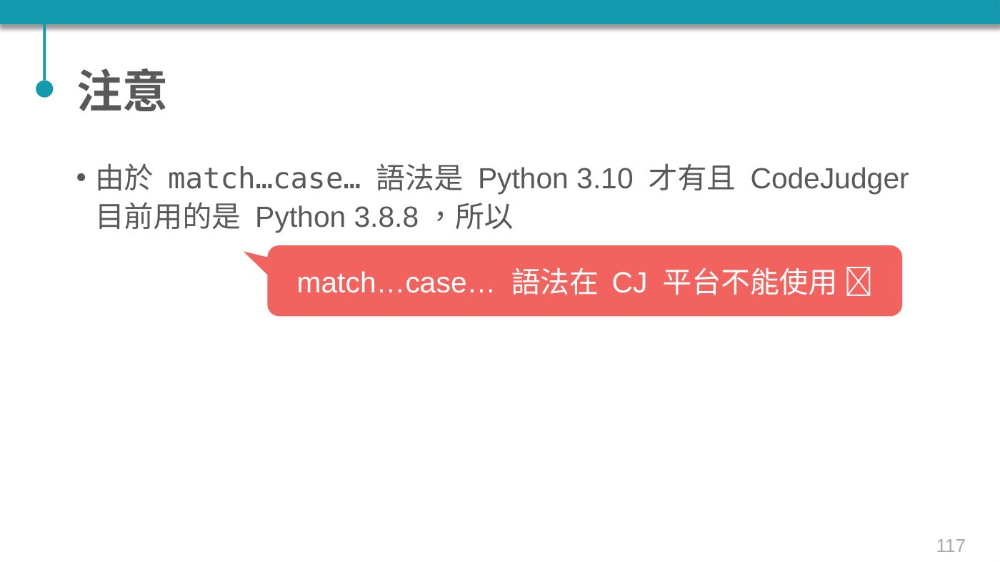

**講義文字（原稿轉錄）**

> 注意

> 由於 match…case… 語法是 Python 3.10 才有且 CodeJudger 目前用的是 Python 3.8.8，所以

> match…case… 語法在 CJ 平台不能使用 

#### match/case 與版本

Python 3.10 以上支援結構模式比對。原簡報對 CodeJudger 3.8.8 的限制屬當時平台資訊，不是 Colab 的固定限制。原第 116 頁把 70 分列為乙等、60 分列為丙等，與第107頁分界不同；以下明確沿用第116頁並驗證。

In [102]:
def match_grade(score):
    if not 0<=score<=100:
        return '輸入錯誤'
    match int(score//10):
        case 10 | 9:
            return '優等'
        case 8:
            return '甲等'
        case 7:
            return '乙等'
        case _:
            return '丙等'
for s in [100,90,80,70,60,-1,101]:
    print(s,match_grade(s))
assert match_grade(60)=='丙等'

100 優等
90 優等
80 甲等
70 乙等
60 丙等
-1 輸入錯誤
101 輸入錯誤


## 課後檢核

- 已完成原講義 **117/117 頁**的圖片與文字閱讀。
- 逐題先作答，再對照解答；為每題至少改兩組輸入，包含邊界值。
- 關閉互動模式，重新啟動核心並全部執行，確認沒有依賴先前核心的隱藏變數。
- 以「檔案 → 下載 → 下載 .ipynb」保存自己的版本與執行結果。

**參考來源**：使用者提供之《第二週講義PPTX.pptx》；Python 語法與內建函式可參閱 https://docs.python.org/zh-tw/3/ 。本檔的勘誤、輸入輔助與測試屬教學補充。
